# Predictive Forecasting of Care Load & Placement Demand
### HHS Unaccompanied Alien Children (UAC) Program: from historical reporting to predictive intelligence

**Unified Mentor Data Science Internship, October 2026** · notebook version 2.0 (validated and extended; the v1 baseline is preserved in `archive/v1_baseline_2026-10-05/`, every change is listed in `CHANGELOG.md`)

| Planning question | What this notebook delivers |
|---|---|
| How many children will be in HHS care in the coming days or weeks? | 1–28 day care-load forecasts with calibrated 80% / 95% intervals |
| Will discharges keep pace with incoming transfers? | Discharge and transfer forecasts, plus the net-pressure (imbalance) outlook |
| When should shelters, medical staff and caseworkers be scaled up? | Capacity-breach probabilities, surge lead time, and what-if scenarios |

**Roadmap**
1. Setup & configuration
2. Load the raw data, with **schema validation** (clear errors for malformed files)
3. Clean & type the data, with **plausibility validation** (impossible values quarantined, never zero-filled)
4. **Root-cause analysis (RCA) of data quality**: cadence, stale values, copied records, stock-flow identity, variable definitions
5. Time-series preparation: daily continuity, interpolation **and** masking
6. Exploratory analysis: regime break, length of stay, seasonality, interpolation check, monthly pattern, outliers, correlations, decomposition, stationarity
7. Feature engineering: lags, rolling mean/variance, net pressure, calendar and holiday effects, **per-feature leakage audit**
8. Train–test design: strict time order, walk-forward, multi-horizon, leakage guards, origin-time checks
9. Forecasting models: naive, seasonal naive, moving average, ARIMA/SARIMA, ETS, Random Forest, Gradient Boosting, Ensemble (model cards and fallback)
10. Walk-forward backtest
11. Evaluation: MAE, RMSE, MAPE, WAPE, bias, horizon error, statistical vs ML, ARIMA vs SARIMA, recursive vs direct
12. Uncertainty quantification: conformal intervals, coverage by horizon, rolling-origin recalibration
13. KPIs: accuracy, surge lead time, breach probability, stability, robustness
14. Production forecast to mid-January 2026
15. Scenario analysis (stock-flow what-ifs)
16. Export artifacts for the Streamlit dashboard
17. Insights & recommendations

**How to read this notebook:** every chart, table and printed result is followed by an **Observation** cell that states the key finding in plain language, with the supporting numbers.

### Brainstorm: what can go wrong, and how this notebook guards against it

Before writing any model I listed the ways a forecast for this program could quietly fail. Every guard below is implemented and checked later in the notebook.

| Risk | Why it matters | Guard used here |
|---|---|---|
| Malformed or implausible input on a refresh | A broken export or a typo (negative count, extra digit) silently drives forecasts and alerts | Schema validation with clear errors; impossible values quarantined to *missing* and listed |
| Irregular reporting (no Friday/Saturday reports) | Breaks daily continuity; naive interpolation leaks *future* values into features | Daily grid + time interpolation **plus** an `is_reported` mask; forecast origins and scored targets are reported days only |
| Copied or stale records | Silent corruption teaches models patterns that never happened | Duplicate-record audit + **stock-flow identity** test (care load must reconcile with in/out flows) |
| Structural break (2025 policy shift) | A model fitted on 2023–24 volumes forecasts a world that no longer exists | Change-point detection, regime-aware training windows, scale-free ML targets |
| Small counts and zero days | MAPE explodes when actuals are near 0 | WAPE-based accuracy KPI; MAPE computed on non-zero actuals |
| Over-optimistic validation | Random splits leak the future into training | Strict time split, walk-forward origins, model selection on a calibration window, reporting on an untouched test window |
| Point forecasts treated as certain | Capacity is planned on the tail, not the mean | Horizon-specific conformal intervals with measured coverage, breach probabilities |

## 1. Setup & configuration

In [1]:
# Core libraries for data handling, statistics, machine learning and plotting
import json, os, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy import stats
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
# Project paths (portable): UAC_BASE_DIR if set, else the first folder (working directory or a parent) that holds the raw CSV
DATA_FILE = "HHS_Unaccompanied_Alien_Children_Program.csv"
_candidates = [Path(os.environ["UAC_BASE_DIR"])] if os.environ.get("UAC_BASE_DIR") else [Path.cwd(), *Path.cwd().parents]
BASE_DIR = next((p for p in _candidates if (p / DATA_FILE).exists()), Path.cwd())
DATA_PATH = BASE_DIR / DATA_FILE
ART_DIR, FIG_DIR = BASE_DIR / "artifacts", BASE_DIR / "figures"
ART_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
print(f"Project folder: {BASE_DIR.name} | data file found: {DATA_PATH.exists()}")

Project folder: UnifiedMentor Internship_October 2026 | data file found: True


**Observation:** The project folder was found from the working directory and the data file is present, so the notebook no longer depends on a personal absolute path; setting `UAC_BASE_DIR` points it at another folder that holds the same CSV.

In [3]:
# Global settings: forecast horizon (days), random seed, and the three series we forecast
H = 28                     # 4-week planning horizon = four full weekly cycles (30 days would add a partial week and is not validated)
SEED = 42
TARGETS = {"hhs_care": "stock", "discharged": "flow", "transferred": "flow"}   # stock = level, flow = daily count
LABELS = {"hhs_care": "Children in HHS care", "discharged": "Discharges from HHS (placements)",
          "transferred": "Transfers into HHS (from CBP)", "apprehended": "Apprehended (CBP intake)",
          "cbp_custody": "Children in CBP custody"}

In [4]:
# Plot style: quiet chrome, hairline grids, and one fixed colour per entity (colour follows the series/model, never its rank)
INK, INK2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASE,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.labelcolor": INK2,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
                     "lines.linewidth": 2, "lines.solid_capstyle": "round", "font.size": 10,
                     "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
SERIES_COLORS = {"hhs_care": "#2a78d6", "transferred": "#eb6834", "discharged": "#1baf7a",
                 "apprehended": "#eda100", "cbp_custody": "#e87ba4"}
MODEL_COLORS = {"Naive": "#2a78d6", "Seasonal Naive (7d)": "#8a5a2b", "Moving Avg (7d)": "#eb6834", "SARIMA": "#1baf7a", "ETS": "#eda100",
                "Random Forest": "#e87ba4", "Gradient Boosting": "#008300", "Ensemble": "#4a3aa7"}
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
COMMA = mticker.StrMethodFormatter("{x:,.0f}")


def savefig(fig, name):
    """Save a figure into figures/ so the research paper can reuse it."""
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 2. Load the raw data

In [5]:
# Read the CSV; thousands="," turns quoted values such as "2,484" into numbers (a missing file stops with a clear message)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Input file not found: {DATA_PATH.name} in {DATA_PATH.parent}. Place {DATA_FILE} in the project folder or set UAC_BASE_DIR.")
raw = pd.read_csv(DATA_PATH, thousands=",")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (1170, 6)


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,2484.0,14.0
1,"December 18, 2025",11.0,50.0,6.0,2472.0,16.0
2,"December 17, 2025",7.0,31.0,11.0,2481.0,10.0
3,"December 16, 2025",8.0,54.0,15.0,2468.0,9.0
4,"December 15, 2025",11.0,42.0,9.0,2470.0,7.0


**Observation:** The raw file loads as 1,170 rows × 6 columns, newest report first (21 Dec 2025: 2,484 children in HHS care, 14 discharges). The thousand separators parsed correctly, so all five measures arrive as numbers rather than text.

In [6]:
# Audit the raw file: data types, fully blank rows (export padding), and missing cells
print(raw.dtypes, "\n")
print("Fully blank rows:", int(raw.isna().all(axis=1).sum()))
print("Rows with any value:", int(raw.notna().any(axis=1).sum()))

Date                                                object
Children apprehended and placed in CBP custody*    float64
Children in CBP custody                            float64
Children transferred out of CBP custody            float64
Children in HHS Care                               float64
Children discharged from HHS Care                  float64
dtype: object 

Fully blank rows: 450
Rows with any value: 720


**Observation:** Only 720 of the 1,170 rows (62%) contain data; the other 450 are empty export padding and must be dropped. Dates are stored as text such as "December 21, 2025", rows run newest-first, and one header carries a stray "*", so the file needs cleaning before any time-series work.

### 2.1 Schema validation

A refreshed export can arrive broken: a missing column, a header-only file, text in a count column, a different date format. The checks below stop the run **early with a message that names the column, file line and value**, instead of a raw pandas error several sections later. Policy:

| Check | Rule | On failure |
|---|---|---|
| Columns | 6 columns in the documented order (matched by a key phrase per position); extra trailing columns are ignored and reported | stop |
| Rows | at least one data row; at least 365 reports (training + two 13-week evaluation windows) | stop |
| Dates | documented format ("December 21, 2025"); ISO `YYYY-MM-DD` accepted as a reported fallback; timestamps or other text rejected | stop |
| Numbers | thousands separators and spaces allowed; blank / `N/A` = missing; any other text rejected | stop |
| Columns with no values, constant targets, non-daily cadence (median gap > 3 days) | nothing meaningful to forecast | stop |

In [7]:
# Schema validation: stop early with a clear message naming the column, file line and value
class DataValidationError(ValueError):
    """The input file cannot be used safely; the message says what to fix."""


COLS = ["date", "apprehended", "cbp_custody", "transferred", "hhs_care", "discharged"]
CBP_COLS = ["apprehended", "cbp_custody", "transferred"]
EXPECTED_HEADER_KEYS = ["date", "apprehended", "in cbp custody", "transferred", "in hhs care", "discharged"]   # one key phrase per position
MISSING_MARKERS = {"", "NAN", "N/A", "NA", "NULL", "NONE"}
MIN_REPORTS = 365


def validate_schema(frame):
    """Check columns, rows, dates and numbers; return (typed frame with snake_case names, list of notes)."""
    notes = []
    if frame.shape[1] < len(COLS):
        raise DataValidationError(f"Expected {len(COLS)} columns, found {frame.shape[1]}: {list(frame.columns)}")
    heads = [str(c).replace("﻿", "").replace("*", "").strip().lower() for c in frame.columns]
    for i, key in enumerate(EXPECTED_HEADER_KEYS):
        if key not in heads[i]:
            raise DataValidationError(f"Column {i + 1} is '{frame.columns[i]}'; expected a header containing '{key}'")
    if frame.shape[1] > len(COLS):
        notes.append(f"ignored extra column(s) {list(frame.columns[len(COLS):])}")
    data = frame.iloc[:, :len(COLS)].dropna(how="all").set_axis(COLS, axis=1).copy()
    if data.empty:
        raise DataValidationError("The file has a header but no data rows")
    for c in COLS:
        if data[c].isna().all():
            raise DataValidationError(f"Column '{c}' is entirely empty")
    txt = data["date"].astype(str).str.strip()
    primary = pd.to_datetime(txt, format="%B %d, %Y", errors="coerce")
    iso = pd.to_datetime(txt, format="%Y-%m-%d", errors="coerce")
    if (primary.isna() & iso.notna()).any():
        notes.append(f"{int((primary.isna() & iso.notna()).sum())} date(s) in ISO format accepted")
    data["date"] = primary.fillna(iso)
    if data["date"].isna().any():
        bad = [(int(i) + 2, txt[i]) for i in data.index[data["date"].isna()][:5]]          # file line = index + 2 (header is line 1)
        raise DataValidationError(f"{int(data['date'].isna().sum())} unparseable date(s), e.g. (file line, value): {bad}")
    for c in COLS[1:]:
        if data[c].dtype == object:
            s = data[c].astype(str).str.replace(",", "", regex=False).str.strip()
            num = pd.to_numeric(s, errors="coerce")
            text = num.isna() & data[c].notna() & ~s.str.upper().isin(MISSING_MARKERS)
            if text.any():
                bad = [(int(i) + 2, data.at[i, c]) for i in data.index[text][:5]]
                raise DataValidationError(f"Column '{c}' has {int(text.sum())} non-numeric value(s), e.g. (file line, value): {bad}")
            data[c] = num
    data[COLS[1:]] = data[COLS[1:]].astype(float)
    if len(data) < MIN_REPORTS:
        raise DataValidationError(f"Only {len(data)} reports; at least {MIN_REPORTS} are needed for training plus the calibration and test windows")
    median_gap = data["date"].sort_values().diff().dt.days.median()
    if median_gap > 3:
        raise DataValidationError(f"Median gap between reports is {median_gap:.0f} days: this is not a daily series")
    for c in TARGETS:
        if data[c].nunique() <= 1:
            raise DataValidationError(f"Target '{c}' is constant ({data[c].dropna().iloc[0]:g}): nothing to forecast; check the export")
    return data, notes

## 3. Clean & type the data

In [8]:
# Validated, typed table with short snake_case names (the original meaning is kept in LABELS)
df, SCHEMA_NOTES = validate_schema(raw)
print(f"Schema valid: {len(df)} data rows × {df.shape[1]} columns | notes: {SCHEMA_NOTES or 'none'}")

Schema valid: 720 data rows × 6 columns | notes: none


**Observation:** The source file passes every schema check unchanged: 720 data rows × 6 columns, every date in the documented "Month DD, YYYY" format, every count numeric, and no notes (no extra columns, no ISO dates). The same checks stop a malformed refresh with a readable message; the negative cases (missing or renamed column, header-only file, text in a count, invalid dates, time-zone timestamps, empty or constant columns, short or weekly histories) are exercised on synthetic files in `QA_Testing/`.

In [9]:
# Sort oldest to newest (stable sort), resolve duplicate dates, and use the date as the index
dup_rows = df[df["date"].duplicated(keep=False)]
DUP_CONFLICTS = dup_rows.groupby("date").filter(lambda g: len(g.drop_duplicates()) > 1)      # same date, different values
if len(DUP_CONFLICTS):
    print("Conflicting records for the same date (the first record in file order is kept):"); display(DUP_CONFLICTS)
n_dupes = int(df["date"].duplicated().sum())
df = df.sort_values("date", kind="stable").drop_duplicates("date", keep="first").set_index("date").astype(float)
print(f"Duplicate dates removed: {n_dupes} | Rows: {len(df)} | Range: {df.index.min():%d %b %Y} → {df.index.max():%d %b %Y}")
df.describe().T.round(1)

Duplicate dates removed: 0 | Rows: 720 | Range: 12 Jan 2023 → 21 Dec 2025


,count,mean,std,min,25%,50%,75%,max
apprehended,720.0,93.5,72.6,0.0,12.0,99.0,147.2,333.0
cbp_custody,720.0,171.5,126.4,7.0,36.0,193.0,263.2,531.0
transferred,720.0,128.7,97.3,0.0,14.0,157.0,199.2,440.0
hhs_care,720.0,6061.3,2833.1,1972.0,2467.8,6406.5,8010.2,11516.0
discharged,720.0,173.4,125.7,0.0,19.8,181.0,267.0,505.0


**Observation:** The clean table has 720 daily reports from 12 Jan 2023 to 21 Dec 2025, with no duplicate dates. Care load ranged almost 6-fold, from 1,972 to 11,516 children, and its standard deviation (2,833) is almost half its mean (6,061). The data therefore span very different operating levels, which the regime analysis below confirms.

### 3.1 Plausibility validation

Schema-valid numbers can still be impossible. Values that cannot be true are **quarantined**: set to *missing* (so they are re-estimated by interpolation and never scored) and listed, never replaced by zero. Values that are only unusual are **flagged for review** and left unchanged.

| Rule | Applies to | Action |
|---|---|---|
| Negative count | all five columns | quarantine |
| Single-report stock spike: care load more than 1.5× (or less than 1/1.5) the median of the 3 reports before and after | `hhs_care` | quarantine |
| Non-integer count | all five columns | flag |
| Flow spike: more than 5× the local 15-report median and more than 50 above it | flows and CBP custody | flag |

On the real data the largest care-load deviation from its neighbours is ×1.11 and the largest flow ratio is 3.2×, so these limits sit far outside normal variation.

In [10]:
# Plausibility validation: impossible values are quarantined (set to missing and listed); unusual values are flagged only
def validate_values(frame, stock_ratio=1.5, flow_ratio=5.0, flow_abs=50):
    out, issues = frame.copy(), []
    def log_issue(mask, col, rule, action):
        issues.extend({"date": d, "column": col, "value": frame.at[d, col], "rule": rule, "action": action} for d in out.index[mask])
    for c in out.columns:
        neg = out[c] < 0
        log_issue(neg, c, "negative count", "quarantined (set to missing)")
        out.loc[neg, c] = np.nan
        log_issue(out[c].notna() & (out[c] % 1 != 0), c, "non-integer count", "flagged for review")
    care = out["hhs_care"]
    ref = pd.concat([care.shift(k) for k in (1, 2, 3, -1, -2, -3)], axis=1).median(axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        spike = (np.abs(np.log(care / ref)) > np.log(stock_ratio)) & care.notna() & ref.notna()
    log_issue(spike, "hhs_care", f"stock spike (> {stock_ratio}x or < 1/{stock_ratio}x neighbouring reports)", "quarantined (set to missing)")
    out.loc[spike, "hhs_care"] = np.nan
    for c in ("apprehended", "cbp_custody", "transferred", "discharged"):
        local = out[c].rolling(15, center=True, min_periods=5).median()
        log_issue((out[c] > flow_ratio * local) & (out[c] - local > flow_abs), c, f"flow spike (> {flow_ratio:g}x local median)", "flagged for review")
    return out, pd.DataFrame(issues, columns=["date", "column", "value", "rule", "action"])


df, VALIDATION_ISSUES = validate_values(df)
print(f"Plausibility issues: {len(VALIDATION_ISSUES)} (quarantined: {VALIDATION_ISSUES['action'].str.startswith('quarantined').sum()})")
VALIDATION_ISSUES if len(VALIDATION_ISSUES) else print("No implausible values: the source data pass every rule unchanged.")

Plausibility issues: 0 (quarantined: 0)
No implausible values: the source data pass every rule unchanged.


**Observation:** No value in the source data breaks a plausibility rule: no negative or fractional count, no single-report care-load spike and no flow spike, so nothing is quarantined and every later result is identical to the unvalidated pipeline. The rules protect future refreshes: in the synthetic tests a −5 discharge count and a 99,999 care load are set to missing and listed, while a genuine, lasting +40% level shift is left untouched.

## 4. Root-cause analysis of data quality

The brief calls this "high-quality daily data". Before trusting it I tested four things: reporting cadence, stale values, duplicated records, and whether the stock and flow columns reconcile.

### 4.1 Reporting cadence: which days are actually reported?

In [11]:
# Count reports per weekday and the gaps (in days) between consecutive reports
dow_counts = df.index.day_name().value_counts().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], fill_value=0)
gaps = df.index.to_series().diff().dt.days
print("Reports per weekday:\n", dow_counts.to_string(), "\n")
print("Gap between reports (days):\n", gaps.value_counts().sort_index().to_string())

Reports per weekday:
 date
Monday       145
Tuesday      149
Wednesday    147
Thursday     147
Friday         2
Saturday       0
Sunday       130 

Gap between reports (days):
 date
1.0     558
2.0      10
3.0     122
4.0      23
5.0       3
6.0       1
7.0       1
10.0      1


**Observation:** Monday–Thursday and Sunday each have 130–149 reports, while Friday has only 2 and Saturday none. 77% of gaps between reports are 1 day, but 17% are 3-day Thursday→Sunday jumps, so weekend values are missing by design, not at random.

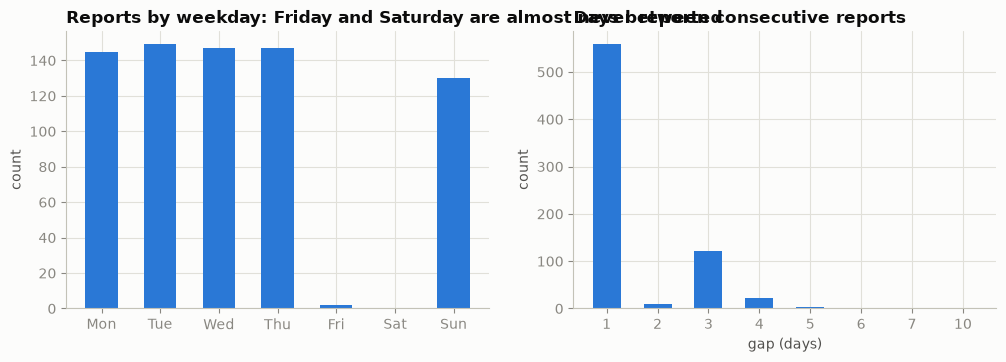

In [12]:
# Visualise the cadence: weekday coverage and the gap distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(dow_counts.index.str[:3], dow_counts.values, width=0.55, color=SERIES_COLORS["hhs_care"])
axes[0].set_title("Reports by weekday: Friday and Saturday are almost never reported")
gap_vc = gaps.value_counts().sort_index()
axes[1].bar(gap_vc.index.astype(int).astype(str), gap_vc.values, width=0.55, color=SERIES_COLORS["hhs_care"])
axes[1].set_title("Days between consecutive reports"); axes[1].set_xlabel("gap (days)")
for ax in axes: ax.set_ylabel("count")
savefig(fig, "01_reporting_cadence")

**Observation:** The chart confirms a fixed Sunday–Thursday reporting cycle: about a third of calendar days (355 of 1,075) have no report. Because the gaps are structural, interpolated weekend values are estimates only. They keep the series continuous for features, but they are masked from every forecast score.

### 4.2 Stale (carried-forward) values

In [13]:
# A report whose care load AND discharges exactly repeat the previous report is a likely copy-forward
stale_mask = (df["hhs_care"].diff() == 0) & (df["discharged"].diff() == 0)
print("Stale HHS reports:", int(stale_mask.sum()))
df.loc[stale_mask | stale_mask.shift(-1, fill_value=False), ["hhs_care", "discharged", "transferred"]]

Stale HHS reports: 5


,hhs_care,discharged,transferred
date,,,
2024-01-07,9670.0,367.0,136.0
2024-01-08,9670.0,367.0,117.0
2024-02-25,8404.0,329.0,366.0
2024-02-26,8404.0,329.0,326.0
2024-06-24,7239.0,202.0,172.0
2024-06-25,7239.0,202.0,191.0
2025-03-26,2159.0,2.0,15.0
2025-03-27,2159.0,2.0,13.0
2025-05-13,2394.0,11.0,12.0


**Observation:** 5 reports repeat the previous day's care load and discharges exactly (e.g., 8,404 children and 329 discharges on both 25 and 26 Feb 2024), while their CBP transfers changed (366 vs 326). A double exact repeat alongside changing transfers points to a carry-forward rather than a fresh report, so these values are re-estimated by interpolation and never used as a scored target.

In [14]:
# Treat stale HHS values as missing so they are re-estimated by interpolation and never used as a scored target
df.loc[stale_mask, ["hhs_care", "discharged"]] = np.nan

### 4.3 Duplicated CBP records: the key root-cause finding

In [15]:
# Each CBP row is a triple (apprehended, in custody, transferred); identical triples on different dates are extremely unlikely
cbp_key = df[CBP_COLS].astype("Int64").astype(str).agg("-".join, axis=1)
repeats = cbp_key.map(cbp_key.value_counts())
print(f"Rows whose CBP triple appears on 2+ different dates: {(repeats > 1).sum()} of {len(df)}")
cbp_key.value_counts().head(5)

Rows whose CBP triple appears on 2+ different dates: 374 of 720


56-82-68      5
74-103-80     5
68-107-102    5
92-124-93     5
33-53-34      5
Name: count, dtype: int64

**Observation:** 374 of 720 reports (52%) share an identical (apprehended, in custody, transferred) triple with another date, and five triples appear five times each. Exact three-number matches at these volumes are very unlikely by chance, so this is strong evidence of copied records.

In [16]:
# Flag the earlier copy of every repeated triple; the longest contiguous run marks the corrupted window
is_copy = cbp_key.duplicated(keep="last")
run_id = (is_copy != is_copy.shift()).cumsum()
runs = is_copy.groupby(run_id).agg(["first", "size"])
MIN_COPY_RUN = 14                                                              # isolated chance repeats at low counts are not a copied block
if runs["first"].any() and runs.loc[runs["first"], "size"].max() >= MIN_COPY_RUN:
    longest = runs[runs["first"]]["size"].idxmax()
    CBP_BAD_START, CBP_BAD_END = is_copy[run_id == longest].index.min(), is_copy[run_id == longest].index.max()
    N_COPIED = int(runs.loc[longest, "size"])
else:                                                                          # clean refresh: no copied block, nothing to mask
    longest, N_COPIED = None, 0
    CBP_BAD_START = CBP_BAD_END = df.index.min() - pd.Timedelta(days=1)
print(f"Contiguous copied block: {CBP_BAD_START:%d %b %Y} → {CBP_BAD_END:%d %b %Y} ({N_COPIED} reports)")
print("Share of copied CBP rows by year:\n", is_copy.groupby(df.index.year).mean().round(2).to_string())

Contiguous copied block: 12 Jan 2023 → 30 Jan 2024 (251 reports)
Share of copied CBP rows by year:
 date
2023    1.00
2024    0.08
2025    0.00


**Observation:** The copies form one unbroken block of 251 reports, from 12 Jan 2023 to 30 Jan 2024. 100% of 2023 CBP rows are copies, falling to 8% in 2024 (January only) and 0% in 2025. The problem is confined to one period, so CBP data from February 2024 onward remain usable.

In [17]:
# Show one concrete example: the same triple reported on five different dates
example = cbp_key.value_counts().index[0]
df.loc[cbp_key == example, CBP_COLS + ["hhs_care", "discharged"]]

,apprehended,cbp_custody,transferred,hhs_care,discharged
date,,,,,
2023-06-01,56.0,82.0,68.0,7002.0,287.0
2023-10-15,56.0,82.0,68.0,10571.0,434.0
2023-11-27,56.0,82.0,68.0,10123.0,214.0
2023-12-26,56.0,82.0,68.0,11217.0,288.0
2025-01-09,56.0,82.0,68.0,5507.0,164.0


**Observation:** The same CBP triple (56, 82, 68) appears on five dates spread over 19 months, each time beside a completely different HHS care load (5,507 to 11,217). Identical intake numbers in such different situations confirm the CBP values were copied rather than reported.

### 4.4 Proof via the stock-flow identity

Care load is a **stock** and transfers/discharges are **flows**, so on consecutive days:

$$\text{HHS}_t - \text{HHS}_{t-1} \;\approx\; \text{Transfers}_t - \text{Discharges}_t$$

If a column is corrupted, this identity breaks. I test it separately for the copied block and the trusted period.

In [18]:
# Compute the identity residual on consecutive-day pairs only (multi-day gaps hide unreported flows)
sf = df.copy()
sf["gap"] = sf.index.to_series().diff().dt.days
sf["d_care"] = sf["hhs_care"].diff()
sf["net_flow"] = sf["transferred"] - sf["discharged"]
sf["residual"] = sf["d_care"] - sf["net_flow"]
sf["period"] = np.where(sf.index <= CBP_BAD_END, "Copied CBP block (2023–Jan 2024)", "Trusted (Feb 2024 →)")
pairs = sf[(sf["gap"] == 1) & sf["residual"].notna()]
identity = pairs.groupby("period").apply(lambda g: pd.Series({
    "pairs": len(g), "corr(ΔHHS, net flow)": g["d_care"].corr(g["net_flow"]),
    "mean residual / day": g["residual"].mean(), "median |residual|": g["residual"].abs().median()})).round(2)
identity

,pairs,"corr(ΔHHS, net flow)",mean residual / day,median |residual|
period,,,,
Copied CBP block (2023–Jan 2024),192.0,0.51,190.40,182.0
Trusted (Feb 2024 →),357.0,0.90,2.58,6.0


**Observation:** In the trusted period the daily change in care load tracks recorded transfers minus discharges closely (correlation 0.90, typical gap 6 children). In the copied block the match collapses (correlation 0.51) and about 190 children per day go unexplained. The HHS columns reconcile only where the CBP data are genuine, which pinpoints the CBP columns as the corrupted part.

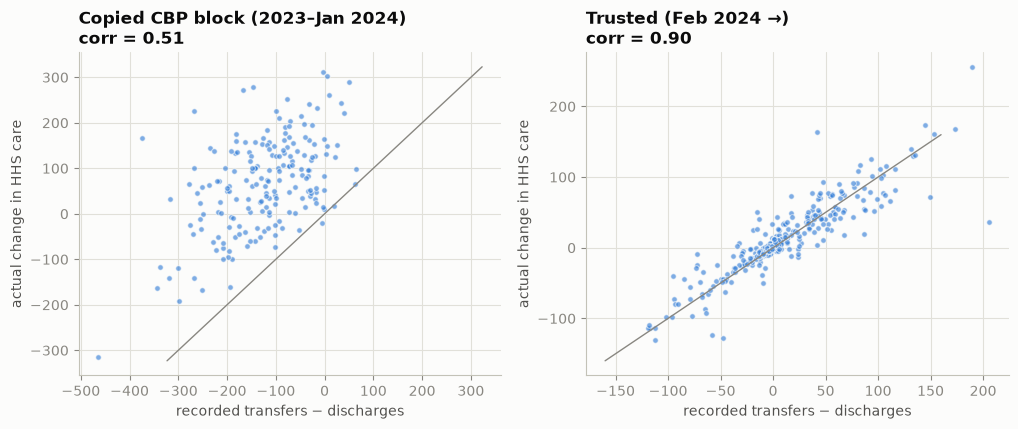

In [19]:
# Scatter of daily care-load change vs recorded net flow: points should sit on the 45° line if the data reconcile
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=False)
for ax, (name, g) in zip(axes, pairs.groupby("period")):
    ax.scatter(g["net_flow"], g["d_care"], s=16, color=SERIES_COLORS["hhs_care"], alpha=0.6, edgecolor=SURFACE, linewidth=0.8)
    lim = np.nanpercentile(np.abs(np.r_[g["net_flow"], g["d_care"]]), 99)
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=1)
    ax.set_title(f"{name}\ncorr = {g['d_care'].corr(g['net_flow']):.2f}")
    ax.set_xlabel("recorded transfers − discharges"); ax.set_ylabel("actual change in HHS care")
savefig(fig, "02_stock_flow_identity")

**Observation:** Trusted-period points hug the 45° line, while copied-block points sit mostly above it: care load rose far more than the recorded flows allow. The visual gap matches the +190 children/day residual and shows that the copied transfers understate real admissions.

In [20]:
# Implied admissions = ΔHHS + discharges uses only HHS columns; compare with recorded CBP transfers by quarter
pairs = pairs.assign(implied_admissions=pairs["d_care"] + pairs["discharged"])
q = pairs.groupby(pairs.index.to_period("Q"))[["implied_admissions", "transferred"]].mean().round(0)
q["recorded / implied"] = (q["transferred"] / q["implied_admissions"]).round(2)
q

,implied_admissions,transferred,recorded / implied
date,,,
2023Q1,338.0,142.0,0.42
2023Q2,281.0,160.0,0.57
2023Q3,401.0,189.0,0.47
2023Q4,391.0,131.0,0.34
2024Q1,274.0,234.0,0.85
2024Q2,235.0,236.0,1.00
2024Q3,185.0,180.0,0.97
2024Q4,192.0,190.0,0.99
2025Q1,39.0,36.0,0.92


**Observation:** Admissions implied by the HHS columns alone ran at 281–401 a day in 2023, but recorded transfers captured only 34–57% of them. From Q2 2024 the ratio is 0.97–1.00. In 2025 it is 0.67–0.92 at very low volumes, a gap of only about 2–4 children a day, consistent with small non-CBP referrals. **Conclusion:** the January 2023 – January 2024 CBP columns are corrupted and are masked. The HHS columns reconcile wherever they can be checked (February 2024 onward) and, apart from the 5 stale reports, are kept for the whole history; they cannot be cross-checked inside the copied block itself.

**RCA decision log**

| Issue | Evidence | Fix |
|---|---|---|
| 450 blank padding rows | `isna().all()` | Dropped |
| Newest-first, text dates, comma numbers | Raw preview | Parsed, sorted, typed |
| Fri/Sat never reported | Weekday counts | Daily grid + interpolation, with an `is_reported` mask for scoring |
| 5 stale carried-forward HHS reports | Exact repeats | Set to missing → interpolated, never scored |
| CBP columns copied, Jan 2023–Jan 2024 | Duplicate triples + broken identity | CBP columns masked in that window; ML features use the trusted window only |
| HHS columns | Reconcile with flows where CBP is trusted | Kept for the full history (used for EDA and the surge replay) |
| Duplicate dates (none today) | Stable sort + conflict listing | Identical repeats dropped; for conflicting repeats the first record in file order is kept and printed (an assumption: the file carries no revision timestamp) |
| Impossible values on a refresh (none today) | Plausibility rules (§3.1) | Quarantined to missing and listed; never zero-filled |

**What each column measures (domain definitions supported by the file)**

| Column | Type | Meaning | Role in the HHS population balance |
|---|---|---|---|
| `hhs_care` | stock (snapshot on the report day) | children in HHS care | closing population |
| `transferred` | daily count | children transferred out of CBP custody **into HHS** | admissions from CBP (one movement, counted once) |
| `discharged` | daily count | children discharged from HHS care (mostly to sponsors) | exits |
| `apprehended` | daily count | children apprehended and placed in CBP custody | CBP intake, upstream; **not** part of the HHS balance |
| `cbp_custody` | stock | children in CBP custody | upstream pipeline |

The balance that can be tested is therefore *closing = opening + transfers in − discharges + (unrecorded other admissions − other exits)*. The file has no columns for non-CBP referrals, other exits or bed capacity, so the unexplained part is measured (§6 and §14) and reported as a reconciliation term rather than invented, and every capacity threshold in this notebook is a user input or an illustration.

## 5. Time-series preparation: continuity, interpolation **and** masking

In [21]:
# Re-index onto a continuous daily calendar; is_reported marks the days with a genuine (non-stale) HHS report
daily = df.asfreq("D")
daily["is_reported"] = daily["hhs_care"].notna() & daily["discharged"].notna()
daily["cbp_trusted"] = daily.index > CBP_BAD_END
daily.loc[~daily["cbp_trusted"], CBP_COLS] = np.nan          # mask the copied CBP block
OBSERVED = daily[["apprehended", "cbp_custody", "transferred", "hhs_care", "discharged"]].notna()   # genuine values per column, before any imputation
print(f"Calendar days: {len(daily)} | reported: {daily['is_reported'].sum()} | to impute: {(~daily['is_reported']).sum()}")

Calendar days: 1075 | reported: 715 | to impute: 360


**Observation:** The continuous calendar has 1,075 days: 715 (67%) hold a genuine, non-stale report and 360 (33%) must be imputed. One-third imputation is too much to treat interpolated values as real data, which is why every evaluation in this notebook scores reported days only.

In [22]:
# Time-weighted linear interpolation fills interior gaps only (no extrapolation at the ends)
value_cols = ["apprehended", "cbp_custody", "transferred", "hhs_care", "discharged"]
daily[value_cols] = daily[value_cols].interpolate(method="time", limit_area="inside")
daily["net_pressure"] = daily["transferred"] - daily["discharged"]           # flow-based imbalance signal
T_END = daily.index.max()
print("Remaining gaps after interpolation:\n", daily[value_cols].isna().sum().to_string())

Remaining gaps after interpolation:
 apprehended    384
cbp_custody    384
transferred    384
hhs_care         0
discharged       0


**Observation:** After interpolation the HHS care and discharge series are complete (0 gaps). The three CBP series keep exactly 384 missing days, the length of the masked copied block. These gaps are intentional, so corrupted values cannot reach the models.

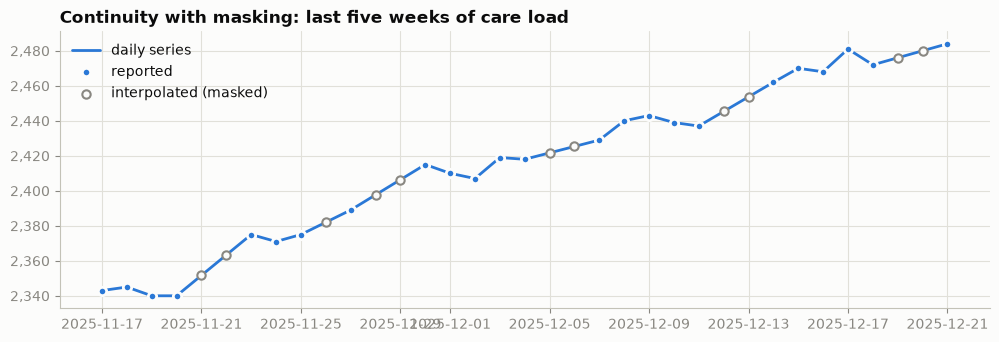

In [23]:
# Visual check on a recent month: interpolated weekend points sit on straight segments between real reports
win = daily.loc[T_END - pd.Timedelta(days=34):]
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(win.index, win["hhs_care"], color=SERIES_COLORS["hhs_care"], lw=2, label="daily series")
ax.scatter(win.index[win["is_reported"]], win.loc[win["is_reported"], "hhs_care"], s=36, color=SERIES_COLORS["hhs_care"], edgecolor=SURFACE, linewidth=2, zorder=3, label="reported")
ax.scatter(win.index[~win["is_reported"]], win.loc[~win["is_reported"], "hhs_care"], s=36, facecolor=SURFACE, edgecolor=MUTED, linewidth=1.5, zorder=3, label="interpolated (masked)")
ax.set_title("Continuity with masking: last five weeks of care load"); ax.yaxis.set_major_formatter(COMMA); ax.legend(loc="upper left")
savefig(fig, "03_interpolation_mask")

**Observation:** Over the last five weeks 24 days are real reports and 11 are interpolated: 10 Friday/Saturday days plus Wednesday 26 Nov, before Thanksgiving. They sit on straight lines between neighbouring reports. Care load climbed from 2,343 to 2,484 (+141) in this window, and the interpolation preserves that trend without inventing new peaks or dips.

**Leakage guard.** An interpolated Friday value is built from the following Sunday's report. If a forecast were issued "as of Friday", it would secretly know Sunday. So **every forecast origin is a reported day** and **every scored target is a reported day**. Interpolated days only fill the rolling-window features *between* reported days, which uses no information from after the origin.

## 6. Exploratory analysis

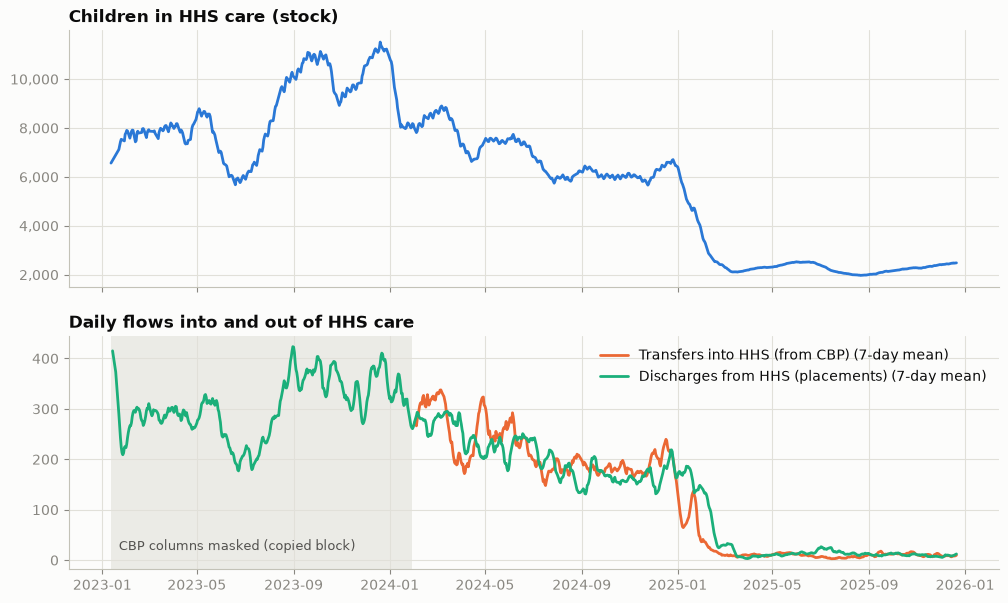

In [24]:
# Three years at a glance: the care-load stock and the three daily flows (small multiples, one shared time axis)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]})
axes[0].plot(daily.index, daily["hhs_care"], color=SERIES_COLORS["hhs_care"])
axes[0].set_title("Children in HHS care (stock)"); axes[0].yaxis.set_major_formatter(COMMA)
for c in ["transferred", "discharged"]:
    axes[1].plot(daily.index, daily[c].rolling(7, min_periods=3).mean(), color=SERIES_COLORS[c], label=LABELS[c] + " (7-day mean)")
axes[1].axvspan(daily.index.min(), CBP_BAD_END, color=GRID, alpha=0.6, lw=0)
axes[1].text(CBP_BAD_START + pd.Timedelta(days=10), 20, "CBP columns masked (copied block)", color=INK2, fontsize=9)
axes[1].set_title("Daily flows into and out of HHS care"); axes[1].legend(loc="upper right")
savefig(fig, "04_history_overview")

**Observation:** Care load peaked at 11,516 children (20 Dec 2023) and swung between about 5,700 and 11,500 through 2023–24. It then collapsed from 6,405 on 1 Jan 2025 to 2,111 by mid-March 2025, as daily transfers and discharges fell from hundreds a day to about 10. The history therefore contains two very different operating regimes that should not be modelled as one.

In [25]:
# Change-point detection: the single split that best separates two mean levels of log(flow)
def single_break(series, min_seg=60):
    """Return the date that minimises within-segment squared error of log1p(series) (binary segmentation, 1 split).
    Returns None when the series is too short for two segments of min_seg points; the caller decides what to do."""
    s = series.dropna(); y = np.log1p(s.to_numpy())
    if len(y) <= 2 * min_seg:
        return None
    sse = [((y[:k] - y[:k].mean()) ** 2).sum() + ((y[k:] - y[k:].mean()) ** 2).sum() for k in range(min_seg, len(y) - min_seg)]
    return s.index[min_seg + int(np.argmin(sse))]

reported = df.dropna(subset=["hhs_care"])
brk_transfers = single_break(reported.loc[reported.index > CBP_BAD_END, "transferred"])
brk_discharges = single_break(reported["discharged"])
if brk_transfers is None or brk_discharges is None:
    raise DataValidationError("History too short for change-point detection: each series needs more than 120 trusted reports")
REGIME_START = max(brk_transfers, brk_discharges) + pd.Timedelta(days=28)   # 4-week buffer while the backlog drains
print(f"Break in transfers: {brk_transfers:%d %b %Y} | break in discharges: {brk_discharges:%d %b %Y} | current regime starts: {REGIME_START:%d %b %Y}")

Break in transfers: 26 Jan 2025 | break in discharges: 17 Feb 2025 | current regime starts: 17 Mar 2025


**Observation:** The statistical break falls on 26 Jan 2025 for transfers and 17 Feb 2025 for discharges: intake dropped first, and placements followed about three weeks later. Models are trained on the current regime from 17 Mar 2025, after a four-week buffer for the backlog to drain.

In [26]:
# Quantify the regime shift: average daily volumes before vs after the break
pre = daily.loc[CBP_BAD_END:brk_transfers - pd.Timedelta(days=1)]
post = daily.loc[REGIME_START:]
shift = pd.DataFrame({"Feb 2024 – break": pre[["apprehended", "transferred", "discharged", "hhs_care"]].mean(),
                      "Current regime": post[["apprehended", "transferred", "discharged", "hhs_care"]].mean()})
shift["change %"] = (shift["Current regime"] / shift["Feb 2024 – break"] - 1) * 100
shift.round(1)

,Feb 2024 – break,Current regime,change %
apprehended,146.0,7.8,-94.7
transferred,209.9,9.6,-95.4
discharged,203.2,11.7,-94.3
hhs_care,6751.1,2261.8,-66.5


**Observation:** Daily intake, transfers and discharges all fell by about 95% (e.g., transfers 209.9 → 9.6 a day), but average care load fell only 66.5% (6,751 → 2,262). The census shrank far less than the flows, so children now stay much longer in care. That is the key change for planners.

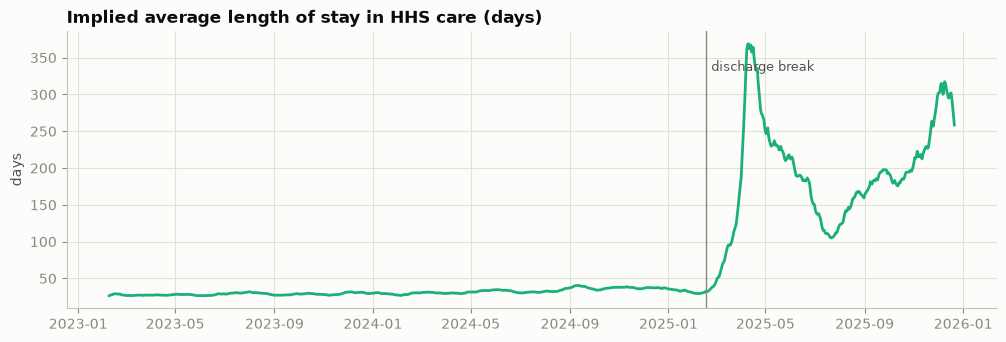

Implied stay: 36 days before the break vs 203 days in the current regime


In [27]:
# Little's law: average length of stay ≈ children in care ÷ daily discharges (28-day smoothing)
los = daily["hhs_care"].rolling(28).mean() / daily["discharged"].rolling(28).mean()
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(los.index, los, color=SERIES_COLORS["discharged"])
ax.axvline(brk_discharges, color=MUTED, lw=1); ax.text(brk_discharges + pd.Timedelta(days=6), los.max() * 0.9, "discharge break", color=INK2, fontsize=9)
ax.set_title("Implied average length of stay in HHS care (days)"); ax.set_ylabel("days")
savefig(fig, "05_length_of_stay")
print(f"Implied stay: {los.loc[:brk_discharges].tail(180).mean():.0f} days before the break vs {los.loc[REGIME_START:].mean():.0f} days in the current regime")

**Observation:** The implied average stay rose from about 36 days before the break to about 203 days in the current regime. It peaked at 369 days in April 2025 and stood at 258 days at the latest report. The bottleneck has moved from intake to placement: care load now depends mainly on how fast children are discharged to sponsors.

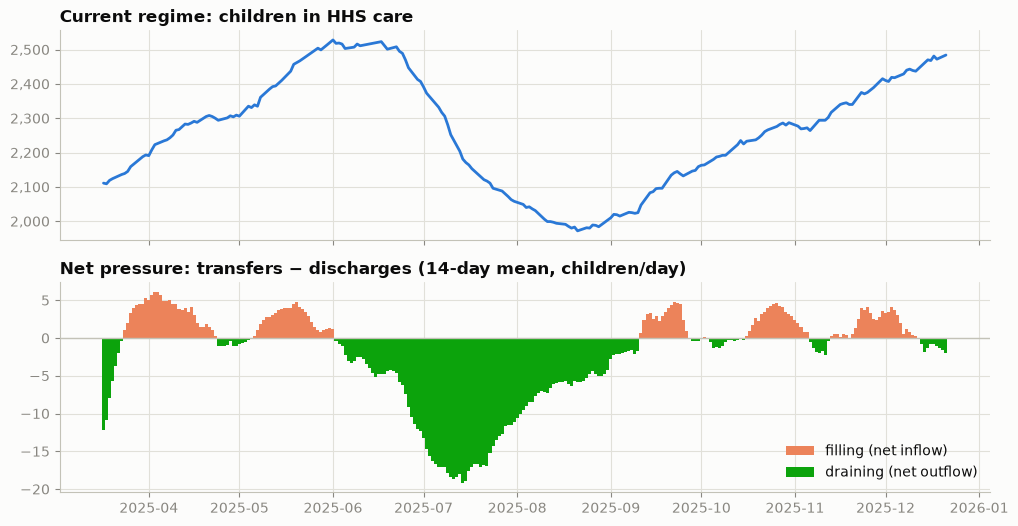

In [28]:
# Net pressure (transfers − discharges) is the leading indicator of care-load growth; positive values mean the system is filling
np28 = daily["net_pressure"].rolling(14, min_periods=7).mean()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
seg = daily.loc[REGIME_START:]
axes[0].plot(seg.index, seg["hhs_care"], color=SERIES_COLORS["hhs_care"]); axes[0].yaxis.set_major_formatter(COMMA)
axes[0].set_title("Current regime: children in HHS care")
vals = np28.loc[REGIME_START:]
axes[1].bar(vals.index, vals.clip(lower=0), width=1, color=STATUS["serious"], label="filling (net inflow)")
axes[1].bar(vals.index, vals.clip(upper=0), width=1, color=STATUS["good"], label="draining (net outflow)")
axes[1].axhline(0, color=BASE, lw=1); axes[1].legend(loc="lower right")
axes[1].set_title("Net pressure: transfers − discharges (14-day mean, children/day)")
savefig(fig, "06_net_pressure")

**Observation:** Net pressure explains the care-load path. A deep net outflow (down to −19 children/day in mid-July 2025) drove the fall from 2,528 (1 Jun) to 1,972 (21 Aug), and small net inflows since September (about +1/day on average) coincide with the climb to 2,484. Net pressure was positive on only 46% of days, so the system alternates between filling and draining. The recorded flows explain only part of the recent growth; the weekend analysis below accounts for the rest.

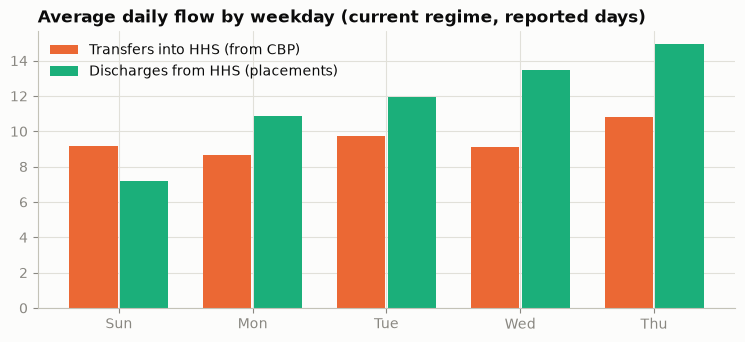

,transferred,discharged
date,,
Sun,9.2,7.2
Mon,8.7,10.9
Tue,9.7,11.9
Wed,9.1,13.5
Thu,10.8,14.9


In [29]:
# Weekly seasonality in the current regime: mean flow per weekday on reported days only
rep_post = daily.loc[REGIME_START:].query("is_reported")
order = ["Sun", "Mon", "Tue", "Wed", "Thu"]                                   # Fri/Sat are (almost) never reported
dow_tbl = rep_post.groupby(rep_post.index.day_name().str[:3])[["transferred", "discharged"]].mean().reindex(order)
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(order)); w = 0.36
for i, c in enumerate(["transferred", "discharged"]):
    ax.bar(x + (i - 0.5) * (w + 0.02), dow_tbl[c], width=w, color=SERIES_COLORS[c], label=LABELS[c])
ax.set_xticks(x, order); ax.set_title("Average daily flow by weekday (current regime, reported days)"); ax.legend(loc="upper left")
savefig(fig, "07_weekday_profile")
dow_tbl.round(1)

**Observation:** Discharges follow a clear weekly cycle: they peak on Thursday (14.9) and are lowest on Sunday (7.2), roughly half the Thursday level. Transfers are much flatter (8.7–10.8 a day). Placement activity is concentrated mid-week while arrivals are steady, which sets up the weekend pattern below.

In [30]:
# Where does care-load growth happen? Average change per day on weekday transitions vs across the unreported weekend
rep = daily.loc[daily["is_reported"], ["hhs_care"]].copy()
rep["gap"] = rep.index.to_series().diff().dt.days
rep["per_day"] = rep["hhs_care"].diff() / rep["gap"]
rep["transition"] = np.select([rep["gap"] == 1, (rep["gap"] == 3) & (rep.index.dayofweek == 6)],
                              ["weekday (consecutive reports)", "weekend (Thu → Sun)"], "other gap")
rep["period"] = np.select([rep.index >= REGIME_START, rep.index > CBP_BAD_END], ["3) current regime", "2) Feb 2024 – break"], "1) 2023 – Jan 2024")
WEEKEND = rep[rep["transition"] != "other gap"].pivot_table(index="period", columns="transition", values="per_day", aggfunc="mean").round(1)
WEEKEND

transition,weekday (consecutive reports),weekend (Thu → Sun)
period,,
1) 2023 – Jan 2024,66.8,-76.6
2) Feb 2024 – break,19.4,-64.5
3) current regime,-0.3,3.4


**Observation:** In the current regime care load falls slightly across weekday transitions (−0.3/day) but rises by +3.4/day across each Thursday→Sunday gap. In 2023–24 the pattern was the reverse (weekdays +19 to +67/day, weekends −65 to −77/day), so weekend dynamics changed with the regime.

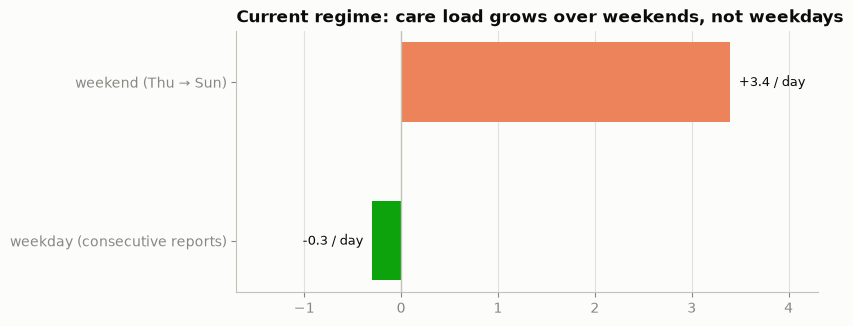

In [31]:
# Chart the weekend ratchet in the current regime (children added per calendar day)
cur = WEEKEND.loc["3) current regime"]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(cur.index, cur.values, height=0.5, color=[STATUS["good"] if v < 0 else STATUS["serious"] for v in cur.values])
for i, v in enumerate(cur.values):
    ax.annotate(f"{v:+.1f} / day", (v, i), xytext=(6 if v >= 0 else -6, 0), textcoords="offset points", va="center",
                ha="left" if v >= 0 else "right", fontsize=9.5, color=INK)
ax.axvline(0, color=BASE, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlim(min(cur.min(), 0) - 1.4, cur.max() + 0.9)                         # room for value labels inside the plot
ax.set_title("Current regime: care load grows over weekends, not weekdays")
savefig(fig, "07b_weekend_ratchet")

**Observation:** Over the current regime care load rose by 373 children. Weekday transitions netted −40, while Thursday→Sunday gaps added +323 and other multi-day gaps (holidays, a June outage and removed stale reports) +90. Net growth happens across the weekend, when arrivals continue but placements slow (Sunday discharges are the week's lowest), so **weekend placement capacity is a direct lever on care load**. Friday/Saturday flows are unreported, so this is inferred from the stock; the forecast section adds a reconciliation term for it.

### Is interpolating the Friday/Saturday *counts* appropriate?

Interpolating a stock (care load) between two snapshots is natural. Interpolating daily **counts** needs evidence, because a missing count could mean "not reported", "zero activity", or "included in the next report". Three checks decide it:
1. **Are Sunday counts single-day counts or 3-day totals?** If Sunday's figure covered Friday–Sunday it would be about three times a weekday figure.
2. **Do the interpolated weekend flows reconcile with the stock?** The care-load change from Thursday to Sunday should match the three days of flows about as well as consecutive weekdays do.
3. **Does the choice change the model inputs?** Compare 14-day flow means from the interpolated grid with means computed from reported days only.

Zero-filling is not considered: the stock keeps moving over weekends, so flows on those days are not zero.

In [32]:
# Interpolation check: Sunday counts vs weekday counts, and the unexplained stock change per day (consecutive weekdays vs Thu→Sun with interpolated Fri/Sat)
chk = []
for name, lo in [("Trusted (Feb 2024 →)", CBP_BAD_END), ("Current regime", REGIME_START)]:
    r = df.loc[lo + pd.Timedelta(days=1):]
    gap = r.index.to_series().diff().dt.days
    resid = r["hhs_care"].diff() - (r["transferred"] - r["discharged"])           # one-day identity residual
    wkends = [(e - pd.Timedelta(days=3), e) for e in r.index[(gap == 3) & (r.index.dayofweek == 6)]]
    w_unexp = [(daily.at[e, "hhs_care"] - daily.at[s, "hhs_care"] - daily.loc[s + pd.Timedelta(days=1):e, "net_pressure"].sum()) / 3 for s, e in wkends]
    chk.append({"period": name, "Sunday discharges": r.loc[r.index.dayofweek == 6, "discharged"].mean(),
                "Mon–Thu discharges": r.loc[r.index.dayofweek < 4, "discharged"].mean(),
                "unexplained/day: consecutive weekdays": resid[gap == 1].mean(),
                "unexplained/day: Thu→Sun (interpolated)": np.nanmean(w_unexp), "weekends": len(wkends)})
INTERP_CHECK = pd.DataFrame(chk).set_index("period").round(2)
sens = []
for c in ("transferred", "discharged"):
    m = daily["is_reported"] & (daily.index > CBP_BAD_END + pd.Timedelta(days=15))
    grid = daily[c].rolling(14).mean()[m]
    rep_only = daily[c].where(OBSERVED[c]).rolling(14, min_periods=7).mean()[m]
    sens.append({"flow": c, "mean |difference| %": ((grid - rep_only).abs() / rep_only).mean() * 100, "correlation": grid.corr(rep_only)})
display(INTERP_CHECK)
pd.DataFrame(sens).set_index("flow").round(3)

,Sunday discharges,Mon–Thu discharges,unexplained/day: consecutive weekdays,unexplained/day: Thu→Sun (interpolated),weekends
period,,,,,
Trusted (Feb 2024 →),138.98,104.94,2.64,-18.75,82
Current regime,7.20,12.82,2.97,3.42,33


,mean |difference| %,correlation
flow,,
transferred,3.191,0.999
discharged,4.775,1.000


**Observation:** Sunday figures are single-day counts, not three-day totals: in the current regime Sunday discharges average 7.2 against 12.8 on Monday–Thursday, whereas a weekend total would be about three times a weekday. Interpolated Friday/Saturday flows reconcile with the stock almost as well as real reports: the unexplained care-load change is 3.4 children/day across Thu→Sun gaps versus 3.0/day between consecutive weekday reports, a difference of about 0.45/day. In the 2024 high-volume period the gap was large (−18.8/day vs +2.6/day): weekend net outflows were then much bigger than straight-line interpolation implies, so 2024 weekend flow features are biased; they enter only the ML training rows, which a 180-day half-life down-weights. The choice barely moves the model inputs: 14-day flow means differ by 3–5% from means built on reported days only (correlation ≥ 0.999). Interpolation is therefore kept for features, and interpolated days are never scored.

Children in HHS care: weekly seasonal strength = 0.14
Discharges from HHS (placements): weekly seasonal strength = 0.42


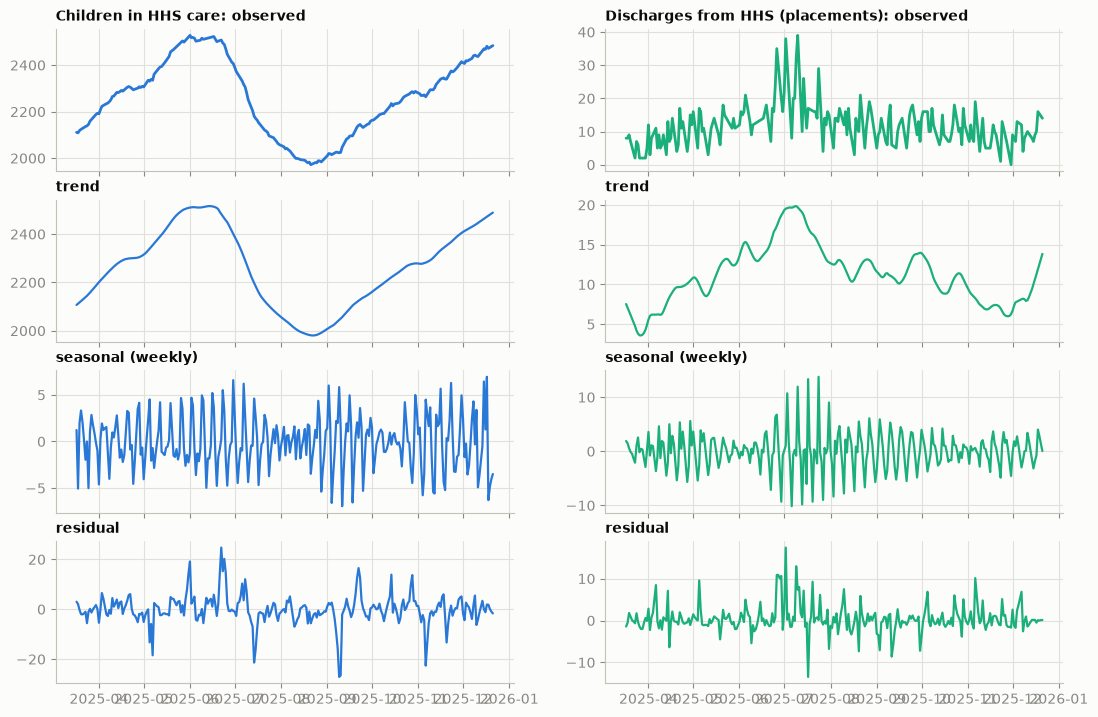

In [33]:
# STL decomposition (weekly period, robust to outliers) of care load and discharges in the current regime
fig, axes = plt.subplots(4, 2, figsize=(13, 8.5), sharex=True)
for j, c in enumerate(["hhs_care", "discharged"]):
    res = STL(daily.loc[REGIME_START:, c], period=7, robust=True).fit()
    for i, (part, name) in enumerate(zip([res.observed, res.trend, res.seasonal, res.resid], ["observed", "trend", "seasonal (weekly)", "residual"])):
        axes[i, j].plot(part.index, part, color=SERIES_COLORS[c], lw=1.6 if i else 2)
        axes[i, j].set_title(f"{LABELS[c]}: {name}" if i == 0 else name, fontsize=10)
    strength = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    print(f"{LABELS[c]}: weekly seasonal strength = {strength:.2f}")
savefig(fig, "08_stl_decomposition")

**Observation:** Weekly seasonality is strong for discharges (strength 0.42; on average Thursday runs about +3.5 and Sunday about −4.8 placements versus trend) but weak for care load (0.14). Care load is dominated by its trend, which fell from about 2,107 to 1,980 and then climbed to about 2,489. Weekly terms therefore matter for discharge forecasts and much less for the census.

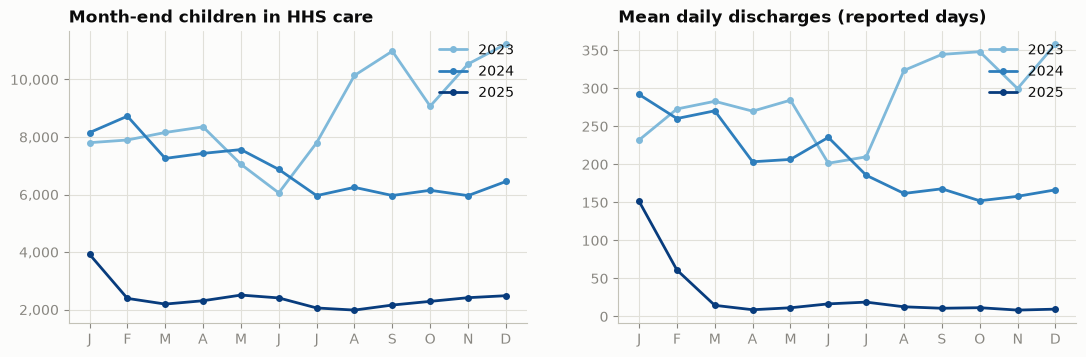

Month-to-month direction of care load agrees between 2023 and 2024 in 5 of 11 months


In [34]:
# Monthly pattern (descriptive): month-end care load and mean daily discharges by calendar month and year; each month occurs at most three times
mon = daily.query("is_reported").resample("MS").agg({"hhs_care": "last", "discharged": "mean", "transferred": "mean"})
mon["year"], mon["month"] = mon.index.year, mon.index.month
years = sorted(mon["year"].unique())
YEAR_COLORS = dict(zip(years, plt.cm.Blues(np.linspace(0.45, 0.95, len(years)))))      # sequential: later years darker
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for yr, g in mon.groupby("year"):
    axes[0].plot(g["month"], g["hhs_care"], color=YEAR_COLORS[yr], marker="o", ms=4, label=str(yr))
    axes[1].plot(g["month"], g["discharged"], color=YEAR_COLORS[yr], marker="o", ms=4, label=str(yr))
axes[0].set_title("Month-end children in HHS care"); axes[0].yaxis.set_major_formatter(COMMA)
axes[1].set_title("Mean daily discharges (reported days)")
for ax in axes:
    ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]); ax.legend(loc="upper right")
savefig(fig, "07c_monthly_pattern")
MONTHLY = mon.pivot_table(index="month", columns="year", values="hhs_care").round(0)
full_years = [y for y in years if mon.loc[mon["year"] == y, "month"].nunique() == 12][:2]        # first two complete calendar years
if len(full_years) == 2:
    a, b = (np.sign(MONTHLY[y].diff()) for y in full_years)
    print(f"Month-to-month direction of care load agrees between {full_years[0]} and {full_years[1]} in {int((a == b).sum())} of {int((a.notna() & b.notna()).sum())} months")

**Observation:** Month-end care load followed a different path in every year: it peaked in December 2023 (11,516 on 20 Dec), moved between about 5,700 and 9,000 through 2024, and collapsed in early 2025. The month-to-month direction agreed between 2023 and 2024 in only 5 of 11 months, no better than chance. With each calendar month seen at most three times, and once on each side of the 2025 break, there is no stable month-of-year pattern to estimate, which supports leaving month and week-of-year out of the features.

In [35]:
# Outliers and unusual periods: largest robust deviations (MAD z-scores vs a centred 29-day median, reported days) and the fastest 28-day rises in care load
out_rows = []
for c in ("transferred", "discharged"):
    x = daily[c].where(daily["is_reported"] & OBSERVED[c]).dropna()
    med = x.rolling(29, center=True, min_periods=10).median()
    mad = (x - med).abs().rolling(29, center=True, min_periods=10).median() * 1.4826
    z = ((x - med) / mad.replace(0, np.nan)).dropna()
    for d in z.abs().nlargest(3).index:
        out_rows.append({"series": c, "date": d.date(), "value": x[d], "local median": med[d], "robust z": z[d]})
OUTLIERS = pd.DataFrame(out_rows).round(1)
rise = (daily["hhs_care"] - daily["hhs_care"].shift(28)).dropna()
SURGES = []
for d in rise.sort_values(ascending=False).index:                       # three non-overlapping fastest 28-day rises
    if all(abs((d - s).days) > 56 for s in SURGES):
        SURGES.append(d)
    if len(SURGES) == 3:
        break
display(OUTLIERS)
pd.DataFrame({"28-day window ending": [d.date() for d in SURGES], "care load at end": [daily.at[d, "hhs_care"] for d in SURGES],
              "rise over 28 days": [rise[d] for d in SURGES], "rise %": [rise[d] / daily.at[d - pd.Timedelta(days=28), "hhs_care"] * 100 for d in SURGES]}).round(1)

,series,date,value,local median,robust z
0,transferred,2025-09-11,29.0,11.0,12.1
1,transferred,2025-09-17,5.0,12.0,-4.7
2,transferred,2025-11-23,22.0,8.0,3.8
3,discharged,2025-07-10,39.0,17.0,4.9
4,discharged,2025-06-26,35.0,17.0,4.0
5,discharged,2025-07-27,4.0,15.0,-3.7


,28-day window ending,care load at end,rise over 28 days,rise %
0,2023-08-13,9274.0,2806.0,43.4
1,2023-12-20,11516.0,1695.0,17.3
2,2023-02-09,7908.0,1342.0,20.4


**Observation:** The largest robust deviations occur at the low volumes of the current regime: 29 transfers on 11 Sep 2025 against a local median of 11 (robust z = 12.1) and 39 discharges on 10 Jul 2025 against 17 (z = 4.9). They pass the plausibility rules and look like genuine operational spikes, so they are kept; Huber-loss boosting and median-based checks limit their influence. The fastest build-ups in care load were all in 2023: +2,806 children (+43%) in the 28 days to 13 Aug 2023, +1,342 (+20%) to 9 Feb 2023 and +1,695 (+17%) to the 11,516 peak on 20 Dec 2023. These are the surges the early-warning replay is tested on.

In [36]:
# Correlations in the current regime (reported days): same-day links and CBP-to-HHS lags; these are associations, not causal effects
cr = daily.loc[REGIME_START:].query("is_reported").assign(care_change=lambda x: x["hhs_care"].diff())
CORR = cr[["apprehended", "cbp_custody", "transferred", "discharged", "care_change"]].corr().round(2)
lagged = {k: cr["transferred"].corr(daily["apprehended"].shift(k).reindex(cr.index)) for k in range(0, 4)}   # reported target days
print("corr(transfers today, apprehensions k days earlier):", {k: round(v, 2) for k, v in lagged.items()})
CORR

corr(transfers today, apprehensions k days earlier): {0: np.float64(0.38), 1: np.float64(0.59), 2: np.float64(0.58), 3: np.float64(0.45)}


,apprehended,cbp_custody,transferred,discharged,care_change
apprehended,1.00,0.53,0.38,-0.14,0.28
cbp_custody,0.53,1.00,0.38,-0.16,0.26
transferred,0.38,0.38,1.00,-0.17,0.47
discharged,-0.14,-0.16,-0.17,1.00,-0.61
care_change,0.28,0.26,0.47,-0.61,1.00


**Observation:** In the current regime the daily care-load change rises with transfers (+0.47) and falls with discharges (−0.61); the stronger discharge link is consistent with placement being the binding constraint. CBP intake leads HHS transfers by one to two days: transfers correlate 0.38 with same-day apprehensions but 0.59 and 0.58 with apprehensions one and two days earlier, which supports the lagged CBP features. These are associations only; they do not show that one series causes another.

In [37]:
# Stationarity: ADF (H0 = unit root) and KPSS (H0 = stationary) together; agreement gives a clear verdict
adf_rows = []
for c in ["hhs_care", "discharged", "transferred"]:
    s = daily.loc[REGIME_START:, c]
    for label, series in [("level", s), ("1st difference", s.diff().dropna())]:
        p_adf, p_kpss = adfuller(series, autolag="AIC")[1], kpss(series, regression="c", nlags="auto")[1]
        verdict = "stationary" if (p_adf < 0.05 and p_kpss > 0.05) else "non-stationary" if (p_adf >= 0.05 and p_kpss <= 0.05) else "inconclusive"
        adf_rows.append({"series": c, "form": label, "ADF p": round(p_adf, 3), "KPSS p": round(p_kpss, 3), "verdict": verdict})
pd.DataFrame(adf_rows)

,series,form,ADF p,KPSS p,verdict
0,hhs_care,level,0.106,0.086,inconclusive
1,hhs_care,1st difference,0.350,0.079,inconclusive
2,discharged,level,0.171,0.050,non-stationary
3,discharged,1st difference,0.000,0.100,stationary
4,transferred,level,0.035,0.100,stationary
5,transferred,1st difference,0.000,0.100,stationary


**Observation:** Transfers are stationary in level, and discharges become stationary after one difference. For care load both tests are inconclusive (ADF p = 0.106 and 0.350; KPSS p = 0.086 and 0.079) because the regime window is short. The differencing choice for care load therefore rests on structure: a stock accumulates flows, so it is modelled with one difference.

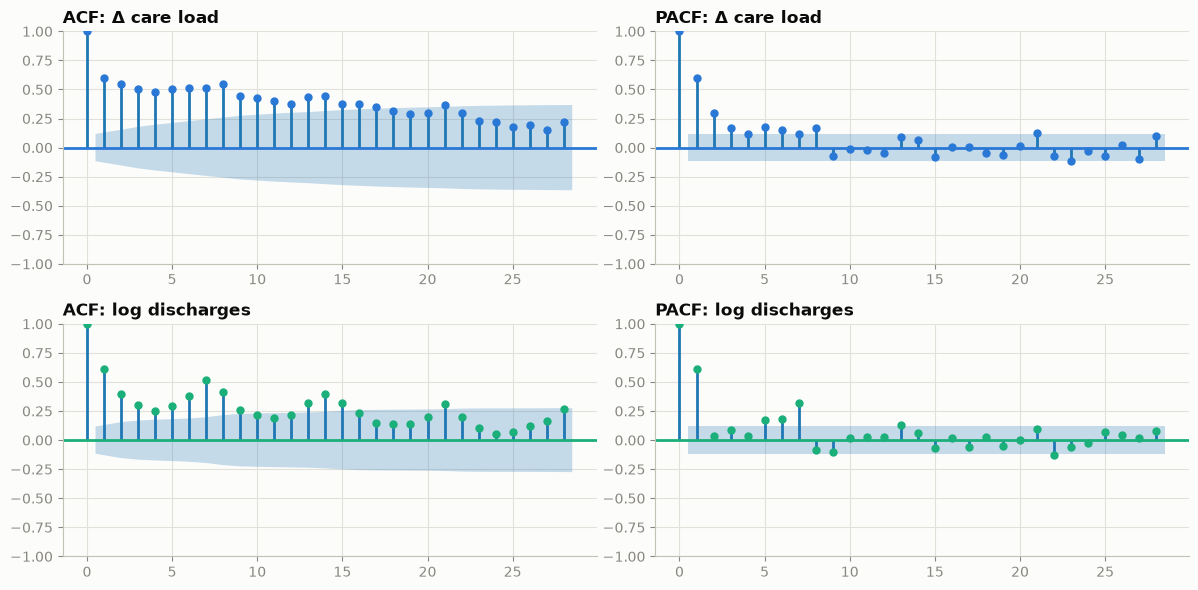

In [38]:
# ACF/PACF of differenced care load and log discharges guide the ARIMA orders (spikes at lag 7 = weekly pattern)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
care_d = daily.loc[REGIME_START:, "hhs_care"].diff().dropna()
dis_l = np.log1p(daily.loc[REGIME_START:, "discharged"])
plot_acf(care_d, lags=28, ax=axes[0, 0], color=SERIES_COLORS["hhs_care"], title="ACF: Δ care load")
plot_pacf(care_d, lags=28, ax=axes[0, 1], color=SERIES_COLORS["hhs_care"], title="PACF: Δ care load", method="ywm")
plot_acf(dis_l, lags=28, ax=axes[1, 0], color=SERIES_COLORS["discharged"], title="ACF: log discharges")
plot_pacf(dis_l, lags=28, ax=axes[1, 1], color=SERIES_COLORS["discharged"], title="PACF: log discharges", method="ywm")
fig.tight_layout(); savefig(fig, "09_acf_pacf")

**Observation:** Daily care-load changes are persistent. Autocorrelation is 0.60 at lag 1 and 0.51 at lag 7 on the daily series, and still 0.44 and 0.39 using only genuine consecutive reports (interpolated weekends repeat the same change, which inflates the raw figures). 18 of the 28 lags exceed the plotted significance band. The partial autocorrelation drops from 0.60 at lag 1 to 0.29 at lag 2, pointing to a short autoregressive term. Log discharges show a weekly pattern (partial autocorrelation 0.32 at lag 7 vs 0.03 at lag 2), which supports weekly seasonal terms. This momentum is what lets models beat "tomorrow = today" at longer horizons.

**Modelling decisions from the EDA**
* **Care load:** one difference (d = 1) plus an autoregressive term to capture momentum.
* **Flows:** log scale, no differencing (d = 0), with a constant, so forecasts revert to the regime's typical level instead of extrapolating a temporary push. The walk-forward test validates this choice.
* **Seasonality:** period s = 7, kept only where AIC finds it useful.
* **Training windows:** statistical models train on the current regime only; ML models use scale-free targets so the larger 2024 history stays informative without its volume level dominating.

## 7. Feature engineering

Every feature describes what is known **at the end of the origin day _t_**. A direct multi-horizon design then stacks one row per (origin, horizon) and adds the horizon `h` and the calendar of the *target* day.

| Group | Features |
|---|---|
| Lags (t-1, t-7, t-14) | care-load log-changes; flow lags relative to their 14-day mean |
| Rolling mean & variance (7 / 14 days) | care-load deviation from its rolling mean, rolling volatility; flow rolling means and log-variances |
| Flow-based signals | net pressure (transfers − discharges) per 100 children: lag-1, 7-day and 14-day means; CBP pipeline per 100 children |
| Calendar | target weekday, US federal-holiday window (±1 day), origin weekday, horizon |
| Seasonal anchor | same weekday last week relative to today's level |

**Why there is no month feature (an RCA finding from the first full run).** My first version included the target month. It became the *single most important* care-load feature (about 30% of Random Forest importance), and the production forecast showed Random Forest dropping from 2,525 on 31 Dec to 2,282 on 1 Jan, a 10% cliff exactly at the month boundary. The trusted training history contains only **one** January, January 2025, which is the policy-break crash. So the model had learned "January ⇒ care load collapses", a regime change disguised as seasonality. With under two years of trusted data no month effect can be estimated reliably, so the feature was removed. The trade-off was measured, not assumed. On the Sep–Dec 2025 test window, removing it raised Random Forest's care-load MAE (25 → 38) but lowered Gradient Boosting's (40 → 31), and the Ensemble stayed the best model on test (28.5). A feature that can create a 10% forecast cliff is unacceptable in an early-warning system, whatever it does to one window's score. The holiday window was tested the same way and changes forecasts by at most about 4 children, so it stays.

In [39]:
# Origin-level features: everything known at the end of day t (rolling windows only look backwards)
HOLIDAYS = USFederalHolidayCalendar().holidays(daily.index.min(), T_END + pd.Timedelta(days=90))
HOLIDAY_WINDOW = HOLIDAYS.union(HOLIDAYS + pd.Timedelta(days=1)).union(HOLIDAYS - pd.Timedelta(days=1))


def origin_features(d):
    """Scale-free features at each origin day: lags, rolling mean/variance, net pressure and pipeline signals."""
    f = pd.DataFrame(index=d.index)
    care, net = d["hhs_care"], d["transferred"] - d["discharged"]
    for k in (1, 7, 14):
        f[f"care_logchg_{k}"] = np.log(care / care.shift(k))                 # lagged momentum of the stock
    for w in (7, 14):
        f[f"care_dev_ma{w}"] = np.log(care / care.rolling(w).mean())          # level vs rolling mean
        f[f"care_vol{w}"] = care.diff().rolling(w).std() / care * 100         # rolling volatility (% of load)
        f[f"net_rate_ma{w}"] = net.rolling(w).mean() / care * 100             # net pressure per 100 children
    f["net_rate_lag1"] = net / care * 100
    f["cbp_pipeline_rate"] = d["cbp_custody"] / care * 100                    # children waiting at CBP per 100 in HHS
    for c in ("apprehended", "transferred", "discharged"):
        base = np.log1p(d[c].rolling(14).mean())
        for k in (0, 1, 7, 14):
            f[f"{c}_lag{k}"] = np.log1p(d[c].shift(k)) - base                 # lags relative to the 14-day mean
        f[f"{c}_ma7"] = np.log1p(d[c].rolling(7).mean()) - base
        f[f"{c}_logvar7"] = np.log1p(d[c]).rolling(7).var()
        f[f"{c}_logvar14"] = np.log1p(d[c]).rolling(14).var()
        f[f"{c}_rate14"] = d[c].rolling(14).mean() / care * 100               # flow per 100 children in care
    f["origin_dow"] = d.index.dayofweek
    return f


FEATS = origin_features(daily)
print("Origin features:", FEATS.shape[1])
FEATS.loc[T_END].round(3).to_frame("value at last origin").T

Origin features: 36


,care_logchg_1,care_logchg_7,care_logchg_14,care_dev_ma7,care_vol7,net_rate_ma7,care_dev_ma14,care_vol14,net_rate_ma14,net_rate_lag1,cbp_pipeline_rate,apprehended_lag0,apprehended_lag1,apprehended_lag7,apprehended_lag14,...,transferred_lag7,transferred_lag14,transferred_ma7,transferred_logvar7,transferred_logvar14,transferred_rate14,discharged_lag0,discharged_lag1,discharged_lag7,discharged_lag14,discharged_ma7,discharged_logvar7,discharged_logvar14,discharged_rate14,origin_dow
value at last origin,0.002,0.009,0.022,0.003,0.283,-0.098,0.009,0.252,-0.078,-0.121,0.725,-0.259,-0.046,-0.008,-0.596,...,-0.619,0.411,0.156,0.069,0.095,0.334,0.291,0.334,-0.22,0.148,0.17,0.085,0.108,0.411,6.0


**Observation:** At the last report (21 Dec 2025) care load is 2.2% above its level 14 days earlier and slightly above its 7- and 14-day averages, confirming the upward trend. Recorded net pressure is slightly negative (−0.08 to −0.12 per 100 children), and the CBP pipeline holds 0.7 children per 100 in care (18 children). Most of the 36 features are ratios or log-changes, so they stay comparable across the 2024 and 2025 regimes despite a twenty-fold difference in volumes.

In [40]:
# Scale-free targets let one model learn from both the high-volume (2024) and low-volume (2025) regimes
def to_target(future, d, col, kind):
    """stock: log(y[t+h] / y[t]); flow: log1p(y[t+h]) - log1p(14-day mean at t)."""
    if kind == "stock":
        return np.log(future / d[col])
    return np.log1p(future) - np.log1p(d[col].rolling(14).mean())


def from_target(z, d, t, col, kind):
    """Invert to_target at origin t to get forecasts in children."""
    if kind == "stock":
        return d.at[t, col] * np.exp(z)
    return np.clip(np.expm1(z + np.log1p(d.loc[:t, col].tail(14).mean())), 0, None)

In [41]:
# Direct multi-horizon stacking: one block per horizon h with target-day calendar features and a seasonal anchor
def horizon_block(d, col, kind, h, feats=None):
    """Rows = origins; adds h, target-day calendar, same-weekday-last-week anchor, target z and a validity mask."""
    X = (FEATS if feats is None else feats).copy()
    tdate = d.index + pd.Timedelta(days=h)
    X["h"] = h
    X["target_dow"] = tdate.dayofweek                                         # no month feature: see the note above
    X["target_holiday"] = tdate.isin(HOLIDAY_WINDOW).astype(int)
    lag = 7 * int(np.ceil(h / 7)) - h                                         # shift that lands on the same weekday, at or before t
    anchor = d[col].shift(lag)
    X["seasonal_anchor"] = np.log(anchor / d[col]) if kind == "stock" else np.log1p(anchor) - np.log1p(d[col].rolling(14).mean())
    X["z"] = to_target(d[col].shift(-h), d, col, kind)
    X["target_date"] = tdate
    target_ok = d["is_reported"] & OBSERVED[col].reindex(d.index, fill_value=False)           # reported day AND a genuine value for this series
    X["target_reported"] = target_ok.shift(-h, fill_value=False).to_numpy()
    return X


STACKS = {col: {h: horizon_block(daily, col, kind, h) for h in range(1, H + 1)} for col, kind in TARGETS.items()}
FEATURE_COLS = [c for c in STACKS["hhs_care"][1].columns if c not in ("z", "target_date", "target_reported")]
print(f"{len(FEATURE_COLS)} model features per row; example block for h=7:")
STACKS["hhs_care"][7].loc[T_END - pd.Timedelta(days=7), FEATURE_COLS[:6] + ["h", "target_dow", "seasonal_anchor", "z"]].to_frame().T.round(4)

40 model features per row; example block for h=7:


,care_logchg_1,care_logchg_7,care_logchg_14,care_dev_ma7,care_vol7,net_rate_ma7,h,target_dow,seasonal_anchor,z
2025-12-14,0.003391,0.013494,0.019275,0.006637,0.236118,-0.058025,7,6,0.0,0.008896


**Observation:** Each training row holds 40 model features plus the target. In the example (origin 14 Dec 2025, horizon 7 days), the target z = 0.0089 means care load rose 0.9% over the following week (2,462 → 2,484): exactly the kind of small relative change the ML models learn to predict.

### 7.1 Leakage audit

Two complementary checks. **(1) Executed perturbation test:** every report after a cut-off date is scaled by 1.5, the whole preparation (daily grid, masks, interpolation) and every feature are recomputed, and any feature value that changes at a reported origin on or before the cut-off is a leak. A negative control (the target *z*, which looks ahead by design) must change, proving the test can detect look-ahead. **(2) A documented definition for every feature:** source columns, look-back window, availability at the forecast origin and suitability for each horizon.

In [42]:
# Leakage audit, part 1 (executed): perturb every report after the cut-off, recompute preparation + features, count changed feature values at origins up to the cut-off
def prep_daily(frame):
    """Replica of §5 (daily grid, masks, interpolation); checked below to reproduce `daily` exactly."""
    g = frame.asfreq("D")
    g["is_reported"] = g["hhs_care"].notna() & g["discharged"].notna()
    g["cbp_trusted"] = g.index > CBP_BAD_END
    g.loc[~g["cbp_trusted"], CBP_COLS] = np.nan
    g[value_cols] = g[value_cols].interpolate(method="time", limit_area="inside")
    g["net_pressure"] = g["transferred"] - g["discharged"]
    return g


replica_ok = prep_daily(df)[daily.columns].equals(daily)
LEAK_CUT = T_END - pd.Timedelta(days=60)
LEAK_CUT -= pd.Timedelta(days=(LEAK_CUT.dayofweek - 5) % 7)          # a Saturday: its interpolated value depends on the next (perturbed) Sunday report
pert = df.copy(); pert.loc[pert.index > LEAK_CUT, value_cols] *= 1.5
dp = prep_daily(pert); feats_p = origin_features(dp)
chk_origins = daily.index[(daily.index <= LEAK_CUT) & daily["is_reported"] & (daily.index > CBP_BAD_END + pd.Timedelta(days=15))]
LEAK_CHANGED = pd.Series(0, index=FEATURE_COLS)
z_changed = 0
for col, kind in TARGETS.items():
    for h in (1, 7, 14, 28):
        a = STACKS[col][h].loc[chk_origins]; b = horizon_block(dp, col, kind, h, feats=feats_p).loc[chk_origins]
        LEAK_CHANGED += (~np.isclose(a[FEATURE_COLS].to_numpy(float), b[FEATURE_COLS].to_numpy(float), equal_nan=True)).sum(axis=0)
        z_changed += int((~np.isclose(a["z"].to_numpy(float), b["z"].to_numpy(float), equal_nan=True)).sum())
unrep = daily.index[(daily.index <= LEAK_CUT) & (daily.index > LEAK_CUT - pd.Timedelta(days=7)) & ~daily["is_reported"]]
unrep_changed = int((~np.isclose(FEATS.loc[unrep].to_numpy(float), feats_p.loc[unrep].to_numpy(float), equal_nan=True)).any(axis=1).sum())
print(f"Replica of §5 reproduces `daily` exactly: {replica_ok} | cut-off {LEAK_CUT:%d %b %Y} | reported origins checked: {len(chk_origins)} × 3 series × 4 horizons")
print(f"Feature values changed at reported origins ≤ cut-off: {int(LEAK_CHANGED.sum())} (must be 0)")
print(f"Negative controls: target z changed in {z_changed} rows (must be > 0); interpolated days just before the cut-off changed: {unrep_changed} of {len(unrep)}")

Replica of §5 reproduces `daily` exactly: True | cut-off 18 Oct 2025 | reported origins checked: 410 × 3 series × 4 horizons
Feature values changed at reported origins ≤ cut-off: 0 (must be 0)
Negative controls: target z changed in 99 rows (must be > 0); interpolated days just before the cut-off changed: 2 of 3


**Observation:** The leakage test passes. The §5 replica reproduces the notebook's daily table exactly, and after every report from 19 Oct 2025 onward is scaled by 1.5, **0** feature values change at the 410 reported origins up to the 18 Oct 2025 cut-off (40 features, 3 series, horizons 1/7/14/28). The negative controls prove the test can see look-ahead: the target z changes in 99 rows (targets after the cut-off), and 2 of the 3 interpolated days just before the cut-off change, which is exactly why forecasts are issued only from reported days.

In [43]:
# Leakage audit, part 2: definition, sources, look-back window, availability at the origin and horizon suitability for every model feature
def describe_feature(f):
    m = lambda p: re.fullmatch(p, f)
    if (g := m(r"care_logchg_(\d+)")):  return f"log(care[t] / care[t−{g[1]}])", "hhs_care", f"t−{g[1]} … t"
    if (g := m(r"care_dev_ma(\d+)")):   return f"log(care[t] / {g[1]}-day mean of care)", "hhs_care", f"t−{int(g[1]) - 1} … t"
    if (g := m(r"care_vol(\d+)")):      return f"std of daily care change over {g[1]} days ÷ care[t] × 100", "hhs_care", f"t−{g[1]} … t"
    if (g := m(r"net_rate_ma(\d+)")):   return f"{g[1]}-day mean of (transfers − discharges) ÷ care[t] × 100", "transferred, discharged, hhs_care", f"t−{int(g[1]) - 1} … t"
    if f == "net_rate_lag1":            return "(transfers − discharges) on the origin day ÷ care[t] × 100", "transferred, discharged, hhs_care", "t"
    if f == "cbp_pipeline_rate":        return "children in CBP custody ÷ care[t] × 100", "cbp_custody, hhs_care", "t"
    if (g := m(r"(\w+)_lag(\d+)")):     return f"log1p({g[1]}[t−{g[2]}]) − log1p(14-day mean)", g[1], f"t−{max(int(g[2]), 13)} … t"
    if (g := m(r"(\w+)_ma7")):          return f"log1p(7-day mean) − log1p(14-day mean) of {g[1]}", g[1], "t−13 … t"
    if (g := m(r"(\w+)_logvar(\d+)")):  return f"variance of log1p({g[1]}) over {g[2]} days", g[1], f"t−{int(g[2]) - 1} … t"
    if (g := m(r"(\w+)_rate14")):       return f"14-day mean of {g[1]} ÷ care[t] × 100", f"{g[1]}, hhs_care", "t−13 … t"
    if f == "origin_dow":               return "weekday of the origin day", "calendar", "t"
    if f == "h":                        return "forecast horizon in days", "design", "n/a"
    if f == "target_dow":               return "weekday of the target day t+h", "calendar", "known in advance"
    if f == "target_holiday":           return "target day within ±1 day of a US federal holiday", "calendar (USFederalHolidayCalendar)", "known in advance"
    if f == "seasonal_anchor":          return "same-weekday value at t+h−7⌈h/7⌉ (≤ t) relative to today's level (flows: 14-day mean)", "series being forecast", "t−13 … t"
    return "undocumented", "?", "?"


AUDIT = pd.DataFrame([dict(zip(["definition", "source columns", "look-back window"], describe_feature(f)), feature=f) for f in FEATURE_COLS]).set_index("feature")
AUDIT["available at origin t?"] = np.where(AUDIT["look-back window"].isin(["known in advance", "n/a"]), "yes (deterministic)", "yes (≤ t only)")
AUDIT["horizon suitability"] = np.where(AUDIT.index.isin(["target_dow", "target_holiday", "h", "seasonal_anchor"]), "built per horizon (direct strategy)", "all h; information ages with h")
AUDIT["changed under perturbation"] = LEAK_CHANGED
print(f"{len(AUDIT)} features documented; undocumented: {(AUDIT['definition'] == 'undocumented').sum()}; leaking (changed): {(AUDIT['changed under perturbation'] > 0).sum()}")
AUDIT

40 features documented; undocumented: 0; leaking (changed): 0


,definition,source columns,look-back window,available at origin t?,horizon suitability,changed under perturbation
feature,,,,,,
care_logchg_1,log(care[t] / care[t−1]),hhs_care,t−1 … t,yes (≤ t only),all h; information ages with h,0
care_logchg_7,log(care[t] / care[t−7]),hhs_care,t−7 … t,yes (≤ t only),all h; information ages with h,0
care_logchg_14,log(care[t] / care[t−14]),hhs_care,t−14 … t,yes (≤ t only),all h; information ages with h,0
care_dev_ma7,log(care[t] / 7-day mean of care),hhs_care,t−6 … t,yes (≤ t only),all h; information ages with h,0
care_vol7,std of daily care change over 7 days ÷ care[t]...,hhs_care,t−7 … t,yes (≤ t only),all h; information ages with h,0
net_rate_ma7,7-day mean of (transfers − discharges) ÷ care[...,"transferred, discharged, hhs_care",t−6 … t,yes (≤ t only),all h; information ages with h,0
care_dev_ma14,log(care[t] / 14-day mean of care),hhs_care,t−13 … t,yes (≤ t only),all h; information ages with h,0
care_vol14,std of daily care change over 14 days ÷ care[t...,hhs_care,t−14 … t,yes (≤ t only),all h; information ages with h,0
net_rate_ma14,14-day mean of (transfers − discharges) ÷ care...,"transferred, discharged, hhs_care",t−13 … t,yes (≤ t only),all h; information ages with h,0


**Observation:** All 40 model features are documented and none leaks. 36 are origin features whose look-back windows end on the origin day (from t−14 … t to t alone); the other four are the horizon itself, the known calendar of the target day (weekday and federal-holiday window) and the same-weekday anchor taken at or before t. Every input is therefore available at prediction time for every horizon from 1 to 28 days, as the direct strategy requires.

**Calendar features considered and excluded.** *Month* was removed after the incident described above (one trusted January, which was the policy-break crash). *Week of year* has the same flaw (each week occurs at most twice in the trusted history, once on each side of the break) and was never added. *Future flows* (tomorrow's transfers or discharges) are unavailable at the forecast origin, so multi-step forecasts use the **direct** strategy: one model sees the horizon `h` and only origin-time information, never predicted or actual future lags.

## 8. Train–test design

* **Strict time order.** No random sampling anywhere.
* **Walk-forward.** A forecast is issued from **every reported day** in the evaluation period, for horizons 1–28. Models are **re-estimated every 14 days**; between re-estimations they absorb each new observation (state update), the way a production system would run.
* **Two evaluation windows.** A *calibration* window (13 weeks) is used to choose the champion model and calibrate the intervals. The final *test* window (the last 13 weeks) stays untouched until reporting.
* **Training windows from the RCA.** Statistical models train on the current regime. ML models train on the trusted-CBP period (Feb 2024 onward) with scale-free targets and recency weighting.

In [44]:
# Window boundaries: calibration (13 weeks) then test (13 weeks); ML history starts after the copied CBP block + 2-week warm-up
CAL_DAYS = TEST_DAYS = 91
TEST_START = T_END - pd.Timedelta(days=TEST_DAYS)
CAL_START = TEST_START - pd.Timedelta(days=CAL_DAYS)
ML_START = CBP_BAD_END + pd.Timedelta(days=15)
REFIT_EVERY = 14
ORIGINS = daily.index[(daily.index >= CAL_START) & (daily.index < T_END) & daily["is_reported"]]
print(f"ML training from {ML_START:%d %b %Y} | stats training from {REGIME_START:%d %b %Y}")
print(f"Calibration {CAL_START:%d %b %Y} → {TEST_START - pd.Timedelta(days=1):%d %b %Y} | Test {TEST_START:%d %b %Y} → {T_END:%d %b %Y} | {len(ORIGINS)} forecast origins")

ML training from 14 Feb 2024 | stats training from 17 Mar 2025
Calibration 22 Jun 2025 → 20 Sep 2025 | Test 21 Sep 2025 → 21 Dec 2025 | 124 forecast origins


**Observation:** The ML models learn from 22 months of trusted history (from 14 Feb 2024) and the statistical models from 9 months of the current regime (from 17 Mar 2025). Forecasts are issued from 124 reported days across two 13-week windows, giving a large, strictly out-of-sample evaluation set.

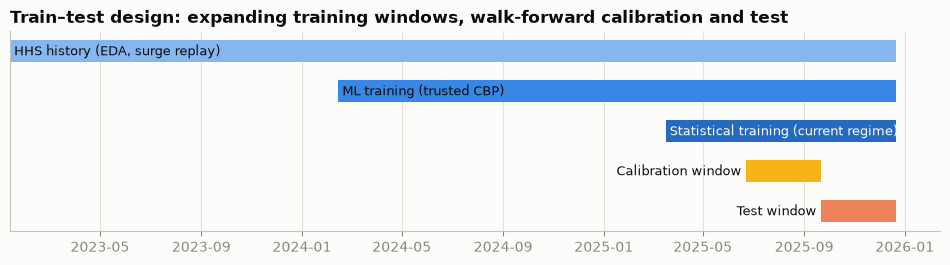

In [45]:
# Timeline of the design: which data each component sees
fig, ax = plt.subplots(figsize=(12, 2.6))
bars = [("HHS history (EDA, surge replay)", daily.index.min(), T_END, "#86b6ef"),
        ("ML training (trusted CBP)", ML_START, T_END, "#3987e5"),
        ("Statistical training (current regime)", REGIME_START, T_END, "#256abf"),
        ("Calibration window", CAL_START, TEST_START, STATUS["warning"]),
        ("Test window", TEST_START, T_END, STATUS["serious"])]
for i, (name, a, b, col) in enumerate(bars[::-1]):
    ax.barh(i, (b - a).days, left=mdates.date2num(a), height=0.55, color=col)
    if (b - a).days > 250:                                                     # long bar: label inside
        ax.text(mdates.date2num(a) + 5, i, name, va="center", fontsize=9, color=INK if col != "#256abf" else "white")
    else:                                                                      # short bar: label to its left
        ax.text(mdates.date2num(a) - 5, i, name, va="center", ha="right", fontsize=9, color=INK)
ax.xaxis_date(); ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_title("Train–test design: expanding training windows, walk-forward calibration and test")
savefig(fig, "10_train_test_design")

**Observation:** The design keeps strict time order. The calibration window (22 Jun – 20 Sep 2025) picks the models and sizes the intervals; the test window (21 Sep – 21 Dec 2025) comes after it and is used only for reporting. No model is fitted on data from after its forecast date. One caveat: the regime start date and the data-quality flags were set using the full history, a mild design-level look-ahead; the next cell tests whether it matters.

In [46]:
# Origin-time check of the design constants: would the copied-CBP block and the regime breaks have been found with data up to the FIRST forecast origin only?
def copy_block(key):
    """(start, end) of the longest contiguous run of earlier copies in a CBP key series, or None if there are no copies."""
    c = key.duplicated(keep="last"); rid = (c != c.shift()).cumsum(); r = c.groupby(rid).agg(["first", "size"])
    if not r["first"].any() or r.loc[r["first"], "size"].max() < MIN_COPY_RUN:
        return None
    blk = c[rid == r[r["first"]]["size"].idxmax()].index
    return blk.min(), blk.max()


fmt_rng = lambda b: "none" if b is None else f"{b[0]:%d %b %Y} → {b[1]:%d %b %Y}"
fmt_day = lambda d: "n/a (too short)" if d is None else f"{d:%d %b %Y}"
blk_then = copy_block(cbp_key.loc[:CAL_START])
rep_then = reported.loc[:CAL_START]
brk_t_then = single_break(rep_then.loc[rep_then.index > (blk_then[1] if blk_then else CBP_BAD_END), "transferred"])
brk_d_then = single_break(rep_then["discharged"])
ORIGIN_TIME_CHECK = pd.DataFrame({
    "full history (used)": [fmt_rng(copy_block(cbp_key)), fmt_day(brk_transfers), fmt_day(brk_discharges)],
    f"data up to {CAL_START:%d %b %Y} only": [fmt_rng(blk_then), fmt_day(brk_t_then), fmt_day(brk_d_then)]},
    index=["copied CBP block", "break in transfers", "break in discharges"])
ORIGIN_TIME_CHECK["identical"] = ORIGIN_TIME_CHECK.iloc[:, 0] == ORIGIN_TIME_CHECK.iloc[:, 1]
originals = [cbp_key.index[(cbp_key == cbp_key[d]) & (cbp_key.index > d)].max() for d in is_copy.index[is_copy & (is_copy.index <= CBP_BAD_END)]]
if originals:
    print(f"Originals of the copied rows are dated {min(originals):%d %b %Y} – {max(originals):%d %b %Y}; first forecast origin {CAL_START:%d %b %Y}")
ORIGIN_TIME_CHECK

Originals of the copied rows are dated 26 Jun 2024 – 12 Feb 2025; first forecast origin 22 Jun 2025


,full history (used),data up to 22 Jun 2025 only,identical
copied CBP block,12 Jan 2023 → 30 Jan 2024,12 Jan 2023 → 30 Jan 2024,True
break in transfers,26 Jan 2025,26 Jan 2025,True
break in discharges,17 Feb 2025,17 Feb 2025,True


**Observation:** The design-level look-ahead has no effect. With data only up to the first forecast origin (22 Jun 2025) the copy detection finds the identical block (12 Jan 2023 → 30 Jan 2024) and the change-point search finds the identical breaks (26 Jan and 17 Feb 2025), because every original of a copied row is dated 26 Jun 2024 – 12 Feb 2025. All masks and training windows used in the backtest would have been available in real time.

## 9. Forecasting models

Every model has the same two-method interface: `fit(t, col, kind)` estimates parameters with data up to origin *t*, and `predict(t, col, kind)` returns a 28-day path issued at *t*.

| Family | Model | Idea |
|---|---|---|
| Baseline | Naive persistence | tomorrow = today (hard to beat for a slow-moving stock) |
| Baseline | Seasonal naive (7d) | each target day repeats the same weekday of the last week (captures the weekly cycle, nothing else) |
| Baseline | Moving average (7d) | flat forecast at last week's mean |
| Statistical | ARIMA / SARIMA | ARIMA with optional weekly seasonal terms; orders chosen by AIC (the table below compares the best ARIMA and the best SARIMA) |
| Statistical | ETS (Holt-Winters) | exponential smoothing; damped trend for care load, weekly season |
| ML | Random Forest | direct multi-horizon, scale-free target, engineered features |
| ML | Gradient Boosting | same design, Huber loss (robust to outlier days) |
| Hybrid | Ensemble | equal-weight mean of SARIMA, ETS, RF and GB |

**Model cards** (what each model needs, how it can fail, and what happens then)

| Model | Training data & features | Hyper-parameters | Horizons | Failure conditions → fallback | Cost (whole backtest) | Uncertainty |
|---|---|---|---|---|---|---|
| Naive | last reported value | none | any | none | negligible | empirical (walk-forward errors) |
| Seasonal naive | value 7·⌈h/7⌉ − h days before the target day's weekday (≤ origin) | none | any | none | negligible | empirical |
| Moving avg (7d) | last 7 days | window 7 | any | none | negligible | empirical |
| SARIMA | current regime only; target series (log1p for flows) | (p,d,q)(P,0,Q)₇ by AIC on pre-calibration data; d = 1 for the stock | any (iterated state-space forecast) | non-convergence or < 56 days of history → previous parameters, else naive | seconds | empirical (calibrated); analytic available |
| ETS | current regime only; target series | additive error and weekly season; damped trend for the stock | any | < 28 days of history (4 weekly cycles) or fit error → previous parameters, else naive | seconds | empirical; analytic used in the replay |
| Random Forest | trusted window (Feb 2024 →), 40 scale-free features, 180-day recency weights | 200 trees, leaf ≥ 5, 50% features, 70% bootstrap | 1–28 (direct, `h` is a feature) | < 200 training rows or fit error → previous model, else naive | 25–80 s per series | empirical |
| Gradient Boosting | as RF | 150 trees, depth 3, learning rate 0.07, subsample 0.8, Huber loss | 1–28 (direct) | as RF | 40–120 s per series | empirical |
| Ensemble | the four model forecasts | equal weights (no fitted weights, so nothing to over-fit) | 1–28 | a component that failed contributes its (flagged) naive fallback | none | empirical |

Every failed fit or prediction is logged in `FIT_LOG` and the walk-forward continues; a forecast that is not finite or has the wrong length is replaced by naive persistence and marked `fallback = True`.

In [47]:
# Baseline models: naive persistence and a 7-day moving average
class NaiveModel:
    name = "Naive"
    def fit(self, t, col, kind): pass
    def predict(self, t, col, kind): return np.repeat(daily.at[t, col], H)


class SeasonalNaiveModel:
    name = "Seasonal Naive (7d)"
    def fit(self, t, col, kind): pass
    def predict(self, t, col, kind):
        h = np.arange(1, H + 1)
        return daily[col].reindex(t + pd.to_timedelta(h - 7 * np.ceil(h / 7).astype(int), "D")).to_numpy()   # same weekday, at or before t


class MovingAverageModel:
    name = "Moving Avg (7d)"
    def fit(self, t, col, kind): pass
    def predict(self, t, col, kind): return np.repeat(daily.loc[:t, col].tail(7).mean(), H)

In [48]:
# Statistical models work on the current regime; flows are modelled on the log scale (log1p) so forecasts stay positive
def stat_series(t, col, kind):
    y = daily.loc[REGIME_START:t, col].asfreq("D")
    return y if kind == "stock" else np.log1p(y)


def stat_back(f, kind):
    return np.asarray(f) if kind == "stock" else np.clip(np.expm1(np.asarray(f)), 0, None)


class SarimaModel:
    name = "SARIMA"
    def __init__(self, order, seasonal_order, trend): self.spec = dict(order=order, seasonal_order=seasonal_order, trend=trend)
    def fit(self, t, col, kind):
        y = stat_series(t, col, kind)
        if len(y) < 56:
            raise ValueError(f"SARIMA needs at least 56 days of current-regime history, got {len(y)}")
        self.res = SARIMAX(y, **self.spec).fit(disp=False)
    def predict(self, t, col, kind):
        return stat_back(self.res.apply(stat_series(t, col, kind)).forecast(H), kind)   # same parameters, updated state


class EtsModel:
    name = "ETS"
    def _model(self, y, kind):
        if kind == "stock":
            return ETSModel(y, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=7)
        return ETSModel(y, error="add", trend=None, seasonal="add", seasonal_periods=7)
    def fit(self, t, col, kind):
        y = stat_series(t, col, kind)
        if len(y) < 28:
            raise ValueError(f"ETS with a weekly season needs at least 28 days (4 cycles), got {len(y)}")
        self.params = self._model(y, kind).fit(disp=False).params
    def predict(self, t, col, kind):
        return stat_back(self._model(stat_series(t, col, kind), kind).smooth(self.params).forecast(H), kind)

In [49]:
# SARIMA order selection by AIC on data available before the calibration window (no peeking at evaluation data)
def select_sarima(col, kind):
    y = stat_series(CAL_START - pd.Timedelta(days=1), col, kind)
    d, trend = (1, "n") if kind == "stock" else (0, "c")
    rows = []
    for p in (0, 1, 2):
        for q in (0, 1, 2):
            for P, Q in ((0, 0), (1, 1)):
                try:
                    aic = SARIMAX(y, order=(p, d, q), seasonal_order=(P, 0, Q, 7), trend=trend).fit(disp=False).aic
                    rows.append({"order": (p, d, q), "seasonal": (P, 0, Q, 7), "trend": trend, "AIC": aic})
                except Exception:
                    pass
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)


SARIMA_SPECS, GRIDS = {}, {}
for col, kind in TARGETS.items():
    grid = GRIDS[col] = select_sarima(col, kind)
    best = grid.iloc[0]
    SARIMA_SPECS[col] = (best["order"], best["seasonal"], best["trend"])
    print(f"{col:12s} best SARIMA{best['order']}x{best['seasonal']} trend={best['trend']}  AIC={best['AIC']:.1f}")

hhs_care     best SARIMA(1, 1, 1)x(0, 0, 0, 7) trend=n  AIC=617.9
discharged   best SARIMA(1, 0, 1)x(1, 0, 1, 7) trend=c  AIC=74.9
transferred  best SARIMA(1, 0, 0)x(0, 0, 0, 7) trend=c  AIC=84.6


**Observation:** AIC keeps weekly seasonal terms only for discharges (SARIMA(1,0,1)(1,0,1)₇, AIC 74.9), matching their strong weekly cycle. For care load it selects a simple ARIMA(1,1,1) (AIC 617.9) and for transfers an AR(1) (AIC 84.6), because weekly terms did not improve the fit enough. The name "SARIMA" is kept because the seasonal search is part of the method.

In [50]:
# ARIMA vs SARIMA: best non-seasonal vs best weekly-seasonal specification per series (AIC on pre-calibration data; ΔAIC < −2 favours SARIMA)
cmp = []
for col in TARGETS:
    g = GRIDS[col]
    seasonal = g["seasonal"].apply(lambda s: s[0] > 0 or s[2] > 0)
    a, s = g[~seasonal].iloc[0], g[seasonal].iloc[0]
    cmp.append({"series": col, "best ARIMA": str(a["order"]), "AIC ARIMA": a["AIC"], "best SARIMA": f"{s['order']}x{s['seasonal']}",
                "AIC SARIMA": s["AIC"], "ΔAIC (SARIMA − ARIMA)": s["AIC"] - a["AIC"], "specs fitted": len(g)})
ARIMA_VS_SARIMA = pd.DataFrame(cmp).set_index("series").round(1)
ARIMA_VS_SARIMA["selected"] = np.where(ARIMA_VS_SARIMA["ΔAIC (SARIMA − ARIMA)"] < 0, "SARIMA", "ARIMA")
ARIMA_VS_SARIMA

,best ARIMA,AIC ARIMA,best SARIMA,AIC SARIMA,ΔAIC (SARIMA − ARIMA),specs fitted,selected
series,,,,,,,
hhs_care,"(1, 1, 1)",617.9,"(1, 1, 1)x(1, 0, 1, 7)",621.3,3.4,18,ARIMA
discharged,"(1, 0, 2)",86.4,"(1, 0, 1)x(1, 0, 1, 7)",74.9,-11.5,18,SARIMA
transferred,"(1, 0, 0)",84.6,"(1, 0, 0)x(1, 0, 1, 7)",88.4,3.7,18,ARIMA


**Observation:** Weekly seasonal terms earn their place only for discharges, where the best SARIMA beats the best ARIMA by 11.5 AIC points (74.9 vs 86.4). For care load and transfers the seasonal versions are worse by 3.4 and 3.7 points, so plain ARIMA(1,1,1) and AR(1) are kept. Each choice comes from 18 fitted specifications on pre-calibration data only.

In [51]:
# ML models: direct multi-horizon learners on the stacked (origin, horizon) table, with recency weights
ML_HALF_LIFE = 180   # days: a sample from 6 months ago counts half as much as today's


def make_rf():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, max_samples=0.7, n_jobs=-1, random_state=SEED)


def make_gb():
    return GradientBoostingRegressor(n_estimators=150, learning_rate=0.07, max_depth=3, subsample=0.8, max_features=0.5, loss="huber", random_state=SEED)


# Pre-built (day, horizon, feature) tensor so a 28-day forecast is a single fast array lookup
XARR = {col: np.stack([STACKS[col][h][FEATURE_COLS].to_numpy(dtype=float) for h in range(1, H + 1)], axis=1) for col in TARGETS}
POS = pd.Series(np.arange(len(daily)), index=daily.index)


class MLDirectModel:
    def __init__(self, name, factory): self.name, self.factory = name, factory
    def training_table(self, t, col):
        """Rows with origin and target both reported and target date <= t (strictly known at time t)."""
        parts = []
        for h, X in STACKS[col].items():
            ok = (X.index >= ML_START) & (X.index <= t) & daily["is_reported"].to_numpy() & X["target_reported"] & (X["target_date"] <= t)
            parts.append(X[ok])
        tr = pd.concat(parts)
        return tr[np.isfinite(tr[FEATURE_COLS + ["z"]].to_numpy(dtype=float)).all(axis=1)]     # drops NaN and ±inf rows (e.g. a zero care load)
    def fit(self, t, col, kind):
        tr = self.training_table(t, col)
        if len(tr) < 200:
            raise ValueError(f"{self.name} needs at least 200 training rows, got {len(tr)}")
        weights = 0.5 ** ((t - tr.index).days / ML_HALF_LIFE)
        self.model = self.factory().fit(tr[FEATURE_COLS].to_numpy(dtype=float), tr["z"].to_numpy(), sample_weight=weights)
        if hasattr(self.model, "n_jobs"): self.model.set_params(n_jobs=1)    # single-thread predict is faster for 28 rows
        self.n_train = len(tr)
    def predict(self, t, col, kind):
        return from_target(self.model.predict(XARR[col][POS[t]]), daily, t, col, kind)

**Design experiment (run during development, not repeated here to save runtime).** Which history should the ML models learn from? I ran the same walk-forward protocol with three training designs (MAE, children; calibration → test):

| ML training design | Care load RF | Care load GB | Discharges GB |
|---|---|---|---|
| Trusted window (Feb 2024 →) + 180-day recency weights **(chosen)** | 89 → 25 | 97 → 39 | 4.2 → 3.7 |
| Trusted window, no weights | – | 99 → 38 | 4.4 → 3.7 |
| Current regime only | 125 → 24 | 126 → 26 | 5.8 → 3.8 |

Regime-only training is slightly better late in 2025 but **much worse early**, when the new regime had only about three months of history. The chosen design is the most *robust* across both windows, which matters more for an early-warning system than a marginal best case.

**Which evidence made the decision (leakage audit of the design).** The choice follows from the **calibration** column alone (89 vs 125 for Random Forest, 97 vs 126 for Gradient Boosting, 4.2 vs 5.8 for discharges), so it would be the same without the test window; test values are shown for transparency only. Likewise, the month feature was removed because of the 10% production-forecast cliff, not because of a test score.

In [52]:
# Assemble the seven base models for a target (Ensemble is added after the backtest)
def build_models(col):
    return [NaiveModel(), SeasonalNaiveModel(), MovingAverageModel(), SarimaModel(*SARIMA_SPECS[col]), EtsModel(),
            MLDirectModel("Random Forest", make_rf), MLDirectModel("Gradient Boosting", make_gb)]

## 10. Walk-forward backtest

Expect several minutes of runtime: 3 targets × 7 models × 124 origins × 28 horizons, about 73,000 forecasts.

In [53]:
# Walk-forward engine: re-estimate every REFIT_EVERY days, forecast from every reported origin; a failing model never stops the run
FIT_LOG = []


def safe_forecast(m, t, col, kind, fitted):
    """Model forecast, or naive persistence (logged, fallback=True) if the model has no valid fit or returns a bad path."""
    try:
        if not fitted:
            raise RuntimeError("no successful fit yet")
        yhat = np.asarray(m.predict(t, col, kind), dtype=float)
        if yhat.shape != (H,) or not np.isfinite(yhat).all():
            raise ValueError("forecast is not a finite path of length H")
        return yhat, False
    except Exception as e:
        FIT_LOG.append({"target": col, "model": m.name, "origin": t, "stage": "predict", "error": f"{type(e).__name__}: {e}"[:200]})
        return np.repeat(daily.at[t, col], H).astype(float), True


def walk_forward(col, kind, origins=ORIGINS, models=None):
    models = build_models(col) if models is None else models
    rows, last_fit, timing, fitted = [], None, {}, {}
    for t in origins:
        if last_fit is None or (t - last_fit).days >= REFIT_EVERY:
            for m in models:
                t0 = time.time()
                try:
                    m.fit(t, col, kind); fitted[m.name] = True
                except Exception as e:                                           # keep the previous fit (if any) and log the failure
                    FIT_LOG.append({"target": col, "model": m.name, "origin": t, "stage": "fit", "error": f"{type(e).__name__}: {e}"[:200]})
                timing[m.name] = timing.get(m.name, 0) + time.time() - t0
            last_fit = t
        for m in models:
            t0 = time.time(); yhat, fb = safe_forecast(m, t, col, kind, fitted.get(m.name, False)); timing[m.name] = timing.get(m.name, 0) + time.time() - t0
            rows.append(pd.DataFrame({"target": col, "model": m.name, "origin": t, "h": np.arange(1, H + 1),
                                      "date": t + pd.to_timedelta(np.arange(1, H + 1), "D"), "yhat": yhat, "fallback": fb}))
    return pd.concat(rows, ignore_index=True), timing


t_start, parts, timings = time.time(), [], {}
for col, kind in TARGETS.items():
    out, timings[col] = walk_forward(col, kind)
    parts.append(out)
    print(f"{col:12s} done in {time.time() - t_start:5.0f}s  (cumulative)")
BT = pd.concat(parts, ignore_index=True)
print(f"Failed fits/predictions logged: {len(FIT_LOG)} | fallback forecasts used: {int(BT['fallback'].sum())}")
pd.DataFrame(timings).round(1).rename_axis("seconds")

hhs_care     done in   153s  (cumulative)
discharged   done in   304s  (cumulative)
transferred  done in   518s  (cumulative)
Failed fits/predictions logged: 0 | fallback forecasts used: 0


,hhs_care,discharged,transferred
seconds,,,
Naive,0.0,0.0,0.0
Seasonal Naive (7d),0.1,0.1,0.2
Moving Avg (7d),0.1,0.1,0.1
SARIMA,3.4,17.4,6.0
ETS,13.5,4.0,6.5
Random Forest,57.0,59.8,79.5
Gradient Boosting,77.9,68.2,119.2


**Observation:** In this run the walk-forward backtest took about 8.6 minutes for 3 series × 7 models, with no failed fit and no fallback forecast (wall-clock times vary with machine load: identical runs took between 4.9 and 8.6 minutes). Gradient Boosting is the most expensive model (68–119 s per series), followed by Random Forest (57–80 s). The statistical models need 3–17 s and the three baselines at most 0.2 s, so all of them are cheap to re-estimate.

In [54]:
# Add the equal-weight Ensemble, attach actuals, and keep only scoreable rows (reported target dates)
comp = ["SARIMA", "ETS", "Random Forest", "Gradient Boosting"]
ens = BT[BT["model"].isin(comp)].groupby(["target", "origin", "h", "date"], as_index=False)["yhat"].mean().assign(model="Ensemble")
BT = pd.concat([BT, ens], ignore_index=True)
BT["fallback"] = BT["fallback"].fillna(False).astype(bool)
BT["y"], BT["observed"] = np.nan, False
for col in TARGETS:
    m = BT["target"] == col
    BT.loc[m, "y"] = daily[col].reindex(BT.loc[m, "date"]).to_numpy()
    BT.loc[m, "observed"] = (daily["is_reported"] & OBSERVED[col]).reindex(BT.loc[m, "date"], fill_value=False).to_numpy()
BT["scored"] = BT["observed"].astype(bool) & BT["y"].notna()          # reported day with a genuine (non-imputed) value for this series
BT["period"] = np.where(BT["origin"] < TEST_START, "calibration", "test")
BT["error"] = BT["y"] - BT["yhat"]
MODEL_ORDER = list(MODEL_COLORS)
print(f"Backtest rows: {len(BT):,} | scored: {BT['scored'].sum():,}")

Backtest rows: 83,328 | scored: 52,464


**Observation:** The backtest produced 83,328 forecasts (7 models plus the Ensemble). 52,464 (63%) fall on reported days with a genuine value and can be scored; the rest target unreported weekends or dates after the data end. Scoring only real reports keeps every accuracy figure honest.

## 11. Evaluation

| Metric | Purpose |
|---|---|
| MAE | average absolute miss, in children |
| RMSE | penalises large misses (capacity planning cares about those) |
| MAPE | mean of \|error\| ÷ actual over **non-zero actuals only**; the number of excluded zero actuals is reported (`zero y excluded`) |
| WAPE | Σ\|error\| ÷ Σ\|actual\|: total miss as a share of total volume, stable for low counts |
| **Forecast Accuracy %** | **100 − WAPE** = 100 × (1 − Σ\|y − ŷ\| ÷ Σ\|y\|). A volume-weighted complement of the relative error, *not* a transformation of MAE or MAPE. It is 100 for a perfect forecast, can fall below 0 when errors exceed volumes, and is undefined (NaN) when every actual is zero |
| Bias | mean(ŷ − y): positive = over-forecast, negative = under-forecast |
| Horizon error | each metric by horizon h = 1 … 28 (scorecard at h = 1, 7, 14, 28 below) |
| Interval coverage | share of actuals inside the 80% / 95% interval (§12) |

Every metric is computed on reported target days with a genuine value; an undefined ratio is returned as NaN, never as a number.

In [55]:
# Metric helper used for every table in this section; undefined ratios (empty input, all-zero actuals) are NaN, never invented
def score(g):
    e, y = g["error"], g["y"]
    if len(g) == 0:
        return pd.Series({"MAE": np.nan, "RMSE": np.nan, "MAPE %": np.nan, "WAPE %": np.nan, "Accuracy %": np.nan, "Bias": np.nan, "n": 0, "zero y excluded": 0})
    nz, vol = y > 0, y.abs().sum()
    wape = e.abs().sum() / vol * 100 if vol > 0 else np.nan
    return pd.Series({"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                      "MAPE %": (e[nz].abs() / y[nz]).mean() * 100 if nz.any() else np.nan, "WAPE %": wape,
                      "Accuracy %": 100 - wape, "Bias": -e.mean(), "n": len(g), "zero y excluded": int((~nz).sum())})


S = BT[BT["scored"]]
leader = S.groupby(["target", "period", "model"]).apply(score).reset_index().astype({"n": int, "zero y excluded": int})
CHAMPION = (leader[leader["period"] == "calibration"].sort_values("MAE").groupby("target").first()["model"].to_dict())
print("Champion per target (chosen on the CALIBRATION window):", CHAMPION)

Champion per target (chosen on the CALIBRATION window): {'discharged': 'Ensemble', 'hhs_care': 'SARIMA', 'transferred': 'Moving Avg (7d)'}


**Observation:** Chosen on the calibration window alone, the champions are SARIMA for care load, the Ensemble for discharges and the 7-day moving average for transfers. The test window below shows whether those choices held up on unseen data.

In [56]:
# Test-window leaderboard per target (sorted by MAE); the champion was fixed before looking at these numbers
test_board = leader[leader["period"] == "test"].drop(columns="period")
for col in TARGETS:
    print(f"\n=== {LABELS[col]} | test window ===")
    display(test_board[test_board["target"] == col].drop(columns="target").sort_values("MAE").set_index("model").round(2))


=== Children in HHS care | test window ===


,MAE,RMSE,MAPE %,WAPE %,Accuracy %,Bias,n,zero y excluded
model,,,,,,,,
Ensemble,28.49,41.98,1.23,1.23,98.77,-17.08,999,0
Gradient Boosting,30.88,41.95,1.34,1.33,98.67,-13.93,999,0
ETS,31.33,45.30,1.34,1.35,98.65,-13.76,999,0
SARIMA,32.00,46.03,1.37,1.38,98.62,-15.90,999,0
Random Forest,37.81,60.54,1.65,1.63,98.37,-24.74,999,0
Naive,55.69,66.87,2.38,2.39,97.61,-54.74,999,0
Seasonal Naive (7d),67.11,76.52,2.87,2.89,97.11,-66.49,999,0
Moving Avg (7d),67.61,77.15,2.89,2.91,97.09,-67.18,999,0



=== Discharges from HHS (placements) | test window ===


,MAE,RMSE,MAPE %,WAPE %,Accuracy %,Bias,n,zero y excluded
model,,,,,,,,
SARIMA,3.33,4.01,48.77,34.09,65.91,0.50,999,18
Ensemble,3.46,4.19,50.87,35.42,64.58,1.01,999,18
Moving Avg (7d),3.63,4.44,55.91,37.14,62.86,0.41,999,18
ETS,3.69,4.60,48.57,37.68,62.32,0.15,999,18
Gradient Boosting,3.78,4.59,56.28,38.64,61.36,1.68,999,18
Random Forest,3.80,4.61,57.45,38.85,61.15,1.71,999,18
Seasonal Naive (7d),4.08,5.06,55.97,41.66,58.34,0.56,999,18
Naive,4.60,5.73,65.79,46.98,53.02,0.42,999,18



=== Transfers into HHS (from CBP) | test window ===


,MAE,RMSE,MAPE %,WAPE %,Accuracy %,Bias,n,zero y excluded
model,,,,,,,,
ETS,3.98,5.09,52.55,38.70,61.30,0.29,999,0
SARIMA,4.04,5.39,42.64,39.34,60.66,-2.06,999,0
Ensemble,4.07,5.05,53.64,39.59,60.41,0.10,999,0
Moving Avg (7d),4.23,5.37,60.02,41.19,58.81,1.06,999,0
Random Forest,4.44,5.47,60.92,43.20,56.80,0.79,999,0
Gradient Boosting,4.71,5.81,67.01,45.87,54.13,1.36,999,0
Seasonal Naive (7d),5.09,6.61,65.78,49.52,50.48,0.76,999,0
Naive,5.12,6.73,67.13,49.84,50.16,0.66,999,0


**Observation:**
* **Care load:** every fitted model beats naive persistence, while the flat and weekly baselines do not (moving average 67.6, seasonal naive 67.1), because a rising stock has no weekly repeat. The Ensemble is the most accurate (MAE 28.5, 49% below naive's 55.7). The champion SARIMA reaches 32.0 (−43%) at 98.6% accuracy, so the calibration choice held up but was not the single best model on new data.
* All fitted care-load models **under-forecast** (bias −14 to −25 children; naive −55) because care load rose steadily in the test window. Capacity planning should lean on the upper interval.
* **Discharges:** SARIMA is best (MAE 3.33) and the champion Ensemble is close (3.46); both cut naive error by about 25–28%. Seasonal naive captures part of the weekly cycle (4.08, −11% vs naive).
* **Transfers:** ETS is best (3.98), and the champion moving average reaches 4.23 (17% below naive); seasonal naive (5.09) is no better than naive (5.12) because intake has little weekly pattern. Intake is the hardest series (accuracy 50–61%).

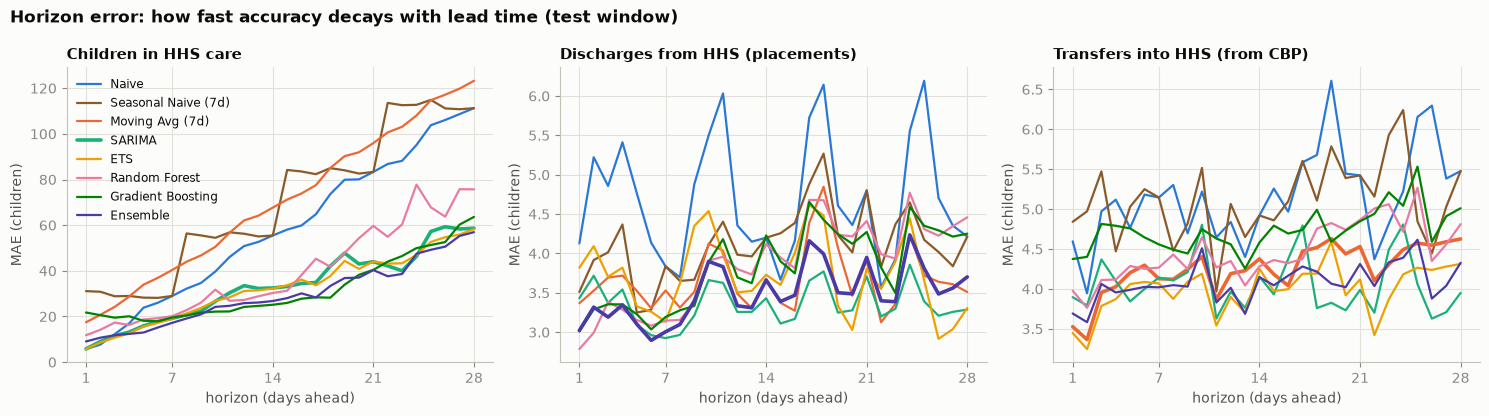

In [57]:
# Horizon error curves: MAE by forecast horizon in the test window (small multiples, one per target)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
by_h = S[S["period"] == "test"].groupby(["target", "model", "h"])["error"].apply(lambda e: e.abs().mean()).reset_index(name="MAE")
for ax, col in zip(axes, TARGETS):
    for m in MODEL_ORDER:
        g = by_h[(by_h["target"] == col) & (by_h["model"] == m)]
        ax.plot(g["h"], g["MAE"], color=MODEL_COLORS[m], lw=2.6 if m == CHAMPION[col] else 1.6, label=m)
    ax.set_title(LABELS[col], fontsize=10.5); ax.set_xlabel("horizon (days ahead)"); ax.set_ylabel("MAE (children)")
    ax.set_xticks([1, 7, 14, 21, 28])
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Horizon error: how fast accuracy decays with lead time (test window)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "11_horizon_error")

**Observation:** For care load, naive error grows almost linearly from 5.7 children at 1 day to 111 at 28 days. At 1 day nothing beats "tomorrow = today". By day 14 the Ensemble and Gradient Boosting halve naive's error (26.8 and 25.1 vs 55.5) and SARIMA/ETS cut it by about 42%; by day 28 SARIMA, ETS and the Ensemble are all about half of naive (57–59). The Ensemble is the best care-load model at 15 of the 28 horizons. Flow errors stay almost flat (about 3–5 a day at every horizon), and SARIMA is the best discharge model at 19 of 28 horizons.

In [58]:
# Short- vs medium-term reliability: MAE by horizon bucket (week 1 … week 4)
S = S.assign(bucket=pd.cut(S["h"], [0, 7, 14, 21, 28], labels=["1–7d", "8–14d", "15–21d", "22–28d"]))
bucket_tbl = (S[S["period"] == "test"].groupby(["target", "model", "bucket"], observed=True)["error"]
              .apply(lambda e: e.abs().mean()).unstack("bucket").round(1))
bucket_tbl

bucket                           1–7d  8–14d  15–21d  22–28d
target      model                                           
discharged  ETS                   3.6    3.9     3.8     3.5
            Ensemble              3.1    3.5     3.7     3.6
            Gradient Boosting     3.2    3.8     4.2     4.1
            Moving Avg (7d)       3.5    3.6     3.9     3.6
            Naive                 4.5    4.6     4.7     4.6
            Random Forest         3.1    3.7     4.3     4.3
            SARIMA                3.3    3.3     3.4     3.3
            Seasonal Naive (7d)   3.7    4.0     4.5     4.1
hhs_care    ETS                  13.1   28.0    38.8    51.1
            Ensemble             13.0   24.0    33.7    48.4
            Gradient Boosting    19.7   23.0    32.3    53.3
            Moving Avg (7d)      29.4   56.5    84.1   112.9
            Naive                17.9   44.9    71.7   100.5
            Random Forest        16.9   27.7    46.0    68.3
            SARIMA               13.4   28.4    39.9    52.0
            Seasonal Naive (7d)  29.3   55.7    83.5   112.3
transferred ETS                   3.8    4.0     4.1     4.1
            Ensemble              3.9    4.0     4.2     4.2
            Gradient Boosting     4.6    4.5     4.8     5.0
            Moving Avg (7d)       3.9    4.2     4.4     4.5
            Naive                 4.8    4.9     5.5     5.4
            Random Forest         4.1    4.3     4.6     4.8
            SARIMA                4.0    4.1     4.0     4.0
            Seasonal Naive (7d)   5.0    4.8     5.3     5.3

**Observation:** Week-1 care-load forecasts are already precise (about 13 children for SARIMA, ETS and the Ensemble). By week 4 those models plus Gradient Boosting err by 48–53 children versus 100.5 for naive, about half. Gradient Boosting is the best model in weeks 2–3 (23.0 and 32.3), while SARIMA keeps discharge error flat at 3.3–3.4 in every week.

In [59]:
# Statistical vs machine-learning: best model of each family by horizon bucket (test MAE)
FAMILY = {"Naive": "Baseline", "Seasonal Naive (7d)": "Baseline", "Moving Avg (7d)": "Baseline", "SARIMA": "Statistical", "ETS": "Statistical",
          "Random Forest": "Machine learning", "Gradient Boosting": "Machine learning", "Ensemble": "Ensemble"}
fam = bucket_tbl.reset_index().assign(family=lambda d: d["model"].map(FAMILY))
fam_best = fam.groupby(["target", "family"])[["1–7d", "8–14d", "15–21d", "22–28d"]].min()
fam_best

bucket                        1–7d  8–14d  15–21d  22–28d
target      family                                       
discharged  Baseline           3.5    3.6     3.9     3.6
            Ensemble           3.1    3.5     3.7     3.6
            Machine learning   3.1    3.7     4.2     4.1
            Statistical        3.3    3.3     3.4     3.3
hhs_care    Baseline          17.9   44.9    71.7   100.5
            Ensemble          13.0   24.0    33.7    48.4
            Machine learning  16.9   23.0    32.3    53.3
            Statistical       13.1   28.0    38.8    51.1
transferred Baseline           3.9    4.2     4.4     4.5
            Ensemble           3.9    4.0     4.2     4.2
            Machine learning   4.1    4.3     4.6     4.8
            Statistical        3.8    4.0     4.0     4.0

**Observation:** Statistical models are the best family for discharges from week 2 onwards (3.3–3.4 vs 3.7–4.2 for ML) and beat ML for transfers in every week. For the care-load stock, ML is best in weeks 2–3 and the Ensemble in weeks 1 and 4. No single family wins everywhere: statistical models suit the flows, while ML and the Ensemble add value for the stock. The Ensemble is never the worst family for any series or week, which makes it a safe default when the best model for a series is uncertain.

In [60]:
# Diebold–Mariano test: is the champion significantly better than naive persistence? (HAC variance, Harvey correction)
def diebold_mariano(e1, e2, h):
    e1, e2 = np.asarray(e1, float), np.asarray(e2, float)
    if len(e1) != len(e2) or len(e1) < 2:
        return np.nan, np.nan                        # undefined: mismatched inputs or too few pairs
    d = np.abs(e1) - np.abs(e2)                      # loss differential (absolute error)
    n, dbar = len(d), d.mean()
    gamma = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(min(h, n))]
    var = (gamma[0] + 2 * sum((1 - k / h) * gamma[k] for k in range(1, len(gamma)))) / n   # Bartlett weights keep the variance positive
    corr = (n + 1 - 2 * h + h * (h - 1) / n) / n    # Harvey, Leybourne & Newbold small-sample correction
    if var <= 0 or corr <= 0:
        return (0.0, 1.0) if np.allclose(d, 0) else (np.nan, np.nan)    # identical forecasts: no difference; otherwise undefined
    stat = dbar / np.sqrt(var) * np.sqrt(corr)
    return stat, 2 * stats.t.sf(abs(stat), df=n - 1)


dm_rows = []
for col in TARGETS:
    T = S[(S["period"] == "test") & (S["target"] == col)]
    for h in (1, 7, 14, 28):
        a = T[(T["model"] == CHAMPION[col]) & (T["h"] == h)].set_index("origin")["error"]
        b = T[(T["model"] == "Naive") & (T["h"] == h)].set_index("origin")["error"]
        a, b = a.align(b, join="inner")
        if CHAMPION[col] == "Naive" or len(a) < 10:
            continue
        stat, p = diebold_mariano(a.to_numpy(), b.to_numpy(), h)
        dm_rows.append({"target": col, "champion": CHAMPION[col], "h": h, "MAE champion": a.abs().mean(),
                        "MAE naive": b.abs().mean(), "DM stat": stat, "p-value": p, "significant (5%)": p < 0.05})
pd.DataFrame(dm_rows).round(3)

,target,champion,h,MAE champion,MAE naive,DM stat,p-value,significant (5%)
0,hhs_care,SARIMA,1,5.799,5.723,0.137,0.892,False
1,hhs_care,SARIMA,7,19.192,29.000,-1.990,0.052,False
2,hhs_care,SARIMA,14,32.498,55.480,-2.061,0.045,True
3,hhs_care,SARIMA,28,58.643,111.238,-20.918,0.000,True
4,discharged,Ensemble,1,3.021,4.128,-2.793,0.008,True
5,discharged,Ensemble,7,3.005,3.836,-3.056,0.003,True
6,discharged,Ensemble,14,3.664,4.200,-1.837,0.072,False
7,discharged,Ensemble,28,3.703,4.214,-1.066,0.292,False
8,transferred,Moving Avg (7d),1,3.527,4.596,-2.176,0.035,True
9,transferred,Moving Avg (7d),7,4.127,5.145,-1.588,0.118,False


**Observation:** For care load the champion's gain over naive is not significant at 1 day (p = 0.89) but becomes significant at 14 days (p = 0.045) and 28 days (p < 0.001), the horizons that matter for capacity planning. For discharges the Ensemble's gain is significant at 1 and 7 days (p ≤ 0.008), and for transfers only at 1 day (p = 0.035). At longer horizons the flow forecasts still have 11–20% lower error than naive, but that advantage is not statistically significant.

In [61]:
# ARIMA vs SARIMA out of sample: walk-forward the best specification of the OTHER family and compare MAE (calibration = decision window, test = report)
def fmt_spec(order, seas):
    return f"ARIMA{tuple(order)}" if seas[0] == 0 and seas[2] == 0 else f"SARIMA{tuple(order)}x{tuple(seas)}"


alt_rows, t_alt = [], time.time()
lead_idx = leader.set_index(["target", "period", "model"])
for col, kind in TARGETS.items():
    g = GRIDS[col]; seasonal = g["seasonal"].apply(lambda s: s[0] > 0 or s[2] > 0)
    alt = g[~seasonal].iloc[0] if seasonal.iloc[0] else g[seasonal].iloc[0]
    m_alt = SarimaModel(alt["order"], alt["seasonal"], alt["trend"]); m_alt.name = "alternative"
    out, _ = walk_forward(col, kind, models=[m_alt])
    out["y"] = daily[col].reindex(out["date"]).to_numpy()
    keep = (daily["is_reported"] & OBSERVED[col]).reindex(out["date"], fill_value=False).to_numpy() & out["y"].notna().to_numpy()
    out = out[keep].assign(error=lambda x: x["y"] - x["yhat"], period=lambda x: np.where(x["origin"] < TEST_START, "calibration", "test"))
    for per, gg in out.groupby("period"):
        alt_rows.append({"series": col, "period": per, "selected (lowest AIC)": fmt_spec(*SARIMA_SPECS[col][:2]),
                         "MAE selected": lead_idx.at[(col, per, "SARIMA"), "MAE"], "other family": fmt_spec(alt["order"], alt["seasonal"]),
                         "MAE other": gg["error"].abs().mean()})
ARIMA_OOS = pd.DataFrame(alt_rows).set_index(["series", "period"]).round(2)
print(f"Alternative specifications walked forward in {time.time() - t_alt:.0f}s")
ARIMA_OOS

Alternative specifications walked forward in 24s


selected (lowest AIC)  MAE selected                  other family  MAE other
series      period                                                                                          
hhs_care    calibration                ARIMA(1, 1, 1)         55.10  SARIMA(1, 1, 1)x(1, 0, 1, 7)      55.27
            test                       ARIMA(1, 1, 1)         32.00  SARIMA(1, 1, 1)x(1, 0, 1, 7)      31.31
discharged  calibration  SARIMA(1, 0, 1)x(1, 0, 1, 7)          4.09                ARIMA(1, 0, 2)       4.76
            test         SARIMA(1, 0, 1)x(1, 0, 1, 7)          3.33                ARIMA(1, 0, 2)       3.38
transferred calibration                ARIMA(1, 0, 0)          4.47  SARIMA(1, 0, 0)x(1, 0, 1, 7)       4.60
            test                       ARIMA(1, 0, 0)          4.04  SARIMA(1, 0, 0)x(1, 0, 1, 7)       4.07

**Observation:** Out-of-sample errors on the calibration window, the decision window, confirm the AIC choices for all three series: care load 55.1 vs 55.3, discharges 4.09 vs 4.76 and transfers 4.47 vs 4.60 (selected vs other family). On the test window the seasonal care-load model happens to be slightly better (31.3 vs 32.0 children, 2%). Switching after seeing that number would be test-set selection, so the specification stands.

### Recursive vs direct multi-horizon strategy

The main ML models use the **direct** strategy (one model that is told the horizon). The alternative is **recursive**: a one-step model fed its own predictions for 28 steps. To isolate the strategy, both versions below use the same learner (Gradient Boosting, 100 trees, depth 3, Huber loss), the same recency weights, the same target-only inputs (the last 14 transformed values, their 7- and 14-day means, and the target weekday) and the same walk-forward origins, refitted every 28 days. The recursive model must step through every calendar day, so it is trained on interpolated Friday/Saturday values too; the direct model trains on reported targets only. Both are scored on reported days only.

In [62]:
# Recursive vs direct, same learner and inputs: walk-forward on every origin, refit every 28 days (care load = log-change, discharges = log1p)
RD_LAGS = 14
DOW = daily.index.dayofweek.to_numpy()


def rd_transform(col, kind):
    y = daily[col]
    return (np.log(y / y.shift(1)) if kind == "stock" else np.log1p(y)).to_numpy()


def rd_rows(x, pos):
    """Target-only inputs at positions pos: the last 14 transformed values and their 7- and 14-day means."""
    L = np.stack([x[pos - k] for k in range(RD_LAGS)], axis=1)
    return np.column_stack([L, L[:, :7].mean(1), L.mean(1)])


def make_rd_gb():
    return GradientBoostingRegressor(n_estimators=100, learning_rate=0.08, max_depth=3, subsample=0.8, loss="huber", random_state=SEED)


rd_out, t_rd = [], time.time()
rep_pos = np.flatnonzero(daily["is_reported"].to_numpy())
for col, kind in (("hhs_care", "stock"), ("discharged", "flow")):
    x, y = rd_transform(col, kind), daily[col].to_numpy()
    ok_target = (daily["is_reported"] & OBSERVED[col]).to_numpy()
    start, last_fit, hs = POS[ML_START], None, np.arange(1, H + 1)
    for t in ORIGINS:
        p = POS[t]
        if last_fit is None or (t - last_fit).days >= 28:
            wts = lambda pos: 0.5 ** ((p - pos) / ML_HALF_LIFE)
            s1 = np.arange(start, p)                                                   # one-step pairs (s → s+1), all known at t
            rec = make_rd_gb().fit(np.column_stack([rd_rows(x, s1), DOW[s1 + 1]]), x[s1 + 1], sample_weight=wts(s1))
            Xs, zs, ws = [], [], []
            for h in hs:
                s = rep_pos[(rep_pos >= start) & (rep_pos + h <= p)]
                s = s[ok_target[s + h]]
                Xs.append(np.column_stack([rd_rows(x, s), DOW[s + h], np.full(len(s), h)]))
                zs.append(np.log(y[s + h] / y[s]) if kind == "stock" else x[s + h]); ws.append(wts(s))
            direct = make_rd_gb().fit(np.vstack(Xs), np.concatenate(zs), sample_weight=np.concatenate(ws))
            last_fit = t
        base = rd_rows(x, np.array([p]))[0]
        zd = direct.predict(np.column_stack([np.tile(base, (H, 1)), (DOW[p] + hs) % 7, hs]))
        f_direct = y[p] * np.exp(zd) if kind == "stock" else np.clip(np.expm1(zd), 0, None)
        hist, level, f_rec = list(x[p - RD_LAGS + 1:p + 1]), y[p], []
        for h in hs:
            L = np.array(hist[::-1][:RD_LAGS])
            xh = rec.predict(np.r_[L, L[:7].mean(), L.mean(), (DOW[p] + h) % 7][None])[0]
            hist.append(xh)
            level = level * np.exp(xh) if kind == "stock" else max(np.expm1(xh), 0)
            f_rec.append(level)
        for strat, f in (("Direct", f_direct), ("Recursive", np.array(f_rec))):
            rd_out.append(pd.DataFrame({"target": col, "strategy": strat, "origin": t, "h": hs, "date": t + pd.to_timedelta(hs, "D"), "yhat": f}))
RD = pd.concat(rd_out, ignore_index=True)
RD["y"] = [daily.at[d, c] if d <= T_END else np.nan for d, c in zip(RD["date"], RD["target"])]
RD["ok"] = [bool(daily.at[d, "is_reported"] and OBSERVED.at[d, c]) if d <= T_END else False for d, c in zip(RD["date"], RD["target"])]
RD = RD[RD["ok"]].assign(error=lambda x: x["y"] - x["yhat"], period=lambda x: np.where(x["origin"] < TEST_START, "calibration", "test"))
RD_TABLE = (RD.assign(bucket=pd.cut(RD["h"], [0, 7, 14, 21, 28], labels=["1–7d", "8–14d", "15–21d", "22–28d"]))
            .groupby(["target", "period", "strategy", "bucket"], observed=True)["error"].apply(lambda e: e.abs().mean()).unstack("bucket").round(2))
print(f"Recursive vs direct: {RD['origin'].nunique()} origins × 2 series in {time.time() - t_rd:.0f}s")
RD_TABLE

Recursive vs direct: 124 origins × 2 series in 41s


bucket                             1–7d  8–14d  15–21d  22–28d
target     period      strategy                               
discharged calibration Direct      5.82   4.94    4.89    4.23
                       Recursive   5.20   4.82    5.30    4.96
           test        Direct      3.47   3.64    3.61    3.68
                       Recursive   3.16   3.77    4.13    4.17
hhs_care   calibration Direct     41.72  67.79  108.04  144.05
                       Recursive  21.45  58.60  102.28  142.53
           test        Direct     24.30  27.00   41.09   64.68
                       Recursive  12.96  23.85   33.08   40.63

**Observation:** With the same learner and inputs, the **recursive** strategy is more accurate for care load in every week of both windows (test: 13.0 vs 24.3 children in week 1, 40.6 vs 64.7 in week 4), because a one-step model of the daily log-change compounds smoothly. For discharges the result is mixed: recursive is better in week 1 (3.16 vs 3.47 on test) but worse from week 3 (4.13–4.17 vs 3.61–3.68), as its own errors feed back into its inputs. On the calibration window neither variant comes close to the care-load champion (week averages of about 81 children for recursive vs SARIMA's 55), although recursive would have beaten it on the test window (about 28 vs 32). The production design is therefore unchanged, and a recursive care-load learner is recorded as a candidate for the next model review.

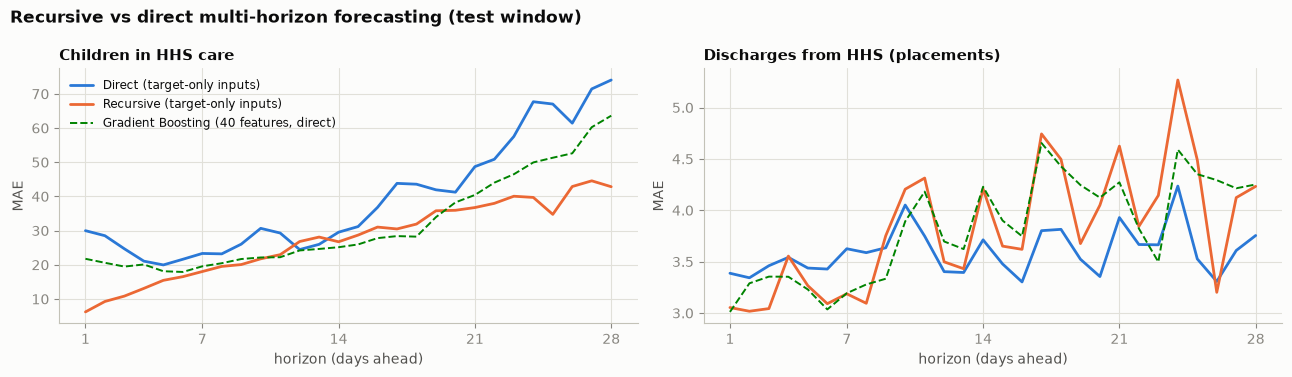

In [63]:
# Horizon error of the two strategies on the test window, with the full 40-feature direct Gradient Boosting model for reference
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
STRAT_COLORS = {"Direct": "#2a78d6", "Recursive": "#eb6834"}
for ax, col in zip(axes, ("hhs_care", "discharged")):
    for strat, colr in STRAT_COLORS.items():
        g = RD[(RD["target"] == col) & (RD["strategy"] == strat) & (RD["period"] == "test")].groupby("h")["error"].apply(lambda e: e.abs().mean())
        ax.plot(g.index, g.values, color=colr, lw=2, label=f"{strat} (target-only inputs)")
    ref = by_h[(by_h["target"] == col) & (by_h["model"] == "Gradient Boosting")]
    ax.plot(ref["h"], ref["MAE"], color=MODEL_COLORS["Gradient Boosting"], lw=1.4, ls="--", label="Gradient Boosting (40 features, direct)")
    ax.set_title(LABELS[col], fontsize=10.5); ax.set_xlabel("horizon (days ahead)"); ax.set_ylabel("MAE"); ax.set_xticks([1, 7, 14, 21, 28])
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Recursive vs direct multi-horizon forecasting (test window)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "11b_recursive_vs_direct")

**Observation:** On the test window, recursive care-load errors stay below the direct target-only model at every horizon. Against the full 40-feature Gradient Boosting model they are lower in week 1 (13.0 vs 19.7) and week 4 (40.6 vs 53.3) and level in weeks 2–3 (23.9 vs 23.0, 33.1 vs 32.3), so the strategy matters most at the shortest and longest lead times. For discharges the two strategies cross after about a week, after which the direct one is steadier. This supports direct models for the noisy flows and a recursive trial for the smooth stock.

## 12. Uncertainty quantification: conformal intervals

A point forecast cannot answer "how bad could it get?". For every model, target and horizon I take the **empirical distribution of calibration-window errors** (pooled over neighbouring horizons h ± 2 for stability) and add its quantiles to the point forecast. This is split-conformal prediction: distribution-free and honest, because the test window never touched the calibration.

In [64]:
# Residual quantiles per (target, model, horizon) from a chosen evaluation period
QUANTS = {"lo95": 0.025, "lo80": 0.10, "hi80": 0.90, "hi95": 0.975}


def residual_quantiles(frame):
    out = []
    for (col, m), g in frame.groupby(["target", "model"]):
        for h in range(1, H + 1):
            e = g.loc[(g["h"] - h).abs() <= 2, "error"]
            out.append({"target": col, "model": m, "h": h, **{k: e.quantile(q) for k, q in QUANTS.items()}})
    return pd.DataFrame(out)


Q_CAL = residual_quantiles(S[S["period"] == "calibration"])
TEST = S[S["period"] == "test"].merge(Q_CAL, on=["target", "model", "h"])
for k in QUANTS:
    TEST[k] = TEST["yhat"] + TEST[k]
TEST["in80"] = TEST["y"].between(TEST["lo80"], TEST["hi80"])
TEST["in95"] = TEST["y"].between(TEST["lo95"], TEST["hi95"])
coverage = TEST.groupby(["target", "model"]).agg(coverage80=("in80", "mean"), coverage95=("in95", "mean"),
                                                  width80=("hi80", lambda s: (s - TEST.loc[s.index, "lo80"]).mean())).round(3)
coverage

coverage80  coverage95  width80
target      model                                               
discharged  ETS                       0.890       0.982   15.223
            Ensemble                  0.772       0.963   11.829
            Gradient Boosting         0.743       0.955   13.850
            Moving Avg (7d)           0.945       0.990   16.883
            Naive                     0.957       0.996   21.246
            Random Forest             0.742       0.949   14.925
            SARIMA                    0.862       0.988   12.703
            Seasonal Naive (7d)       0.916       0.984   17.427
hhs_care    ETS                       0.926       0.984  166.755
            Ensemble                  0.976       0.998  221.427
            Gradient Boosting         1.000       1.000  301.447
            Moving Avg (7d)           0.978       1.000  316.800
            Naive                     0.948       1.000  267.352
            Random Forest             0.979       0.996  301.534
            SARIMA                    0.916       0.975  165.735
            Seasonal Naive (7d)       0.946       1.000  318.754
transferred ETS                       0.662       0.881   11.290
            Ensemble                  0.684       0.907   11.049
            Gradient Boosting         0.595       0.816   11.398
            Moving Avg (7d)           0.660       0.843   11.187
            Naive                     0.727       0.908   13.669
            Random Forest             0.640       0.855   11.670
            SARIMA                    0.800       0.958   12.435
            Seasonal Naive (7d)       0.710       0.912   14.015

**Observation:**
* **Care load:** intervals are conservative. Nominal 80% bands contain the actual value 92–100% of the time because the calibration window included the larger summer-2025 swings; erring wide is the safe side for capacity planning.
* **Discharges:** the statistical models are close to target (86–89%); Random Forest and Gradient Boosting are slightly narrow (74%), the Ensemble 77%.
* **Transfers:** most bands are too narrow (60–73%), with only SARIMA on target (80%). The cause is not higher volatility, since transfers were actually steadier in the test window (SD 4.7 vs 5.0 a day). Instead, most models under-forecast by 1–2 transfers a day during calibration but not during the test, so the calibrated bands ended up off-centre. Use the 95% band for intake planning; the production forecast recalibrates on the latest 26 weeks.

### 12.1 Rolling-origin recalibration (open defect D-MOD-01)

The fixed calibration window cannot react when a model's bias changes. The production forecast already uses a different rule: at its origin it takes the error quantiles of **all walk-forward forecasts whose target date has already been observed**, from the last 26 weeks of origins. Here that exact rule is replayed at every test origin *t*: only errors with target date ≤ *t* (observable at the time) from origins in the previous 182 days (and, as a sensitivity check, 91 days) are used, so there is no look-ahead. The method was fixed before looking at its test results; the test window only reports how it would have performed in real time.

In [65]:
# Rolling-origin conformal: at each test origin use only errors already observable (target date <= origin) from the previous L days of origins
def rolling_quantiles(frame, lookback, min_errors=30):
    out = []
    test_origins = ORIGINS[ORIGINS >= TEST_START]
    for (col, m), g in frame.groupby(["target", "model"]):
        o, d, hh, e = (g[c].to_numpy() for c in ("origin", "date", "h", "error"))
        for t in test_origins:
            known = (d <= t.to_datetime64()) & (o >= (t - pd.Timedelta(days=lookback)).to_datetime64())
            for h in range(1, H + 1):
                sel = e[known & (np.abs(hh - h) <= 2)]
                q = np.quantile(sel, list(QUANTS.values())) if len(sel) >= min_errors else [np.nan] * len(QUANTS)
                out.append((col, m, t, h, *q))
    return pd.DataFrame(out, columns=["target", "model", "origin", "h", *QUANTS])


def coverage_of(qtab, keys):
    T = S[S["period"] == "test"].merge(qtab, on=keys)
    for k in QUANTS:
        T[k] = T["yhat"] + T[k]
    T = T.dropna(subset=list(QUANTS))
    return T.assign(in80=T["y"].between(T["lo80"], T["hi80"]), in95=T["y"].between(T["lo95"], T["hi95"]), width80=T["hi80"] - T["lo80"])


t_rq = time.time()
COV_METHODS = {"fixed calibration (13 wk)": coverage_of(Q_CAL, ["target", "model", "h"])}
for L in (182, 91):
    COV_METHODS[f"rolling origin ({L // 7} wk)"] = coverage_of(rolling_quantiles(S, L), ["target", "model", "origin", "h"])
COV_COMPARE = pd.concat({name: T.groupby(["target", "model"]).agg(coverage80=("in80", "mean"), coverage95=("in95", "mean"), width80=("width80", "mean"))
                         for name, T in COV_METHODS.items()}, axis=1).round(3)
print(f"Rolling quantiles computed in {time.time() - t_rq:.0f}s")
COV_COMPARE.loc[list(dict.fromkeys([(c, CHAMPION[c]) for c in TARGETS] + [(c, "Ensemble") for c in TARGETS]))].sort_index()

Rolling quantiles computed in 12s


fixed calibration (13 wk)                     rolling origin (26 wk)                     rolling origin (13 wk)             \
                                           coverage80 coverage95  width80             coverage80 coverage95  width80             coverage80 coverage95   
target      model                                                                                                                                        
discharged  Ensemble                            0.772      0.963   11.829                  0.787      0.961   11.313                  0.779      0.929   
hhs_care    Ensemble                            0.976      0.998  221.427                  0.965      0.996  202.119                  0.851      0.947   
            SARIMA                              0.916      0.975  165.735                  0.902      0.967  150.498                  0.817      0.945   
transferred Ensemble                            0.684      0.907   11.049                  0.719      0.908   11.412                  0.693      0.859   
            Moving Avg (7d)                     0.660      0.843   11.187                  0.684      0.861   11.580                  0.711      0.868   

                                      
                             width80  
target      model                     
discharged  Ensemble          10.162  
hhs_care    Ensemble         128.250  
            SARIMA           108.377  
transferred Ensemble          11.281  
            Moving Avg (7d)   12.285

**Observation:** Rolling recalibration helps only modestly and does **not** fix D-MOD-01. For the transfer champion (7-day moving average) 80% coverage moves from 66.0% with the fixed calibration window to 68.4% with the production 26-week rule and 71.1% with a 13-week window, still well below 80%; the transfer Ensemble improves from 68.4% to 71.9%. For care load the rolling rule narrows the over-wide bands (SARIMA width 166 → 150 children at 90% coverage), and a 13-week window is almost exactly calibrated (81.7%) with bands about 35% narrower (108). The discharge Ensemble moves closer to target (77.2% → 78.7%). Shorter windows react faster but lose 95% coverage (transfers 86–87%, care 94.5%). The remaining transfer gap reflects the early-test bias shift, which an empirical window absorbs only slowly; adaptive conformal methods are the documented next step, and intake planning should keep using the 95% band.

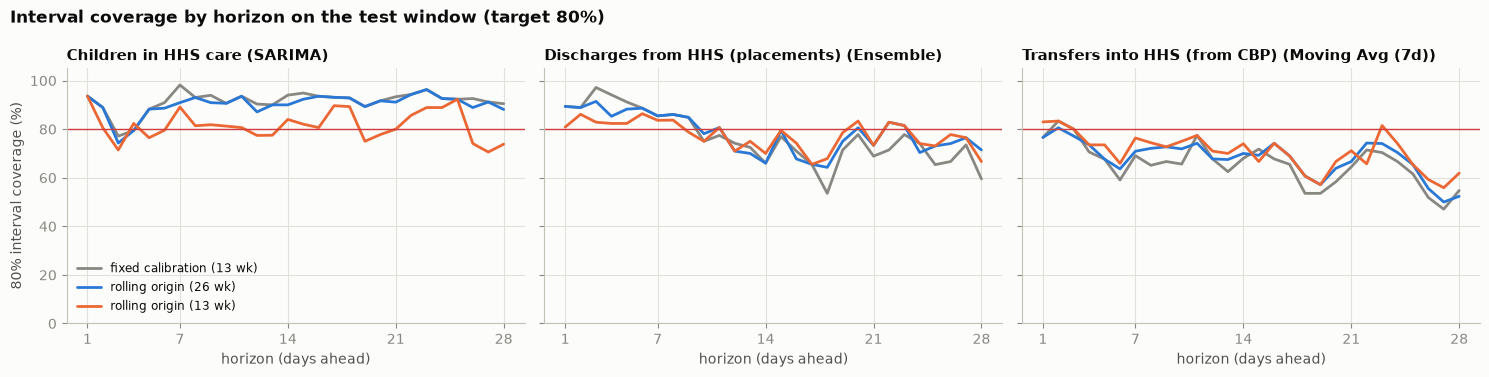

In [66]:
# Coverage by horizon (champion models): does calibration hold from day 1 to day 28 under both methods?
cov_h = pd.concat({name: T.groupby(["target", "model", "h"])["in80"].mean() for name, T in COV_METHODS.items()}, axis=1)
COV_BY_H = cov_h.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
METHOD_COLORS = dict(zip(COV_METHODS, ["#898781", "#2a78d6", "#eb6834"]))
for ax, col in zip(axes, TARGETS):
    g = COV_BY_H[(COV_BY_H["target"] == col) & (COV_BY_H["model"] == CHAMPION[col])]
    for name, colr in METHOD_COLORS.items():
        ax.plot(g["h"], g[name] * 100, color=colr, lw=2, label=name)
    ax.axhline(80, color=STATUS["critical"], lw=1); ax.set_ylim(0, 105)
    ax.set_title(f"{LABELS[col]} ({CHAMPION[col]})", fontsize=10.5); ax.set_xlabel("horizon (days ahead)"); ax.set_xticks([1, 7, 14, 21, 28])
axes[0].set_ylabel("80% interval coverage (%)"); axes[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Interval coverage by horizon on the test window (target 80%)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "12b_coverage_by_horizon")

**Observation:** Under-coverage is concentrated in multi-week flow forecasts. The discharge Ensemble covers 84–91% of actuals in week 1 but 70–76% in week 4 (depending on the method), and the transfer moving average 72–77% in week 1 versus 61–66% in week 4, with single horizons as low as 47–56%. Care-load coverage averages 82–93% per week under every method, although single horizons dip to 71–77%. Each point rests on only 42–55 test forecasts, so the curves are noisy and week-level averages are the safer reading.

In [67]:
# Multi-horizon scorecard at operational lead times (1, 7, 14, 28 days; test window): accuracy, bias and coverage of the rolling 26-week intervals
roll = COV_METHODS["rolling origin (26 wk)"].set_index(["target", "model", "origin", "h"])[["in80", "in95"]]
Tm = S[(S["period"] == "test") & S["h"].isin([1, 7, 14, 28])].join(roll, on=["target", "model", "origin", "h"])
Tm[["in80", "in95"]] = Tm[["in80", "in95"]].astype(float)          # NaN where too few observable errors existed
SCORECARD = Tm.groupby(["target", "model", "h"]).apply(lambda g: pd.concat([score(g), pd.Series({"coverage80": g["in80"].mean(), "coverage95": g["in95"].mean()})]))
SCORECARD = SCORECARD.drop(columns=["zero y excluded"]).astype({"n": int})
show = [(c, m) for c in TARGETS for m in dict.fromkeys(["Naive", "Seasonal Naive (7d)", CHAMPION[c], "Ensemble"])]
SCORECARD.reset_index().set_index(["target", "model"]).loc[show].reset_index().set_index(["target", "model", "h"]).round(2)

MAE    RMSE  MAPE %  WAPE %  Accuracy %    Bias   n  coverage80  coverage95
target      model               h                                                                                 
hhs_care    Naive               1     5.72    6.78    0.25    0.25       99.75   -2.32  47        0.94        1.00
                                7    29.00   31.15    1.25    1.25       98.75  -26.82  55        0.93        1.00
                                14   55.48   58.94    2.38    2.39       97.61  -55.40  50        0.92        1.00
                                28  111.24  113.92    4.72    4.73       95.27 -111.24  42        0.98        1.00
            Seasonal Naive (7d) 1    31.11   33.14    1.36    1.35       98.65  -28.55  47        0.87        1.00
                                7    29.00   31.15    1.25    1.25       98.75  -26.82  55        1.00        1.00
                                14   55.48   58.94    2.38    2.39       97.61  -55.40  50        1.00        1.00
                                28  111.24  113.92    4.72    4.73       95.27 -111.24  42        0.95        1.00
            SARIMA              1     5.80    7.05    0.25    0.25       99.75    1.57  47        0.94        1.00
                                7    19.19   23.92    0.84    0.83       99.17   -2.97  55        0.91        0.98
                                14   32.50   41.48    1.40    1.40       98.60  -13.77  50        0.90        0.96
                                28   58.64   78.67    2.48    2.49       97.51  -43.95  42        0.88        0.95
            Ensemble            1     9.07   11.11    0.40    0.40       99.60    4.07  47        0.94        1.00
                                7    17.23   21.27    0.76    0.75       99.25   -1.70  55        0.96        1.00
                                14   26.78   35.13    1.16    1.15       98.85  -12.72  50        0.98        1.00
                                28   56.93   73.43    2.42    2.42       97.58  -52.39  42        0.98        1.00
discharged  Naive               1     4.13    5.14   40.21   37.74       62.26   -1.45  47        0.96        1.00
                                7     3.84    4.74   48.99   38.22       61.78   -0.13  55        0.93        1.00
                                14    4.20    5.14   55.47   43.48       56.52    0.68  50        0.92        1.00
                                28    4.21    5.24   63.60   43.81       56.19    0.88  42        0.83        0.95
            Seasonal Naive (7d) 1     3.51    4.43   37.56   32.10       67.90    0.06  47        0.94        1.00
                                7     3.84    4.74   48.99   38.22       61.78   -0.13  55        0.89        0.96
                                14    4.20    5.14   55.47   43.48       56.52    0.68  50        0.88        0.96
                                28    4.21    5.24   63.60   43.81       56.19    0.88  42        0.83        0.98
            Ensemble            1     3.02    3.81   33.53   27.63       72.37    0.31  47        0.89        1.00
                                7     3.01    3.78   41.00   29.94       70.06    0.27  55        0.85        0.98
                                14    3.66    4.33   52.79   37.93       62.07    1.12  50        0.66        0.96
                                28    3.70    4.44   60.40   38.49       61.51    1.78  42        0.71        0.90
transferred Naive               1     4.60    5.79   54.48   43.72       56.28   -0.34  47        0.81        0.96
                                7     5.15    6.60   65.09   49.30       50.70    0.35  55        0.78        0.95
                                14    4.92    6.63   59.61   47.67       52.33    0.48  50        0.74        0.92
                                28    5.48    7.18   75.63   54.76       45.24    1.67  42        0.69        0.86
            Seasonal Naive (7d) 1     4.84    6.06   61.65   46.05       53.95    0.24  47        0.83        0.96
              

**Observation:** The scorecard gives each planning lead time its own numbers. SARIMA's care-load error grows from 5.8 children at 1 day to 19.2 at 7, 32.5 at 14 and 58.6 at 28 days (accuracy 99.8% → 97.5%), 34% below naive at 7 days and 41–47% below at 14–28 days, with a growing under-forecast during the steady test-window climb (bias −3 at 7 days, −44 at 28). Seasonal naive equals naive at 7, 14 and 28 days by construction (the anchor is the origin day itself) and is worse at 1 day (31.1). Discharge Ensemble error stays at 3.0–3.7 a day with a small over-forecast (+0.3 to +1.8), and the transfer moving average at 3.5–4.6. Coverage of the rolling 26-week 80% intervals is 88–94% for care load but only 66–71% for discharges at 14–28 days and 52–77% for transfers, which again marks the flow intervals as the weak spot.

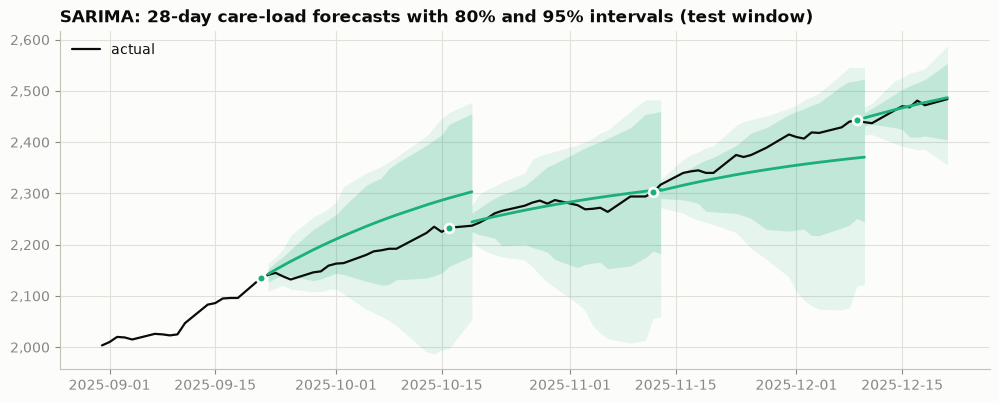

In [68]:
# Fan chart: champion care-load forecasts issued at four test origins, with calibrated 80% / 95% bands
col = "hhs_care"; champ = CHAMPION[col]
fan_origins = ORIGINS[ORIGINS >= TEST_START][::18][:4]
fig, ax = plt.subplots(figsize=(12, 4.4))
hist = daily.loc[TEST_START - pd.Timedelta(days=21):, col]
ax.plot(hist.index, hist, color=INK, lw=1.6, label="actual")
for o in fan_origins:
    g = TEST[(TEST["target"] == col) & (TEST["model"] == champ) & (TEST["origin"] == o)].sort_values("date")
    ax.fill_between(g["date"], g["lo95"], g["hi95"], color=MODEL_COLORS[champ], alpha=0.10, lw=0)
    ax.fill_between(g["date"], g["lo80"], g["hi80"], color=MODEL_COLORS[champ], alpha=0.18, lw=0)
    ax.plot(g["date"], g["yhat"], color=MODEL_COLORS[champ], lw=2)
    ax.scatter([o], [daily.at[o, col]], s=40, color=MODEL_COLORS[champ], edgecolor=SURFACE, linewidth=2, zorder=4)
ax.yaxis.set_major_formatter(COMMA)
ax.set_title(f"{champ}: 28-day care-load forecasts with 80% and 95% intervals (test window)")
ax.legend(["actual"], loc="upper left")
savefig(fig, "12_fan_chart")

**Observation:** For the four plotted forecast dates, 89–100% of actual values fall inside the 80% band, consistent with the conservative coverage above. The 16 Oct forecast was within 9 children at day 28, while the 12 Nov forecast under-shot by 68 (2,371 vs 2,439) because the climb accelerated. The bands widen with lead time, which is the uncertainty planners need to budget for.

## 13. Key performance indicators

| KPI | Definition used here |
|---|---|
| **Forecast Accuracy (%)** | 100 − WAPE on the test window (robust for small counts) |
| **Surge Lead Time** | days between the first sustained forecast alert and the actual threshold crossing |
| **Capacity Breach Probability** | P(care load > threshold) from the calibrated forecast distribution |
| **Forecast Stability Index (FSI)** | 100 / (1 + mean revision ÷ mean actual daily change); higher = steadier forecasts |
| **Model robustness** | win-rate vs naive across test weeks, error growth from week 1 to week 4, interval coverage |

In [69]:
# KPI 1: Forecast Accuracy (%) for every model and target on the untouched test window
ACCURACY = test_board.pivot(index="model", columns="target", values="Accuracy %").reindex(MODEL_ORDER)[list(TARGETS)].round(1)
ACCURACY

target,hhs_care,discharged,transferred
model,,,
Naive,97.6,53.0,50.2
Seasonal Naive (7d),97.1,58.3,50.5
Moving Avg (7d),97.1,62.9,58.8
SARIMA,98.6,65.9,60.7
ETS,98.7,62.3,61.3
Random Forest,98.4,61.2,56.8
Gradient Boosting,98.7,61.4,54.1
Ensemble,98.8,64.6,60.4


**Observation:** Care load is forecast with 97–99% accuracy by every model, so the differences that matter are at longer horizons and in the tails, not in this headline number. Flows are much harder: the best discharge model reaches 65.9% and the best transfer model 61.3%, versus 50–53% for naive. At about 10 events a day much of the daily variation is random, but it averages out over a week: summing the reported (Sunday–Thursday) days within each week cuts SARIMA's relative discharge error from 34% to 16% (naive: 37%). Weekly totals are therefore the better planning unit for placements.

In [70]:
# KPI 4: Forecast Stability Index: revisions to the forecast for the same date between consecutive origins
def stability_index(col, model):
    f = BT[(BT["target"] == col) & (BT["model"] == model) & (BT["period"] == "test")].sort_values(["date", "origin"])
    revision = f.groupby("date")["yhat"].diff().abs().mean()
    rep = daily.loc[TEST_START:T_END].query("is_reported")[col]
    natural = rep.diff().abs().mean()
    return 100 / (1 + revision / natural)


FSI = pd.DataFrame({col: {m: stability_index(col, m) for m in MODEL_ORDER} for col in TARGETS}).round(1)
FSI

,hhs_care,discharged,transferred
Naive,50.7,49.9,50.1
Seasonal Naive (7d),63.5,87.8,86.6
Moving Avg (7d),58.5,86.0,84.3
SARIMA,25.2,87.0,95.9
ETS,25.1,73.7,80.6
Random Forest,23.1,87.4,83.3
Gradient Boosting,33.1,84.1,82.2
Ensemble,30.2,86.5,87.6


**Observation:** Flow forecasts are much steadier than naive (FSI 74–96 vs 50), so they do not chase daily noise. The trend-following care-load models are less stable than naive (FSI 23–33 vs 51; the flat baselines are steadiest: seasonal naive 63.5 and moving average 58.5): when a new report changes the recent slope, the whole 28-day path tilts. Planners should read each run together with its interval and judge trends over several days rather than reacting to a single forecast.

In [71]:
# KPI 5: robustness scorecard (weekly win-rate vs naive, week-4 / week-1 error growth, 80% interval coverage)
def robustness(col, model):
    T = S[(S["period"] == "test") & (S["target"] == col)]
    wk = T.assign(week=T["origin"].dt.to_period("W")).groupby(["week", "model"])["error"].apply(lambda e: e.abs().mean()).unstack()
    win = (wk[model] < wk["Naive"]).mean() * 100 if model != "Naive" else np.nan
    mt = T[T["model"] == model]
    growth = mt.loc[mt["h"] > 21, "error"].abs().mean() / mt.loc[mt["h"] <= 7, "error"].abs().mean()
    return pd.Series({"win-rate vs naive %": win, "error growth wk4/wk1": growth,
                      "coverage80 %": coverage.loc[(col, model), "coverage80"] * 100, "FSI": FSI.loc[model, col],
                      "accuracy %": ACCURACY.loc[model, col]})


ROBUST = pd.concat({col: pd.DataFrame({m: robustness(col, m) for m in MODEL_ORDER}).T for col in TARGETS}).round(1)
ROBUST

win-rate vs naive %  error growth wk4/wk1  coverage80 %   FSI  accuracy %
hhs_care    Naive                                NaN                   5.6          94.8  50.7        97.6
            Seasonal Naive (7d)                  0.0                   3.8          94.6  63.5        97.1
            Moving Avg (7d)                      7.1                   3.8          97.8  58.5        97.1
            SARIMA                              85.7                   3.9          91.6  25.2        98.6
            ETS                                 85.7                   3.9          92.6  25.1        98.7
            Random Forest                       71.4                   4.0          97.9  23.1        98.4
            Gradient Boosting                   92.9                   2.7         100.0  33.1        98.7
            Ensemble                           100.0                   3.7          97.6  30.2        98.8
discharged  Naive                                NaN                   1.0          95.7  49.9        53.0
            Seasonal Naive (7d)                 85.7                   1.1          91.6  87.8        58.3
            Moving Avg (7d)                     85.7                   1.0          94.5  86.0        62.9
            SARIMA                              85.7                   1.0          86.2  87.0        65.9
            ETS                                 78.6                   1.0          89.0  73.7        62.3
            Random Forest                       85.7                   1.4          74.2  87.4        61.2
            Gradient Boosting                   85.7                   1.3          74.3  84.1        61.4
            Ensemble                            85.7                   1.2          77.2  86.5        64.6
transferred Naive                                NaN                   1.1          72.7  50.1        50.2
            Seasonal Naive (7d)                 50.0                   1.1          71.0  86.6        50.5
            Moving Avg (7d)                     78.6                   1.1          66.0  84.3        58.8
            SARIMA                              78.6                   1.0          80.0  95.9        60.7
            ETS                                 85.7                   1.1          66.2  80.6        61.3
            Random Forest                       57.1                   1.2          64.0  83.3        56.8
            Gradient Boosting                   50.0                   1.1          59.5  82.2        54.1
            Ensemble                            64.3                   1.1          68.4  87.6        60.4

**Observation:** The Ensemble is the most robust care-load model: it beat naive in 100% of test weeks at 98.8% accuracy. Gradient Boosting has the slowest error growth (2.7× from week 1 to week 4, vs 5.6× for naive), partly because its week-1 error is already high (19.7 vs naive's 17.9). Random Forest is the weakest modelled option for care load (71% win-rate, 4.0× growth). For flows, error barely grows with horizon (1.0–1.4×), so 4-week flow forecasts are about as reliable as 1-week ones.

### KPI 2: Surge lead time

A surge **event** is the first reported day the care load crosses above a threshold *C* after at least 14 days below it. An **alert** is raised at origin *t* when the **probability of exceeding *C* within 28 days reaches p\***. **Lead time** is the number of days between the start of the unbroken alert streak and the event. A threshold sweep turns one series into many events, which makes the KPI far more robust than a single hand-picked capacity number.

Alerting on the point forecast alone (p\* = 50%) proved too late during development: trend models smooth over the start of a surge. So I evaluate the whole **operating curve** (p\* from 50% down to 10%) and report detection rate, median lead and false-alarm rate, letting planners pick the sensitivity.

I measure it twice:
1. **Test window (2025)** with the champion care-load model and its calibrated (conformal) error distribution.
2. **Historical replay (2023–2024)**, which contains the program's large real surges (care load rose from about 5,700 to over 11,000). Because only the HHS columns are trustworthy in 2023, the replay uses a univariate damped-trend ETS model with analytic prediction intervals, re-estimated on a rolling 120-day window. This simulates what a planner would have seen in real time.

In [72]:
# Event detection, lead-time and false-alarm scoring shared by both evaluations
P_LEVELS = [0.5, 0.4, 0.3, 0.2, 0.1]   # alert when P(breach within 28 days) >= p*
P_STAR = 0.3                           # recommended operating point, chosen on the 2023–24 replay curve (the test window plays no part in the choice)


def surge_events(actual, thresholds, min_below=14):
    """First reported day above threshold C after at least `min_below` days below it."""
    events = []
    for C in thresholds:
        last_above, prev = None, None
        for d, v in actual.items():
            if v > C and prev is not None and prev <= C and (last_above is None or (d - last_above).days >= min_below):
                events.append((C, d))
            if v > C:
                last_above = d
            prev = v
    return pd.DataFrame(events, columns=["threshold", "event_date"])


def lead_times(events, peak, origins):
    """peak: Series by origin = highest forecast quantile over the next 28 days. Lead = length of the unbroken alert streak."""
    out = []
    for C, E in events.itertuples(index=False):
        prior = [o for o in origins if E - pd.Timedelta(days=H) <= o < E]
        streak = None
        for o in reversed(prior):
            if peak[o] >= C:
                streak = o
            else:
                break
        out.append({"threshold": C, "event_date": E, "lead_days": (E - streak).days if streak is not None else 0, "detected": streak is not None})
    return pd.DataFrame(out)


def false_alarm_rate(peak, actual, thresholds):
    """Share of alerts after which the actual load did NOT exceed the threshold within 28 days."""
    rates = []
    for C in thresholds:
        alerts = [o for o in peak.index[peak >= C] if o + pd.Timedelta(days=H) <= actual.index.max()]
        if alerts:
            rates.append(np.mean([actual.loc[o + pd.Timedelta(days=1):o + pd.Timedelta(days=H)].max() <= C for o in alerts]))
    return np.mean(rates) if rates else np.nan


def operating_curve(peaks, actual, events, thresholds, fa_origins=None):
    rows = []
    for p in P_LEVELS:
        lt = lead_times(events, peaks[p], list(peaks.index))
        fa = peaks[p] if fa_origins is None else peaks[p].loc[fa_origins]
        rows.append({"alert at P(breach) ≥": p, "events": len(lt), "detected %": lt["detected"].mean() * 100,
                     "median lead (days)": lt["lead_days"].median(), "mean lead (days)": lt["lead_days"].mean(),
                     "false alarms %": false_alarm_rate(fa, actual, thresholds) * 100})
    return pd.DataFrame(rows).round(1)

In [73]:
# (1) Test window: champion forecast + calibrated error quantiles give each origin's (1 − p) forecast quantile path
col, champ = "hhs_care", CHAMPION["hhs_care"]
cal_err = S[(S["period"] == "calibration") & (S["target"] == col) & (S["model"] == champ)]
qtab = pd.DataFrame({p: [cal_err.loc[(cal_err["h"] - h).abs() <= 2, "error"].quantile(1 - p) for h in range(1, H + 1)] for p in P_LEVELS},
                    index=range(1, H + 1))
paths = BT[(BT["target"] == col) & (BT["model"] == champ)]                       # walk-forward paths, no look-ahead
TEST_PEAKS = pd.DataFrame({p: (paths["yhat"] + paths["h"].map(qtab[p])).groupby(paths["origin"]).max() for p in P_LEVELS})
test_actual = daily.loc[TEST_START - pd.Timedelta(days=28):T_END].query("is_reported")[col]
lo, hi = np.floor(test_actual.min() / 25) * 25, np.ceil(test_actual.max() / 25) * 25
TEST_THRESHOLDS = np.arange(lo + 25, hi, 25)
ev_test = surge_events(test_actual, TEST_THRESHOLDS)
ev_test = ev_test[ev_test["event_date"] >= TEST_START]                            # score crossings inside the test window only
OC_TEST = operating_curve(TEST_PEAKS, test_actual, ev_test, TEST_THRESHOLDS, fa_origins=TEST_PEAKS.index >= TEST_START)
OC_TEST

,alert at P(breach) ≥,events,detected %,median lead (days),mean lead (days),false alarms %
0,0.5,16,100.0,18.5,17.9,16.0
1,0.4,16,100.0,23.5,22.4,20.5
2,0.3,16,100.0,28.0,24.3,22.4
3,0.2,16,100.0,28.0,25.4,23.9
4,0.1,16,100.0,28.0,26.9,24.8


**Observation:** In the 2025 test window all 16 threshold crossings were flagged in advance at every alert level. Even the strictest rule (50% probability) gave a median 18.5 days' warning with 16% false alarms, and a 30% trigger extends the median warning to the full 28 days with 22% false alarms. The steady 2025 climb makes this an easy case.

In [74]:
# (2) Historical replay 2023–2024: rolling 120-day damped ETS with analytic intervals, refit every 14 days, issued from every reported day
REPLAY_START, REPLAY_END, ROLL = pd.Timestamp("2023-03-01"), brk_transfers - pd.Timedelta(days=1), 120


def ets_stock(y):
    return ETSModel(y, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=7)


replay_origins = daily.index[(daily.index >= REPLAY_START) & (daily.index <= REPLAY_END) & daily["is_reported"]]
peaks, params, last_fit, t0 = {}, None, None, time.time()
REPLAY_PI = {}                                                                     # analytic 80% intervals, kept for the high-demand coverage check
z90 = stats.norm.ppf(0.9)
for o in replay_origins:
    y = daily.loc[o - pd.Timedelta(days=ROLL - 1):o, "hhs_care"].asfreq("D")
    if last_fit is None or (o - last_fit).days >= REFIT_EVERY:
        params, last_fit = ets_stock(y).fit(disp=False).params, o
    fr = ets_stock(y).smooth(params).get_prediction(start=len(y), end=len(y) + H - 1).summary_frame(alpha=0.2)
    sd = (fr["pi_upper"] - fr["mean"]) / z90                                      # forecast standard deviation per horizon
    REPLAY_PI[o] = fr[["mean", "pi_lower", "pi_upper"]].to_numpy()
    peaks[o] = {p: (fr["mean"] + stats.norm.ppf(1 - p) * sd).max() for p in P_LEVELS}
REPLAY_PEAKS = pd.DataFrame(peaks).T
replay_actual = daily.loc[REPLAY_START:REPLAY_END].query("is_reported")["hhs_care"]
REPLAY_THRESHOLDS = np.arange(6000, 11501, 500)
ev_hist = surge_events(replay_actual, REPLAY_THRESHOLDS)
OC_HIST = operating_curve(REPLAY_PEAKS, replay_actual, ev_hist, REPLAY_THRESHOLDS)
print(f"Replay: {len(replay_origins)} origins in {time.time() - t0:.0f}s, {len(ev_hist)} surge events")
OC_HIST

Replay: 468 origins in 77s, 25 surge events


,alert at P(breach) ≥,events,detected %,median lead (days),mean lead (days),false alarms %
0,0.5,25,80.0,1.0,2.4,12.4
1,0.4,25,100.0,6.0,6.1,15.1
2,0.3,25,100.0,14.0,14.6,25.7
3,0.2,25,100.0,27.0,21.8,35.6
4,0.1,25,100.0,28.0,24.4,43.1


**Observation:** The 2023–24 replay is the tougher test, with 25 surge events across thresholds from 6,000 to 11,500. Alerting on the point forecast (50%) warns only about 1 day ahead and misses 20% of surges. A 30% trigger catches all 25 with a median 14-day warning and about 1 false alarm in 4 (26%). A 20% trigger extends the warning to 27 days, but 36% of alerts are false. The trigger is a policy trade-off; 30% keeps false alarms near one in four while giving two weeks to act.

In [75]:
# Interval behaviour in high-demand periods: coverage of the replay's analytic 80% ETS intervals when care load was building up fast vs other times
rp_rows = []
for o, arr in REPLAY_PI.items():
    dates = o + pd.to_timedelta(np.arange(1, H + 1), "D")
    act = daily["hhs_care"].reindex(dates).to_numpy()
    ok = (daily["is_reported"] & OBSERVED["hhs_care"]).reindex(dates, fill_value=False).to_numpy()
    rp_rows.append(pd.DataFrame({"origin": o, "h": np.arange(1, H + 1), "inside": (act >= arr[:, 1]) & (act <= arr[:, 2]),
                                 "below": act < arr[:, 1], "above": act > arr[:, 2], "width80": arr[:, 2] - arr[:, 1], "ok": ok}))
RP = pd.concat(rp_rows, ignore_index=True).query("ok")
growth28 = daily["hhs_care"] / daily["hhs_care"].shift(28) - 1
RP["phase"] = np.where(growth28.reindex(RP["origin"]).to_numpy() > 0.05, "build-up (care +5% or more in the past 28 days)", "other periods")
REPLAY_COV = RP.groupby("phase").agg(origins=("origin", "nunique"), coverage80=("inside", "mean"), actual_above_band=("above", "mean"),
                                    actual_below_band=("below", "mean"), mean_width80=("width80", "mean")).round(3)
REPLAY_COV

,origins,coverage80,actual_above_band,actual_below_band,mean_width80
phase,,,,,
build-up (care +5% or more in the past 28 days),153,0.804,0.048,0.147,2983.845
other periods,315,0.843,0.090,0.067,2596.316


**Observation:** In the 2023–24 replay the analytic 80% ETS intervals stay calibrated during high demand: 80.4% coverage at the 153 origins where care load had risen at least 5% in the previous 28 days, against 84.3% at other times. During build-ups the misses are lopsided: the actual falls *below* the band 14.7% of the time and above it only 4.8%, because a damped trend fitted during a surge tends to overshoot as the surge slows. Bands are also wider then (about 2,980 vs 2,600 children). For capacity planning this is the safe direction: the upper bound was rarely too low while demand was rising.

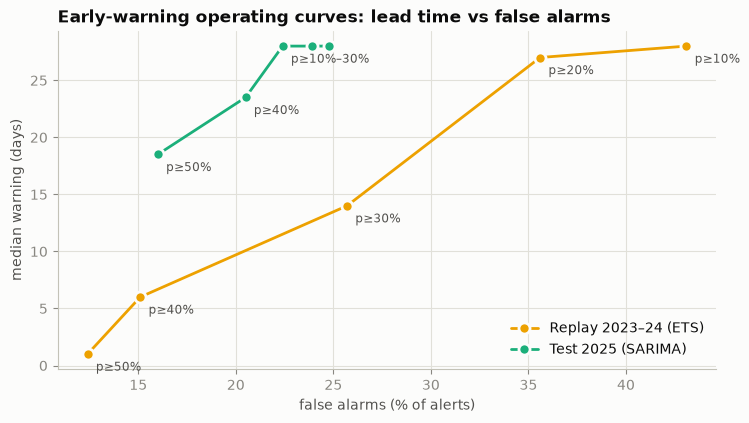

In [76]:
# Operating curves: earlier warning costs more false alarms; p* = 30% balances notice against false alarms
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for oc, name, colr in [(OC_HIST, "Replay 2023–24 (ETS)", MODEL_COLORS["ETS"]), (OC_TEST, f"Test 2025 ({champ})", MODEL_COLORS[champ])]:
    ax.plot(oc["false alarms %"], oc["median lead (days)"], color=colr, lw=2, marker="o", ms=8, mec=SURFACE, mew=2, label=name)
    pts = oc.groupby("median lead (days)").agg(fa=("false alarms %", "min"), lo=("alert at P(breach) ≥", "min"), hi=("alert at P(breach) ≥", "max"))
    for lead, r in pts.iterrows():                                              # one label per distinct point (merge saturated levels)
        txt = f"p≥{r['hi']:.0%}" if r["lo"] == r["hi"] else f"p≥{r['lo']:.0%}–{r['hi']:.0%}"
        ax.annotate(txt, (r["fa"], lead), xytext=(6, -12), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("false alarms (% of alerts)"); ax.set_ylabel("median warning (days)"); ax.legend(loc="lower right")
ax.set_title("Early-warning operating curves: lead time vs false alarms")
savefig(fig, "13a_operating_curve")

**Observation:** Both curves show that earlier warning costs more false alarms. In the test window the curve flattens at 30% (28 days' warning, 22% false alarms). In the harder replay, each step down in the trigger buys more notice but adds 3–11 percentage points of false alarms. At similar false-alarm rates the replay gives far less notice (6 days at 15% vs 18.5 days at 16% in the test), so the replay figures are the more realistic guide for a future surge.

In [77]:
# Per-event lead times at the recommended operating point p* (historical replay)
LT_HIST = lead_times(ev_hist, REPLAY_PEAKS[P_STAR], list(REPLAY_PEAKS.index))
LT_TEST = lead_times(ev_test, TEST_PEAKS[P_STAR], list(TEST_PEAKS.index))
LT_HIST

,threshold,event_date,lead_days,detected
0,6000,2023-06-29,9,True
1,6000,2024-12-02,6,True
2,6500,2023-07-12,16,True
3,6500,2024-12-17,14,True
4,7000,2023-07-19,13,True
5,7000,2024-04-24,10,True
6,7500,2023-07-25,8,True
7,7500,2024-05-01,17,True
8,7500,2024-05-30,28,True
9,8000,2023-03-21,7,True


**Observation:** At the 30% trigger all 25 historical surges were flagged, with warnings from 1 to 28 days. The large 2023 climb gave the longest notice: crossings of 10,000–11,500 children were flagged 14–28 days ahead. The shortest warnings came with abrupt jumps (8,000 on 25 Apr 2023 after a +661 rise in six days: 1 day) or at levels the census was hovering around (6,000 in Dec 2024: 6 days).

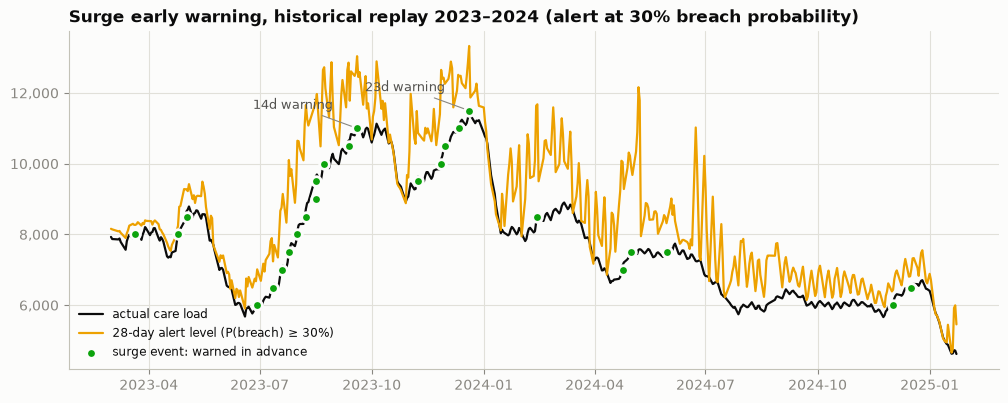

In [78]:
# Visualise the replay: care load, the real-time 28-day alert level at p*, and each surge event with its warning
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(replay_actual.index, replay_actual, color=INK, lw=1.6, label="actual care load")
ax.plot(REPLAY_PEAKS.index, REPLAY_PEAKS[P_STAR], color=MODEL_COLORS["ETS"], lw=1.6, label=f"28-day alert level (P(breach) ≥ {P_STAR:.0%})")
det, miss = LT_HIST[LT_HIST["detected"]], LT_HIST[~LT_HIST["detected"]]
ax.scatter(det["event_date"], det["threshold"], s=48, color=STATUS["good"], edgecolor=SURFACE, linewidth=2, zorder=4, label="surge event: warned in advance")
if len(miss):
    ax.scatter(miss["event_date"], miss["threshold"], s=48, color=STATUS["critical"], edgecolor=SURFACE, linewidth=2, zorder=4, label="surge event: missed")
for r in det[det["event_date"].dt.year == 2023].nlargest(2, "threshold").itertuples():
    ax.annotate(f"{r.lead_days}d warning", (r.event_date, r.threshold), xytext=(-75, 14), textcoords="offset points",
                fontsize=9, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.yaxis.set_major_formatter(COMMA); ax.legend(loc="lower left", fontsize=8.5)
ax.set_title(f"Surge early warning, historical replay 2023–2024 (alert at {P_STAR:.0%} breach probability)")
savefig(fig, "13_surge_replay")

**Observation:** In real time the alert level rises ahead of the census during each 2023 build-up, so every crossing from 6,000 to 11,500 was flagged before it happened. The alert line is jumpy in volatile periods (for example early 2024), so a single alert should be read together with the recent trend before acting.

In [79]:
# KPI 2 summary: Surge Lead Time at the recommended operating point, for both evaluations
LT_ALL = pd.concat([LT_HIST.assign(source="replay 2023–24"), LT_TEST.assign(source="test 2025")])
SURGE_LEAD = LT_ALL.groupby("source").agg(events=("lead_days", "size"), detection_rate=("detected", "mean"),
                                          median_lead_days=("lead_days", "median"), mean_lead_days=("lead_days", "mean")).round(2)
fa_at_star = {"replay 2023–24": OC_HIST, "test 2025": OC_TEST}
SURGE_LEAD["false_alarm_rate"] = SURGE_LEAD.index.map(lambda s: fa_at_star[s].set_index("alert at P(breach) ≥").at[P_STAR, "false alarms %"] / 100)
SURGE_LEAD

,events,detection_rate,median_lead_days,mean_lead_days,false_alarm_rate
source,,,,,
replay 2023–24,25,1.0,14.0,14.60,0.257
test 2025,16,1.0,28.0,24.31,0.224


**Observation:** At the recommended 30% trigger the system detected 100% of surge events in both evaluations: 25 historical events with a median 14-day warning (mean 14.6, 26% false alarms) and 16 test-window events with 28 days' warning (22% false alarms). The historical figure, about two weeks, is the realistic planning lead time.

## 14. Production forecast: 28 days beyond the last report

Every model is re-fitted on all data up to the last report. Intervals use the residual quantiles from **both** evaluation windows (the most recent 26 weeks of errors).

In [80]:
# Fit every model at the final origin and forecast 28 days ahead, then add the Ensemble
FUTURE_DATES = T_END + pd.to_timedelta(np.arange(1, H + 1), "D")
rows, PROD_MODELS = [], {}
for col, kind in TARGETS.items():
    for m in build_models(col):
        try:
            m.fit(T_END, col, kind); fit_ok = True
        except Exception as e:                                                   # logged; safe_forecast falls back to naive persistence
            FIT_LOG.append({"target": col, "model": m.name, "origin": T_END, "stage": "production fit", "error": f"{type(e).__name__}: {e}"[:200]}); fit_ok = False
        PROD_MODELS[(col, m.name)] = m
        yhat, fb = safe_forecast(m, T_END, col, kind, fit_ok)
        rows.append(pd.DataFrame({"target": col, "model": m.name, "h": np.arange(1, H + 1), "date": FUTURE_DATES, "yhat": yhat, "fallback": fb}))
FC = pd.concat(rows, ignore_index=True)
FC = pd.concat([FC, FC[FC["model"].isin(comp)].groupby(["target", "h", "date"], as_index=False)["yhat"].mean().assign(model="Ensemble", fallback=False)], ignore_index=True)
print(f"Production forecasts: {FC['model'].nunique()} models × {FC['target'].nunique()} series × {H} days | fallbacks: {int(FC['fallback'].sum())}")

Production forecasts: 8 models × 3 series × 28 days | fallbacks: 0


**Observation:** All 8 models (7 fitted at the last report plus the Ensemble) produced a 28-day path for each of the 3 series with no fallback, so the production forecast comes from exactly the implementations validated in the backtest.

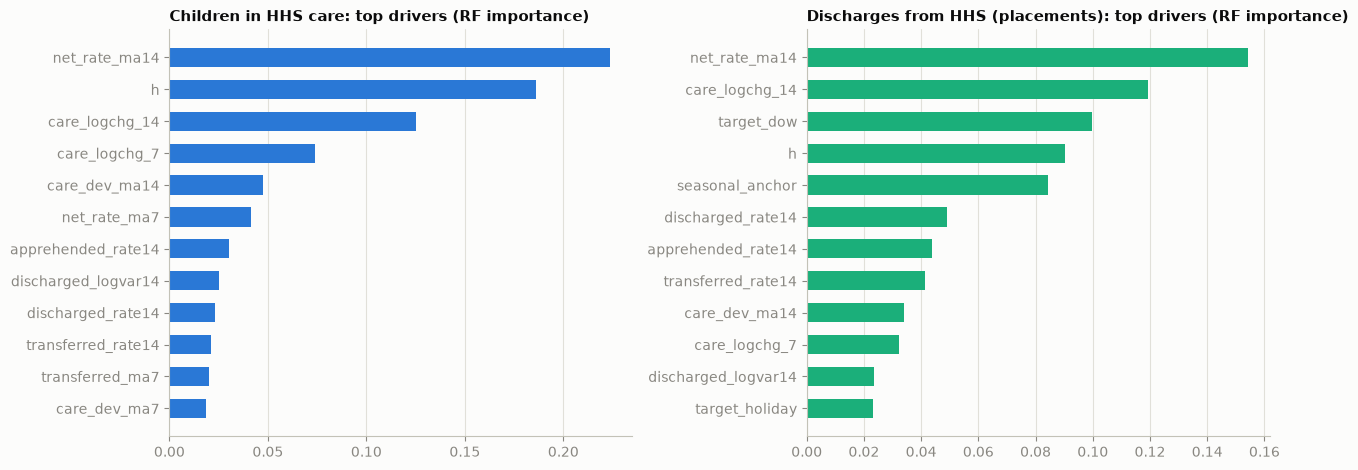

In [81]:
# What drives the ML forecasts? Top Random Forest feature importances for care load and discharges
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, col in zip(axes, ["hhs_care", "discharged"]):
    imp = pd.Series(PROD_MODELS[(col, "Random Forest")].model.feature_importances_, index=FEATURE_COLS).nlargest(12)[::-1]
    ax.barh(imp.index, imp.values, height=0.6, color=SERIES_COLORS[col])
    ax.set_title(f"{LABELS[col]}: top drivers (RF importance)", fontsize=10.5); ax.grid(axis="y", visible=False)
fig.tight_layout(); savefig(fig, "17_feature_importance")

**Observation:** For care load the 14-day net pressure (transfers − discharges per 100 children) is the top driver (22% of importance), followed by the horizon (19%) and the 14-day care-load trend (13%). Calendar features carry under 1%, so the forecast is driven by flows and momentum, not dates. For discharges the same net-pressure signal leads (15%), followed by the care-load trend (12%), weekday (10%), horizon (9%) and the same-weekday-last-week anchor (8%), matching their weekly cycle.

In [82]:
# Calibrated intervals from the last 26 weeks of walk-forward errors; flows are floored at zero
Q_ALL = residual_quantiles(S)
FC = FC.merge(Q_ALL, on=["target", "model", "h"])
for k in QUANTS:
    FC[k] = FC["yhat"] + FC[k]
    FC.loc[FC["target"] != "hhs_care", k] = FC.loc[FC["target"] != "hhs_care", k].clip(lower=0)
FC[(FC["model"] == CHAMPION["hhs_care"]) & (FC["target"] == "hhs_care") & FC["h"].isin([1, 7, 14, 21, 28])].round(0)

,target,model,h,date,yhat,fallback,lo95,lo80,hi80,hi95
84,hhs_care,SARIMA,1,2025-12-22,2487.0,False,2460.0,2472.0,2497.0,2508.0
90,hhs_care,SARIMA,7,2025-12-28,2503.0,False,2436.0,2463.0,2538.0,2561.0
97,hhs_care,SARIMA,14,2026-01-04,2519.0,False,2381.0,2456.0,2595.0,2622.0
104,hhs_care,SARIMA,21,2026-01-11,2531.0,False,2279.0,2468.0,2641.0,2663.0
111,hhs_care,SARIMA,28,2026-01-18,2542.0,False,2354.0,2486.0,2694.0,2731.0


**Observation:** SARIMA expects care load to edge up from 2,487 tomorrow to 2,542 by 18 Jan 2026 (+58 from today's 2,484, about +2 a day). The 80% band widens from 25 children on day 1 to about 207 on day 28 (2,486–2,694), so near-term numbers are firm while the 4-week figure should be planned as a range.

In [83]:
# Interval sanity checks on the production forecast (bound ordering, finiteness, width growth) and the zero floor on flows (a truncation, not a count model)
fcv = FC.assign(width80=FC["hi80"] - FC["lo80"])
checks = fcv.groupby("target").agg(
    rows=("yhat", "size"), finite=("yhat", lambda s: bool(np.isfinite(fcv.loc[s.index, ["yhat", *QUANTS]].to_numpy()).all())),
    ordered=("yhat", lambda s: bool(((fcv.loc[s.index, "lo95"] <= fcv.loc[s.index, "lo80"]) & (fcv.loc[s.index, "lo80"] <= fcv.loc[s.index, "hi80"])
                                     & (fcv.loc[s.index, "hi80"] <= fcv.loc[s.index, "hi95"])).all())),
    negative_point=("yhat", lambda s: int((s < 0).sum())),
    lo80_at_zero=("lo80", lambda s: int((s == 0).sum())), lo95_at_zero=("lo95", lambda s: int((s == 0).sum())))
w = fcv[fcv["h"].isin([1, H])].pivot_table(index="target", columns="h", values="width80", aggfunc="mean")
checks["mean width80 day 1"], checks[f"mean width80 day {H}"] = w[1].round(1), w[H].round(1)
zero_bt = BT[(BT["target"] != "hhs_care") & (BT["yhat"] == 0)].groupby(["target", "model"]).size()
print("Backtest flow point forecasts exactly at zero (by model):", zero_bt.to_dict() or "none")
checks

Backtest flow point forecasts exactly at zero (by model): {('discharged', 'Naive'): 28, ('discharged', 'Seasonal Naive (7d)'): 20, ('transferred', 'Naive'): 56, ('transferred', 'Seasonal Naive (7d)'): 36}


,rows,finite,ordered,negative_point,lo80_at_zero,lo95_at_zero,mean width80 day 1,mean width80 day 28
target,,,,,,,,
discharged,224,True,True,0,8,73,14.4,12.4
hhs_care,224,True,True,0,0,0,60.5,320.0
transferred,224,True,True,0,12,116,12.3,14.3


**Observation:** All 672 production forecasts and their bounds are finite and correctly ordered (lo95 ≤ lo80 ≤ hi80 ≤ hi95), and no point forecast is negative. Care-load 80% bands widen from 60 to 320 children between day 1 and day 28 (average over the 8 models). For the flows the zero floor binds often at the 95% level (73 of 224 discharge and 116 of 224 transfer lower bounds) but rarely at 80% (8 and 12), where the empirical errors would otherwise imply negative counts. Flooring cannot change coverage for non-negative actuals, but it is a truncation rather than a count model, so a lower flow bound of 0 means "zero or close to it". In the backtest only the two naive baselines ever forecast exactly zero, each time after a zero-count report.

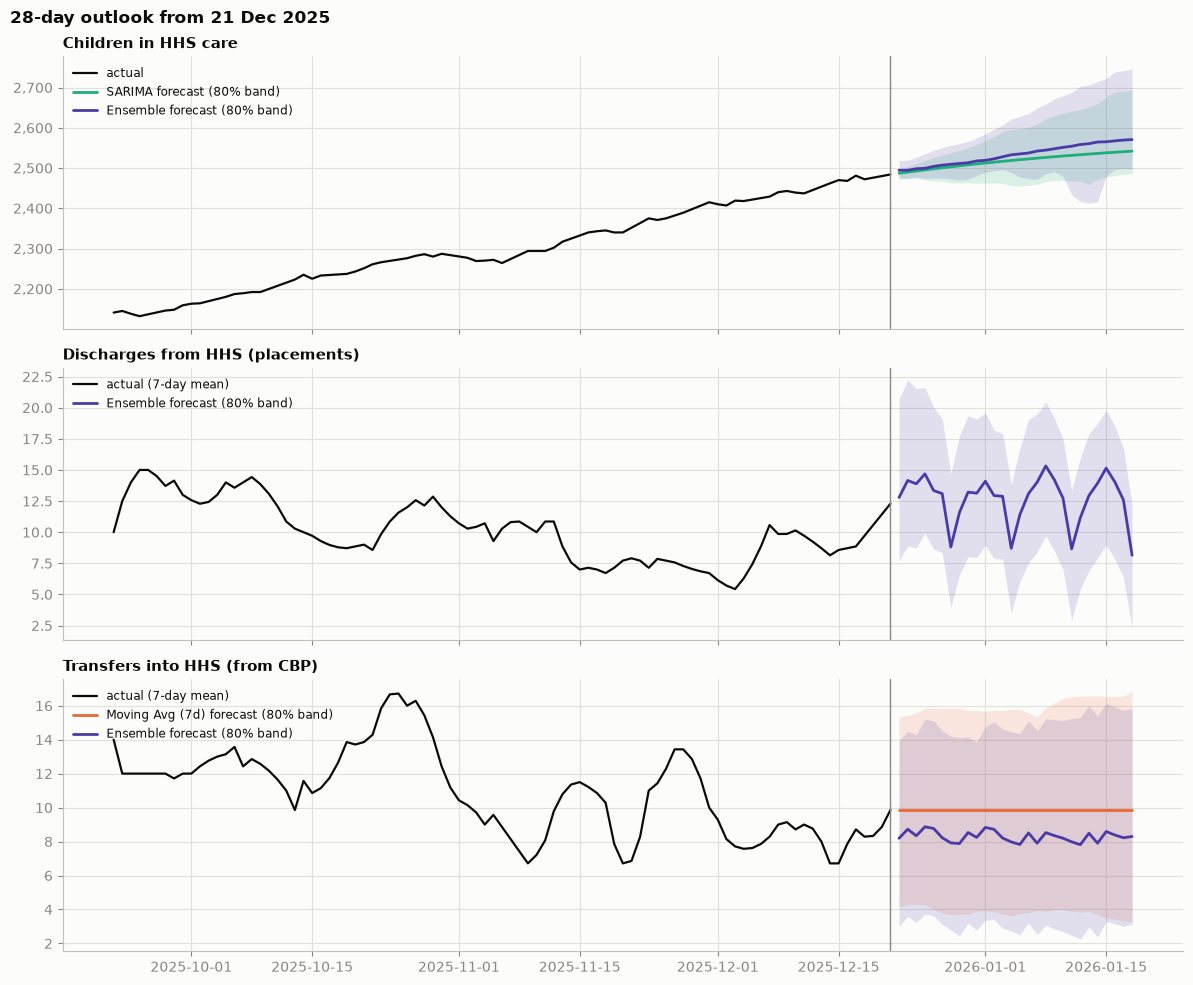

In [84]:
# Forecast dashboard view: care load (champion + ensemble) and the two flows, each with the 80% band
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, TARGETS):
    hist = daily.loc[T_END - pd.Timedelta(days=90):, col]
    ax.plot(hist.index, hist if col == "hhs_care" else hist.rolling(7, min_periods=1).mean(), color=INK, lw=1.6,
            label="actual" if col == "hhs_care" else "actual (7-day mean)")
    for m in dict.fromkeys([CHAMPION[col], "Ensemble"]):
        g = FC[(FC["target"] == col) & (FC["model"] == m)]
        ax.fill_between(g["date"], g["lo80"], g["hi80"], color=MODEL_COLORS[m], alpha=0.15, lw=0)
        ax.plot(g["date"], g["yhat"], color=MODEL_COLORS[m], lw=2, label=f"{m} forecast (80% band)")
    ax.axvline(T_END, color=MUTED, lw=1)
    ax.set_title(LABELS[col], fontsize=10.5); ax.legend(loc="upper left", fontsize=8.5)
    if col == "hhs_care":
        ax.yaxis.set_major_formatter(COMMA)
fig.suptitle(f"28-day outlook from {T_END:%d %b %Y}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); savefig(fig, "14_production_forecast")

**Observation:** Both care-load forecasts continue the climb but more slowly than the last month (+4.6/day): SARIMA reaches 2,542 and the Ensemble 2,571 by 18 Jan 2026, and their 80% bands overlap for most of their width (about 65–75% after the first week). The Ensemble expects about 12.7 discharges a day, above the last 28 days' average of about 9.4, because it follows the late-December uptick (16 and 14 on the last two reports). If placements fall back to their recent average, care load would grow faster than forecast. Transfers are expected to stay near 8 a day, in line with the recent 8.7.

In [85]:
# Future imbalance: forecast transfers vs discharges (ensemble), net pressure and the flow-implied care load (coherence check)
fin = FC[(FC["target"] == "transferred") & (FC["model"] == "Ensemble")].set_index("date")["yhat"]
fout = FC[(FC["target"] == "discharged") & (FC["model"] == "Ensemble")].set_index("date")["yhat"]
w60 = daily.loc[T_END - pd.Timedelta(days=59):]
# Reconciliation: daily care-load change NOT explained by the recorded flows (unreported weekend flows + non-CBP referrals)
RECON_PER_DAY = float((w60["hhs_care"].iloc[-1] - w60["hhs_care"].iloc[0] - w60["net_pressure"].iloc[1:].sum()) / (len(w60) - 1))
fcare_direct = FC[(FC["target"] == "hhs_care") & (FC["model"] == "Ensemble")].set_index("date")["yhat"]
fcare_flow = daily.at[T_END, "hhs_care"] + (fin - fout + RECON_PER_DAY).cumsum()
IMBALANCE = pd.DataFrame({"transfers in": fin, "discharges out": fout, "net pressure (recorded flows)": fin - fout,
                          "care (direct forecast)": fcare_direct, "care (flow-implied)": fcare_flow})
print(f"Recorded-flow net pressure: {(fin - fout).mean():+.1f}/day | reconciliation (weekend + non-CBP): {RECON_PER_DAY:+.1f}/day "
      f"| effective imbalance: {(fin - fout).mean() + RECON_PER_DAY:+.1f}/day → {((fin - fout).mean() + RECON_PER_DAY) * H:+.0f} children over {H} days")
print(f"Coherence: direct vs flow-implied care load at day 28 differ by {abs(fcare_direct.iloc[-1] - fcare_flow.iloc[-1]):.0f} children")
IMBALANCE.iloc[[0, 6, 13, 20, 27]].round(1)

Recorded-flow net pressure: -4.4/day | reconciliation (weekend + non-CBP): +3.3/day | effective imbalance: -1.0/day → -29 children over 28 days
Coherence: direct vs flow-implied care load at day 28 differ by 115 children


,transfers in,discharges out,net pressure (recorded flows),care (direct forecast),care (flow-implied)
date,,,,,
2025-12-22,8.2,12.8,-4.6,2494.5,2482.8
2025-12-28,7.9,8.8,-0.9,2509.3,2475.7
2026-01-04,8.0,8.7,-0.7,2532.8,2471.0
2026-01-11,8.0,8.7,-0.7,2554.2,2462.2
2026-01-18,8.3,8.1,0.2,2570.7,2455.4


**Observation:** The forecast flows alone imply a slight decline: recorded net pressure is −4.4/day, or −1.0/day after the +3.3/day weekend and non-CBP reconciliation, giving 2,455 on day 28 against 2,571 from the direct Ensemble forecast. Most of this 115-child gap (about 92 children, or 80%) comes from the discharge forecast: the Ensemble expects 12.7 discharges a day against a recent average of 9.4. The slightly lower transfer forecast (8.3 vs 8.7 a day) adds about 11 more. Placements are therefore the swing factor in the outlook, which is why capacity decisions should rest on intervals rather than a single line.

In [86]:
# KPI 3: Capacity Breach Probability from the empirical forecast distribution (point forecast + calibrated errors)
def breach_probability(col, model, threshold, base_path):
    errs = S[(S["target"] == col) & (S["model"] == model)]
    probs = []
    for h in range(1, H + 1):
        e = errs.loc[(errs["h"] - h).abs() <= 2, "error"].to_numpy()
        probs.append(float(np.mean(base_path[h - 1] + e > threshold)))
    return np.array(probs)


champ = CHAMPION["hhs_care"]
champ_path = FC[(FC["target"] == "hhs_care") & (FC["model"] == champ)].sort_values("h")["yhat"].to_numpy()
CURRENT = daily.at[T_END, "hhs_care"]
CAPACITY = int(np.ceil(CURRENT * 1.05 / 50) * 50)          # illustrative planning threshold: about 5% above today's load
risk_thresholds = np.arange(np.floor(CURRENT / 50) * 50, CURRENT * 1.12, 50)
probs_by_c = {c: breach_probability("hhs_care", champ, c, champ_path) for c in risk_thresholds}          # one 28-day curve per threshold
RISK = pd.DataFrame({f"day {h}": [probs_by_c[c][h - 1] for c in risk_thresholds] for h in (7, 14, 21, 28)},
                    index=pd.Index(risk_thresholds.astype(int), name="threshold")).round(3)
print(f"Current care load {CURRENT:,.0f}; illustrative capacity threshold {CAPACITY:,} (≈ +5%)")
RISK

Current care load 2,484; illustrative capacity threshold 2,650 (≈ +5%)


,day 7,day 14,day 21,day 28
threshold,,,,
2450,0.943,0.913,0.913,0.927
2500,0.632,0.752,0.831,0.882
2550,0.053,0.333,0.546,0.755
2600,0.000,0.083,0.280,0.441
2650,0.000,0.000,0.062,0.269
2700,0.000,0.000,0.000,0.069
2750,0.000,0.000,0.000,0.000


**Observation:** With today's load at 2,484, exceeding 2,500 is likely (88% by day 28), but higher thresholds are much less likely by day 28: 44% for 2,600, 27% for the illustrative 2,650 capacity, and 7% for 2,700. No threshold of 2,600 or more has any probability within the first week, so there is time to act if the trend continues.

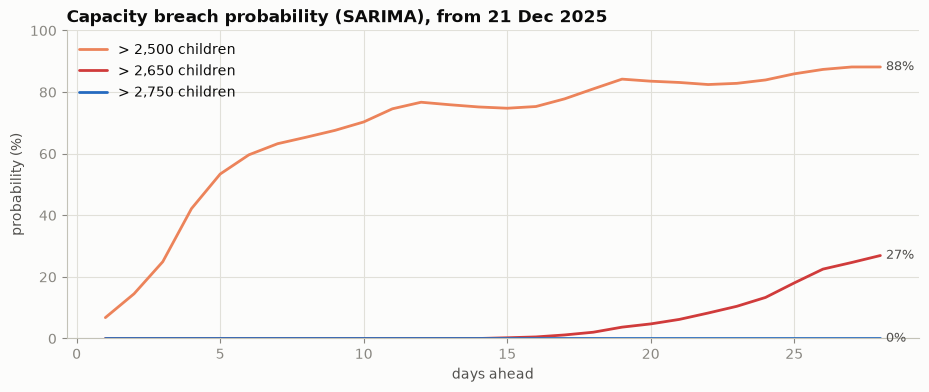

In [87]:
# Breach-probability curve over the horizon for a few thresholds (status colours carry risk, labels carry the value)
fig, ax = plt.subplots(figsize=(11, 4))
th_show = [int(CURRENT // 50 * 50 + 50), CAPACITY, CAPACITY + 100]
for c, colr in zip(th_show, [STATUS["serious"], STATUS["critical"], "#256abf"]):
    p = breach_probability("hhs_care", champ, c, champ_path)
    ax.plot(np.arange(1, H + 1), p * 100, color=colr, lw=2, label=f"> {c:,} children")
    ax.annotate(f"{p[-1]:.0%}", (H, p[-1] * 100), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_ylim(0, 100); ax.set_xlabel("days ahead"); ax.set_ylabel("probability (%)"); ax.legend(loc="upper left")
ax.set_title(f"Capacity breach probability ({champ}), from {T_END:%d %b %Y}")
savefig(fig, "15_breach_probability")

**Observation:** The probability of exceeding 2,650 stays near zero for about two weeks and reaches 27% by day 28, just below the recommended 30% alert trigger. Exceeding 2,500 passes 50% within about 5 days. A program with real capacity near 2,650 therefore has roughly two weeks of low risk before it needs to prepare, consistent with the early-warning lead times above.

## 15. Scenario analysis: stock-flow what-ifs

Scenarios change the **flows** and push the change through the identity *care(t+h) = care(t+h)_baseline + Σ(Δtransfers − Δdischarges)*. Each scenario is therefore anchored to the best direct forecast and stays physically consistent. The same engine powers the dashboard's scenario lab.

**Status of these numbers.** The baseline path is a model forecast; every other path is a **hypothetical assumption** about future flows (for example "discharges fall 30%"), not a prediction that it will happen. The capacity line is an **illustrative threshold** (≈ 5% above today's load), because the file contains no bed-capacity data. Scenario paths carry no probability of their own; the breach probabilities above apply to the model forecast only.

In [88]:
# Scenario engine (identical logic is used in the Streamlit app)
def run_scenario(base_care, base_in, base_out, in_mult=1.0, out_mult=1.0, start_day=1, extra_in=0.0):
    days = np.arange(1, len(base_care) + 1)
    active = (days >= start_day).astype(float)
    d_in = (np.asarray(base_in) * (in_mult - 1) + extra_in) * active
    d_out = np.asarray(base_out) * (out_mult - 1) * active
    return np.asarray(base_care) + np.cumsum(d_in - d_out)


base_care = FC[(FC["target"] == "hhs_care") & (FC["model"] == "Ensemble")].sort_values("h")["yhat"].to_numpy()
base_in, base_out = fin.to_numpy(), fout.to_numpy()
pre_break_in = daily.loc[ML_START:brk_transfers, "transferred"].mean()
SCENARIOS = {
    "Baseline (current trends)": dict(),
    "Discharge slowdown (−30%)": dict(out_mult=0.7),
    "Placement acceleration (+50% discharges)": dict(out_mult=1.5),
    "Intake surge (3× transfers from day 8)": dict(in_mult=3.0, start_day=8),
    "Combined stress (2× in, −25% out)": dict(in_mult=2.0, out_mult=0.75),
    f"Return to 2024 intake (~{pre_break_in:.0f}/day from day 8)": dict(extra_in=pre_break_in - base_in.mean(), start_day=8),
}
SCEN = pd.DataFrame({name: run_scenario(base_care, base_in, base_out, **kw) for name, kw in SCENARIOS.items()}, index=FUTURE_DATES)
summary = pd.DataFrame({"care load day 14": SCEN.iloc[13], "care load day 28": SCEN.iloc[-1],
                        "change vs today": SCEN.iloc[-1] - CURRENT,
                        "first day above capacity": [next((i + 1 for i, v in enumerate(SCEN[c]) if v > CAPACITY), None) for c in SCEN]}).round(0)
summary

,care load day 14,care load day 28,change vs today,first day above capacity
Baseline (current trends),2533.0,2571.0,87.0,NaN
Discharge slowdown (−30%),2586.0,2677.0,193.0,24.0
Placement acceleration (+50% discharges),2444.0,2393.0,-91.0,NaN
Intake surge (3× transfers from day 8),2650.0,2917.0,433.0,15.0
"Combined stress (2× in, −25% out)",2695.0,2892.0,408.0,12.0
Return to 2024 intake (~205/day from day 8),3913.0,6710.0,4226.0,8.0


**Observation:** Under current trends care load reaches 2,571 by day 28 (+87). A 30% slowdown in placements adds about 100 more children (2,677) and crosses 2,650 on day 24. Tripled transfers cross it on day 15, and a combined shock on day 12. A return to 2024 intake (~205/day) would add about 4,200 children within three weeks. A 50% increase in placements is the only scenario here that reverses growth (−91), so expanding placements is the clearest way to bring the census down.

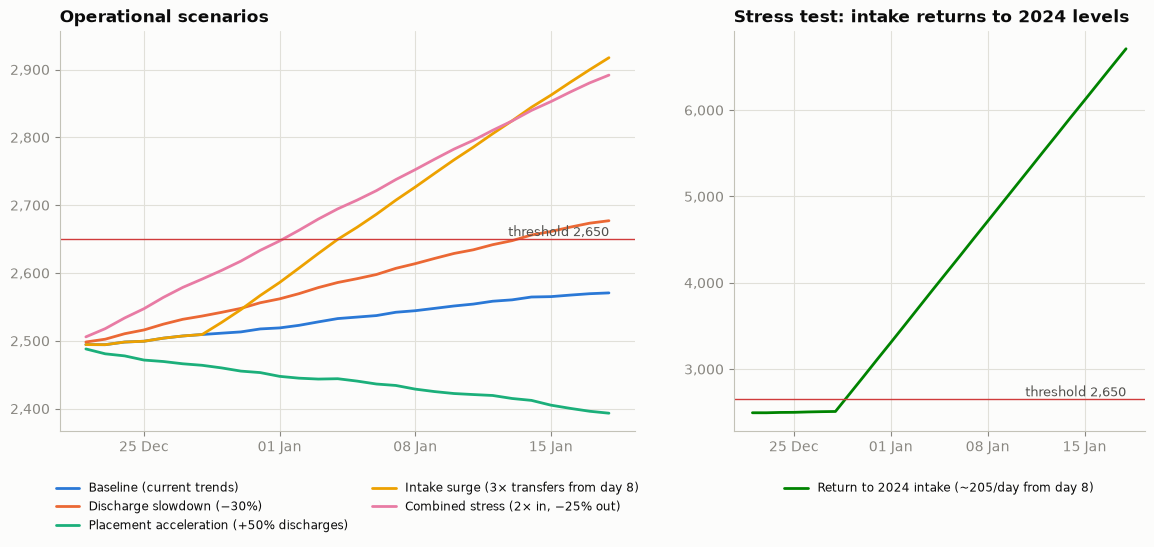

In [89]:
# Scenario comparison chart (log-free, one axis): the surge scenario dwarfs the others, so it gets its own panel
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
pal = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
for (name, colr) in zip(SCEN.columns, pal):
    ax = axes[1] if name.startswith("Return") else axes[0]
    ax.plot(SCEN.index, SCEN[name], color=colr, lw=2, label=name)
for ax in axes:
    ax.axhline(CAPACITY, color=STATUS["critical"], lw=1); ax.yaxis.set_major_formatter(COMMA)
    ax.text(FUTURE_DATES[-1], CAPACITY, f"threshold {CAPACITY:,}", color=INK2, fontsize=9, ha="right", va="bottom")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=7)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5)        # legend below the plot, off the lines
axes[0].set_ylim(top=max(CAPACITY, SCEN.drop(columns=[c for c in SCEN if c.startswith("Return")]).max().max()) + 40)
axes[0].set_title("Operational scenarios"); axes[1].set_title("Stress test: intake returns to 2024 levels")
savefig(fig, "16_scenarios")

**Observation:** The operational scenarios diverge steadily: by 18 Jan the gap between the best case (faster placements, 2,393) and the worst (tripled intake, 2,917) is about 520 children, roughly a fifth of today's census. The stress test needs its own scale: a return to 2024 intake crosses the illustrative threshold as soon as it starts and reaches 6,710 by day 28, 2.7 times today's census.

## 16. Export artifacts for the dashboard and the paper

In [90]:
# Persist clean data, backtest, metrics, forecasts, residuals and KPI metadata into artifacts/
daily.assign(regime=np.where(daily.index >= REGIME_START, "current", "pre-break")).to_csv(ART_DIR / "daily_clean.csv", index_label="date")
BT[BT["scored"]][["target", "model", "origin", "h", "date", "y", "yhat", "period"]].to_csv(ART_DIR / "backtest.csv.gz", index=False)
leader.to_csv(ART_DIR / "metrics_overall.csv", index=False)
by_h_all = S.groupby(["target", "period", "model", "h"]).apply(score).reset_index().drop(columns=["zero y excluded"]).astype({"n": int})
by_h_all.to_csv(ART_DIR / "metrics_by_horizon.csv", index=False)
coverage.reset_index().to_csv(ART_DIR / "interval_coverage.csv", index=False)
COV_BY_H.rename(columns=lambda c: c.replace(" ", "_").replace("(", "").replace(")", "")).to_csv(ART_DIR / "interval_coverage_by_h.csv", index=False)
COV_COMPARE.stack(level=0, future_stack=True).rename_axis(["target", "model", "method"]).reset_index().to_csv(ART_DIR / "interval_method_comparison.csv", index=False)
VALIDATION_ISSUES.to_csv(ART_DIR / "validation_report.csv", index=False)
pd.DataFrame(FIT_LOG, columns=["target", "model", "origin", "stage", "error"]).to_csv(ART_DIR / "model_fit_log.csv", index=False)
AUDIT.reset_index().to_csv(ART_DIR / "feature_leakage_audit.csv", index=False)
ROBUST.reset_index(names=["target", "model"]).to_csv(ART_DIR / "robustness.csv", index=False)
FC.to_csv(ART_DIR / "forecast_future.csv", index=False)
S[["target", "model", "h", "error", "period"]].to_csv(ART_DIR / "residuals.csv.gz", index=False)
LT_ALL.to_csv(ART_DIR / "surge_lead_times.csv", index=False)
pd.concat([OC_HIST.assign(source="replay 2023–24"), OC_TEST.assign(source="test 2025")]).to_csv(ART_DIR / "ews_operating_curve.csv", index=False)
(REPLAY_PEAKS[[P_STAR, 0.5]].set_axis(["peak", "peak_p50"], axis=1).rename_axis("origin")
 .join(replay_actual.rename("actual"), how="left").to_csv(ART_DIR / "surge_replay_paths.csv"))
META = {"data_end": f"{T_END:%Y-%m-%d}", "regime_start": f"{REGIME_START:%Y-%m-%d}", "break_transfers": f"{brk_transfers:%Y-%m-%d}",
        "break_discharges": f"{brk_discharges:%Y-%m-%d}", "cbp_bad_start": f"{CBP_BAD_START:%Y-%m-%d}", "cbp_bad_end": f"{CBP_BAD_END:%Y-%m-%d}",
        "cal_start": f"{CAL_START:%Y-%m-%d}", "test_start": f"{TEST_START:%Y-%m-%d}", "horizon": H, "champion": CHAMPION,
        "sarima_specs": {k: [list(v[0]), list(v[1]), v[2]] for k, v in SARIMA_SPECS.items()}, "recon_per_day": RECON_PER_DAY,
        "alert_probability": P_STAR,
        "pre_break_transfers_per_day": float(pre_break_in), "current_care_load": float(CURRENT), "capacity_default": CAPACITY,
        "stale_reports": int(stale_mask.sum()), "blank_rows": int(raw.isna().all(axis=1).sum()), "copied_cbp_reports": N_COPIED,
        "surge_lead": SURGE_LEAD.reset_index().to_dict(orient="records"),
        "accuracy_champion": {c: float(ACCURACY.loc[CHAMPION[c], c]) for c in TARGETS},
        "notebook_version": "2.0", "models": MODEL_ORDER, "model_colors": MODEL_COLORS,
        "interval_method": "empirical walk-forward error quantiles (h ± 2) from the last 26 weeks of origins, target dates observed at the forecast origin",
        "accuracy_definition": "Accuracy % = 100 - WAPE = 100 x (1 - sum|y - yhat| / sum|y|), reported days of the test window",
        "capacity_note": "No bed-capacity data in the source file: capacity_default is an illustrative threshold (about 5% above the latest care load)",
        "validation_issues": int(len(VALIDATION_ISSUES)), "fit_failures": int(len(FIT_LOG)),
        "coverage80_rolling_26wk": {c: float(COV_COMPARE.loc[(c, CHAMPION[c]), ("rolling origin (26 wk)", "coverage80")]) for c in TARGETS}}
(ART_DIR / "metadata.json").write_text(json.dumps(META, indent=2, default=str))
print("Artifacts written:", sorted(p.name for p in ART_DIR.iterdir()))
print("Figures written:", len(list(FIG_DIR.glob("*.png"))))

Artifacts written: ['backtest.csv.gz', 'daily_clean.csv', 'ews_operating_curve.csv', 'feature_leakage_audit.csv', 'forecast_future.csv', 'interval_coverage.csv', 'interval_coverage_by_h.csv', 'interval_method_comparison.csv', 'metadata.json', 'metrics_by_horizon.csv', 'metrics_overall.csv', 'model_fit_log.csv', 'residuals.csv.gz', 'robustness.csv', 'surge_lead_times.csv', 'surge_replay_paths.csv', 'validation_report.csv']
Figures written: 22


**Observation:** All 17 artifact files and 22 figures were written (v2 adds the validation report, model-fit log, feature leakage audit, coverage by horizon and the interval-method comparison). The Streamlit dashboard reads these files directly, so it always shows exactly this notebook's results, and rerunning the notebook refreshes the dashboard.

In [91]:
# One-screen KPI summary for stakeholders
kpi = pd.DataFrame({
    "Champion model": CHAMPION,
    "Forecast accuracy % (test)": {c: ACCURACY.loc[CHAMPION[c], c] for c in TARGETS},
    "MAE (test)": {c: test_board.set_index(["target", "model"]).loc[(c, CHAMPION[c]), "MAE"] for c in TARGETS},
    "80% interval coverage %": {c: coverage.loc[(c, CHAMPION[c]), "coverage80"] * 100 for c in TARGETS},
    "Stability index": {c: FSI.loc[CHAMPION[c], c] for c in TARGETS},
    "Day-28 forecast": {c: FC[(FC["target"] == c) & (FC["model"] == CHAMPION[c]) & (FC["h"] == H)]["yhat"].iloc[0] for c in TARGETS},
}).round(1)
kpi

,Champion model,Forecast accuracy % (test),MAE (test),80% interval coverage %,Stability index,Day-28 forecast
discharged,Ensemble,64.6,3.5,77.2,86.5,8.1
hhs_care,SARIMA,98.6,32.0,91.6,25.2,2541.9
transferred,Moving Avg (7d),58.8,4.2,66.0,84.3,9.9


**Observation:** Care load is forecast at 98.6% accuracy (MAE 32 children) with conservative 80% intervals (91.6% coverage). Discharges reach 64.6% (MAE 3.5/day) and transfers 58.8% (MAE 4.2/day), with transfer intervals too narrow (66% coverage). The day-28 values are 2,542 children, 8.1 discharges (18 Jan is a Sunday, the weekly low; the 28-day average is about 12.7) and 9.9 transfers (the moving-average champion). Stability is the care-load champion's main weakness (FSI 25), so decisions should rest on intervals and breach probabilities rather than a single run.

## 17. Insights & recommendations

### What the data say
1. **The raw file needs repair before it can be trusted.** 450 blank padding rows; 5 stale carried-forward HHS reports; and **251 CBP reports (12 Jan 2023 – 30 Jan 2024) copied from later dates**, proven by the broken stock-flow identity (correlation 0.51 vs 0.90 in the trusted period). The HHS columns reconcile wherever they can be checked (February 2024 onward) and are kept for the whole history.
2. **The program changed regime in early 2025.** Transfers broke on 26 Jan 2025 and discharges on 17 Feb 2025. Intake fell about 95%, average care load fell 66% (6,751 → 2,262), and the **implied length of stay rose from about 36 to about 203 days**. The binding constraint is no longer intake; it is **placement (discharge) capacity**.
3. **The weekend ratchet.** Since the current regime began (17 Mar 2025) care load rose by 373. Weekday transitions netted **−40**, while Thursday→Sunday gaps added **+323** and other multi-day reporting gaps (holidays, an outage, removed stale reports) **+90**. Even during the recent climb (1,972 on 21 Aug → 2,484), weekend and other reporting gaps account for about 70% of the growth.
4. **The recorded flows are not a complete balance.** Even between consecutive weekday reports care load rises about 3 children a day more than transfers − discharges (non-CBP admissions or definitional differences; the file has no "other admissions" or "other exits" columns). Sunday counts are single-day counts, and interpolated Friday/Saturday flows reconcile with the stock to within about 0.45 children a day in the current regime, so interpolation is acceptable for features but never scored.
5. **Validation and leakage checks pass on the real data.** No implausible value was found (the rules quarantine negative counts and stock spikes on future refreshes), the executed perturbation test found 0 leaking feature values among 40 features, and the copied-CBP block and regime breaks are identical when detected with data up to the first forecast origin only.

### How well the future can be predicted (untouched 13-week test window)
| Series | Champion (chosen on calibration) | Test MAE | vs naive | Accuracy % | Best on test |
|---|---|---|---|---|---|
| Children in HHS care | SARIMA | 32.0 children | −43% | 98.6 | Ensemble (28.5, −49%) |
| Discharges / day | Ensemble | 3.5 | −25% | 64.6 | SARIMA (3.3) |
| Transfers / day | Moving Avg (7d) | 4.2 | −17% | 58.8 | ETS (4.0) |

* **Care load:** at 4 weeks ahead the modelled error is about half of naive persistence (48–52 vs 100 children), and the gain is statistically significant at 14 and 28 days (Diebold–Mariano p < 0.05). The Ensemble beat naive in **every** test week.
* **Discharges** are close to their noise floor. With about 10 placements a day, pure Poisson randomness alone implies a mean absolute error of about 2.5, against 3.3 achieved. Plan discharge capacity on **weekly totals**: summing the reported days of each week roughly halves the relative error (16% vs 34% for SARIMA).
* **Statistical vs ML:** statistical models win on the *flows* at almost every horizon (SARIMA's discharge error is flat at about 3.3 from day 1 to day 28). ML and the Ensemble win on the *stock* at medium horizons (8–21 days). The **Ensemble is the most robust all-rounder**, which is why the dashboard defaults to it alongside each champion.
* **Early warning:** alerting when the breach probability reaches **30%** detected **all 25 historical surges with a median 14-day warning** (about 1 false alarm in 4). Alerting on the point forecast warned only about 1 day ahead.
* **Baselines and model families (v2 additions):** seasonal naive helps only for discharges (−11% vs naive) and adds nothing for the stock; weekly seasonal ARIMA terms help only for discharges (ΔAIC −11.5), and out-of-sample calibration errors confirm each AIC choice. With identical inputs, a **recursive** Gradient Boosting model beat the direct one for care load at every horizon, but not the SARIMA champion on the calibration window, so it is a candidate for the next review rather than a change now.
* **Uncertainty (v2):** the production rule (error quantiles of the last 26 weeks of forecasts already observed) was replayed in real time on the test window: care-load and discharge coverage stay near or above target, but transfer 80% coverage rises only from 66% to 68% (71% with a 13-week window). The intake interval defect **D-MOD-01 remains open**; plan intake on the 95% band. In the 2023–24 surge replay the analytic intervals kept 80% coverage during build-ups, with misses mostly on the low side.

### Outlook from 21 Dec 2025 (28 days, to 18 Jan 2026)
* Care load keeps edging up: **SARIMA 2,542 by 18 Jan (80% interval 2,486–2,694)**, Ensemble 2,571.
* Probability of exceeding **2,600** by day 28 is **44%**, above the recommended 30% alert trigger; for **2,650** it is **27%**, just below it.
* Expected flows: about 8 transfers and 8–15 discharges per day (average about 12.7). The *flow-implied* route (forecast flows plus the +3.3/day weekend/non-CBP reconciliation) points to a slight decline (2,455 on day 28, −29), while the *direct* care-load models point to +60 to +90. Most of that gap of about 115 children (about 80%) comes from the discharge forecast (12.7/day expected vs 9.4 recently), so placements are the swing factor. The flow-implied value sits inside the champion's 95% interval, which is why capacity decisions should use intervals and breach probabilities, not a single line.
* Stress tests: a 30% discharge slowdown crosses 2,650 on **day 24**; tripled intake on **day 15**; a combined shock on **day 12**. A **return to 2024 intake (~205/day) would add about 4,200 children in three weeks**. Conversely, **+50% placements reverses the growth** (−91 children in 4 weeks instead of +87).

### Recommendations for HHS planners
1. **Treat discharge capacity as the primary lever.** Expand sponsor vetting and case-management throughput; +50% placements turns growth into decline within a month.
2. **Stop the weekend ratchet.** Add weekend placement and discharge processing; weekend gaps are where most of the regime's net growth has accumulated.
3. **Adopt a probability-based trigger.** Start scaling beds and staff when the 28-day breach probability for your real capacity reaches **30%** (dashboard status "Elevated"). In the 2023–24 replay this gave a median two weeks' warning for gradual build-ups.
4. **Keep surge contingency warm.** A return to 2024-level intake would add about 4,200 children in three weeks, more than doubling today's census. Warnings averaged two weeks for gradual build-ups but were as short as 1 day for an abrupt jump (25 Apr 2023), so standby capacity should be activatable within days and the early-warning system should run on every new report.
5. **Fix the data at the source.** Publish Friday/Saturday flows (or weekend totals), publish non-CBP admissions and other exits so the population balance closes, keep the ingestion validation built here (schema, plausibility, duplicate-record and stock-flow checks) in front of every refresh, and correct the 2023 CBP records.
6. **Govern the models.** Re-estimate every 2 weeks, monitor interval coverage by horizon (intake bands are currently too narrow, so use 95%), review every calendar feature for regime leakage, and check the model-fit log after every run (a failing model silently falls back to naive persistence and is flagged).
7. **Next model review.** Evaluate a recursive care-load learner and an adaptive conformal method for intake intervals on a *new* evaluation window, with the selection rule fixed in advance.

### Limitations
* The current regime is short (~9 months). Every model will need re-validation after the next policy change.
* There is no official capacity data in the file, so thresholds here are illustrative. Planners should enter real bed capacity in the dashboard.
* The test window (Sep–Dec 2025) was a steady rise. The 2023–24 replay supplies the surge stress test but uses a univariate model, because CBP data are corrupted in that period.
* Tree-based ML models cannot extrapolate beyond the ranges they were trained on. Large shocks are therefore handled by the statistical models and the stock-flow scenario engine.
* External drivers (border events, policy announcements, sponsor-vetting rules) are not in the data. Forecasts describe the system *as it currently behaves*.
* The horizon is 28 days (four weekly cycles); 30-day forecasts were not validated. Per-horizon metrics rest on 42–55 test forecasts each, so single-horizon differences are noisy.
* Transfer (intake) 80% intervals under-cover (66–71% depending on the calibration window; D-MOD-01 open). Flow lower bounds are floored at zero, a truncation rather than a count model.
* The recorded flows leave about 3 children a day unexplained; the reconciliation term is an empirical average, not a measured flow. In 2024 interpolated weekend flows were biased, which affects only down-weighted ML training rows.
* Scenario paths are hypothetical assumptions applied to the model forecast, not predictions, and carry no probability of their own.

**Deliverables produced by this notebook:** `artifacts/` (data, backtest, metrics, forecasts, residuals, KPIs, validation report, model-fit log, feature leakage audit, coverage by horizon, interval-method comparison) feeding `uac_forecast_dashboard.py`; `figures/` used in the research paper and executive summary.